# Banking Customer Churn Prediction: Statistical Inference & Ensemble Optimization
**Author:** Muhammet Sınacı (B.Sc. in Statistics, Marmara University)  
**Study Type:** Undergraduate Graduation Thesis  

---

## 1. Executive Summary & Methodological Framework
Customer attrition (churn) is a critical risk factor in retail banking and credit card portfolio management. This study investigates the behavioral, demographic, and transactional determinants of customer churn across $N = 10,127$ credit card accounts (`BankChurners` dataset) and develops a high-precision predictive pipeline.

### Key Methodological Stages:
1. **Exploratory Data Analysis (EDA) & Distributional Diagnostics:** Evaluation of class imbalance ($83.9\%$ Retained vs. $16.1\%$ Attrited), quantile distributions, and bivariate contingency structures.
2. **Non-Parametric Outlier Winsorization:** Robust interquartile fencing using the $5^{\text{th}}$ and $95^{\text{th}}$ percentiles ($Q_{0.05}, Q_{0.95}$) to cap extreme ratio fluctuations (`Total_Amt_Chng_Q4_Q1`, `Total_Ct_Chng_Q4_Q1`) without inducing sample selection bias.
3. **Domain-Specific Feature Engineering:** Construction of behavioral ratios including `TenureYears`, `CreditLimitPerYear`, `InactiveRate`, `DependentsAgeRatio`, and `BalancePerMonth`.
4. **Statistical Hypothesis Testing & Feature Selection:** 
   - **Pearson's Chi-Square ($\chi^2$) Test of Independence** for categorical predictors.
   - **One-Way ANOVA ($F$-test)** for continuous predictors.
5. **Model Benchmarking & Bayesian Hyperparameter Optimization:** 
   - Evaluation of 8 classification algorithms via **10-Fold Cross-Validation**.
   - **Optuna Tree-structured Parzen Estimator (TPE)** over 100 trials using Stratified 5-Fold CV, optimizing LightGBM to achieve **0.9936 CV ROC-AUC** and **97.0% Test Accuracy**.

## 2. Environment Setup & Data Loading

In [7]:
import warnings
warnings.simplefilter(action="ignore")

import numpy as np
import pandas as pd

# Visualization libraries
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

pd.options.display.max_rows = None
pd.options.display.max_columns = None
pd.set_option('display.float_format', lambda x: '%.2f' % x)

In [109]:
# Load dataset and encode binary target variable:
# 1 -> Existing (Retained) Customer, 0 -> Attrited (Churned) Customer
df = pd.read_csv('BankChurners1.csv')
df['Attrition_Flag'] = df['Attrition_Flag'].replace({'Existing Customer': 1, 'Attrited Customer': 0})

In [110]:
df.head()

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,768805383,1,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.00,777,11914.00,1.33,1144,42,1.62,0.06
1,818770008,1,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.00,864,7392.00,1.54,1291,33,3.71,0.10
2,713982108,1,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.00,0,3418.00,2.59,1887,20,2.33,0.00
3,769911858,1,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.00,2517,796.00,1.41,1171,20,2.33,0.76
4,709106358,1,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.00,0,4716.00,2.17,816,28,2.50,0.00


In [111]:
# Automated function for structural DataFrame inspection
def check_df(df: pd.DataFrame,
             head: int = 5,
             tail: int = 5,
             show_info: bool = True,
             show_describe: bool = False) -> None:
    """
    Displays comprehensive structural diagnostics of the DataFrame:
      - Dimensions (shape),
      - Column data types and frequency distribution,
      - Memory footprint,
      - Missing value counts per feature,
      - First and last n observations,
      - Descriptive statistics for numerical variables.
    """
    print(f"\n>>> Shape: {df.shape}\n")
    print("############################################################################################")
    
    print(">>> Column dtypes:")
    print(df.dtypes)
    print("############################################################################################")
    print("\n>>> Dtype counts:")
    print(df.dtypes.value_counts())
    print()
    
    if show_info:
        print("############################################################################################")
        print(">>> Info:")
        df.info(memory_usage="deep")
        print()

    print("############################################################################################")
    print(">>> Missing values per column:")
    print(df.isnull().sum())
    print()

    print("############################################################################################")
    print(f">>> First {head} rows:")
    print(df.head(head))
    print("############################################################################################")
    print(f"\n>>> Last {tail} rows:")
    print(df.tail(tail))
    print()

    if show_describe:
        print("############################################################################################")
        print(">>> Describe (numeric columns):")
        print(df.describe())
        print()

check_df(df, head=3, tail=3, show_describe=True)


>>> Shape: (10127, 21)

############################################################################################
>>> Column dtypes:
CLIENTNUM                     int64
Attrition_Flag                int64
Customer_Age                  int64
Gender                       object
Dependent_count               int64
Education_Level              object
Marital_Status               object
Income_Category              object
Card_Category                object
Months_on_book                int64
Total_Relationship_Count      int64
Months_Inactive_12_mon        int64
Contacts_Count_12_mon         int64
Credit_Limit                float64
Total_Revolving_Bal           int64
Avg_Open_To_Buy             float64
Total_Amt_Chng_Q4_Q1        float64
Total_Trans_Amt               int64
Total_Trans_Ct                int64
Total_Ct_Chng_Q4_Q1         float64
Avg_Utilization_Ratio       float64
dtype: object
############################################################################################


In [112]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CLIENTNUM,10127.00,739177606.33,36903783.45,708082083.00,713036770.50,717926358.00,773143533.00,828343083.00
Attrition_Flag,10127.00,0.84,0.37,0.00,1.00,1.00,1.00,1.00
Customer_Age,10127.00,46.33,8.02,26.00,41.00,46.00,52.00,73.00
Dependent_count,10127.00,2.35,1.30,0.00,1.00,2.00,3.00,5.00
Months_on_book,10127.00,35.93,7.99,13.00,31.00,36.00,40.00,56.00
Total_Relationship_Count,10127.00,3.81,1.55,1.00,3.00,4.00,5.00,6.00
Months_Inactive_12_mon,10127.00,2.34,1.01,0.00,2.00,2.00,3.00,6.00
Contacts_Count_12_mon,10127.00,2.46,1.11,0.00,2.00,2.00,3.00,6.00
Credit_Limit,10127.00,8631.95,9088.78,1438.30,2555.00,4549.00,11067.50,34516.00
Total_Revolving_Bal,10127.00,1162.81,814.99,0.00,359.00,1276.00,1784.00,2517.00


## 3. Target Variable & Class Imbalance Analysis

In [113]:
df["Attrition_Flag"].value_counts()

Attrition_Flag
1    8500
0    1627
Name: count, dtype: int64

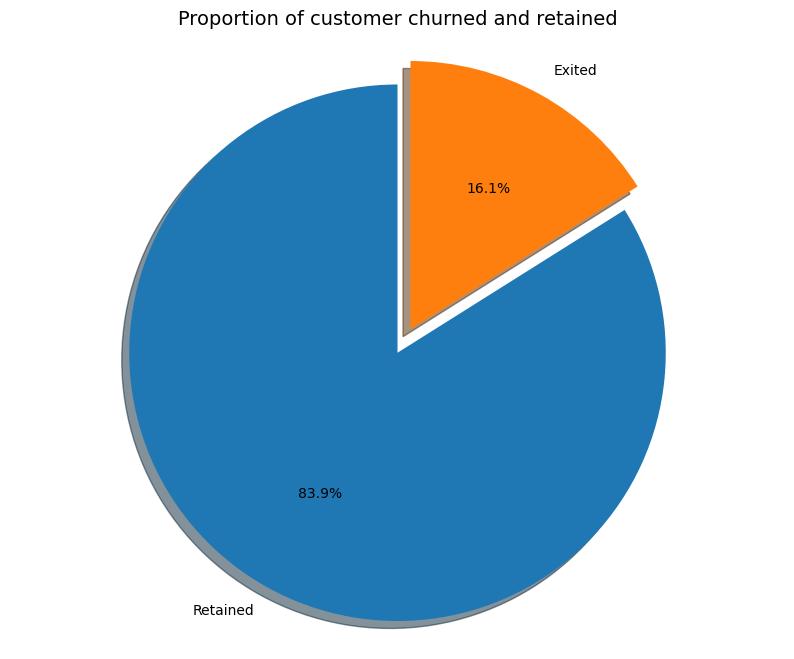

In [114]:
labels = 'Retained', 'Exited'
sizes = [df.Attrition_Flag[df['Attrition_Flag']==1].count(), df.Attrition_Flag[df['Attrition_Flag']==0].count()]
explode = (0, 0.1)
fig1, ax1 = plt.subplots(figsize=(10, 8))
ax1.pie(sizes, explode=explode, labels=labels, autopct='%1.1f%%',
        shadow=True, startangle=90)
ax1.axis('equal')
plt.title("Proportion of customer churned and retained", size = 14)
plt.show()

### Statistical Interpretation of Class Distribution
* **Class Imbalance Structure:** Out of $N = 10,127$ observed accounts, **8,500 ($83.9\%$)** are retained (`Attrition_Flag = 1`) and **1,627 ($16.1\%$)** are attrited/churned (`Attrition_Flag = 0`).
* **Evaluation Implications:** Because a naive majority-class classifier would achieve $83.9\%$ accuracy while failing to detect any churned customers, model evaluation in this study prioritizes **ROC-AUC**, **Macro F1-Score**, and class-specific **Precision/Recall** alongside Stratified Cross-Validation.

In [116]:
df.groupby("Attrition_Flag").agg(
    {
        "Customer_Age": ["mean", "std", "min", "max"],
        "Dependent_count": ["mean", "std", "min", "max"],
        "Months_on_book": ["mean", "std", "min", "max"],
        "Total_Relationship_Count": ["mean", "std", "min", "max"],
        "Months_Inactive_12_mon": ["mean", "std", "min", "max"],
        "Contacts_Count_12_mon": ["mean", "std", "min", "max"],
        "Credit_Limit": ["mean", "std", "min", "max"],
        "Total_Revolving_Bal": ["mean", "std", "min", "max"],
        "Avg_Open_To_Buy": ["mean", "std", "min", "max"],
        "Total_Amt_Chng_Q4_Q1": ["mean", "std", "min", "max"],
        "Total_Trans_Amt": ["mean", "std", "min", "max"],
        "Total_Trans_Ct": ["mean", "std", "min", "max"],
        "Total_Ct_Chng_Q4_Q1": ["mean", "std", "min", "max"],
        "Avg_Utilization_Ratio": ["mean", "std", "min", "max"],
    }
).T

Attrition_Flag                       0        1
Customer_Age             mean    46.66    46.26
                         std      7.67     8.08
                         min     26.00    26.00
                         max     68.00    73.00
Dependent_count          mean     2.40     2.34
                         std      1.28     1.30
                         min      0.00     0.00
                         max      5.00     5.00
Months_on_book           mean    36.18    35.88
                         std      7.80     8.02
                         min     13.00    13.00
                         max     56.00    56.00
Total_Relationship_Count mean     3.28     3.91
                         std      1.58     1.53
                         min      1.00     1.00
                         max      6.00     6.00
Months_Inactive_12_mon   mean     2.69     2.27
                         std      0.90     1.02
                         min      0.00     0.00
                         max      6.00     6.00
Contacts_Count_12_mon    mean     2.97     2.36
                         std      1.09     1.08
                         min      0.00     0.00
                         max      6.00     5.00
Credit_Limit             mean  8136.04  8726.88
                         std   9095.33  9084.97
                         min   1438.30  1438.30
                         max  34516.00 34516.00
Total_Revolving_Bal      mean   672.82  1256.60
                         std    921.39   757.75
                         min      0.00     0.00
                         max   2517.00  2517.00
Avg_Open_To_Buy          mean  7463.22  7470.27
                         std   9109.21  9087.67
                         min      3.00    15.00
                         max  34516.00 34516.00
Total_Amt_Chng_Q4_Q1     mean     0.69     0.77
                         std      0.21     0.22
                         min      0.00     0.26
                         max      1.49     3.40
Total_Trans_Amt          mean  3095.03  4654.66
                         std   2308.23  3512.77
                         min    510.00   816.00
                         max  10583.00 18484.00
Total_Trans_Ct           mean    44.93    68.67
                         std     14.57    22.92
                         min     10.00    11.00
                         max     94.00   139.00
Total_Ct_Chng_Q4_Q1      mean     0.55     0.74
                         std      0.23     0.23
                         min      0.00     0.03
                         max      2.50     3.71
Avg_Utilization_Ratio    mean     0.16     0.30
                         std      0.26     0.27
                         min      0.00     0.00
                         max      1.00     0.99

In [118]:
# Drop unique client identifier as it carries no statistical explanatory power
df = df.drop(["CLIENTNUM"], axis=1)
df.head()

,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,1,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.00,777,11914.00,1.33,1144,42,1.62,0.06
1,1,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.00,864,7392.00,1.54,1291,33,3.71,0.10
2,1,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.00,0,3418.00,2.59,1887,20,2.33,0.00
3,1,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.00,2517,796.00,1.41,1171,20,2.33,0.76
4,1,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.00,0,4716.00,2.17,816,28,2.50,0.00


### 3.1 Automated Feature Type Classification (Categorical vs. Numerical)

In [119]:
def grab_col_names(dataframe, cat_th=11, car_th=20):
    """
    Classifies variables into categorical, numerical, and high-cardinality lists
    based on data types and unique value thresholds.
    """
    cat_cols = [col for col in dataframe.columns if dataframe[col].dtypes == "O"]
    num_but_cat = [col for col in dataframe.columns if dataframe[col].nunique() < cat_th and
                   dataframe[col].dtypes != "O"]
    cat_but_car = [col for col in dataframe.columns if dataframe[col].nunique() > car_th and
                   dataframe[col].dtypes == "O"]
    cat_cols = cat_cols + num_but_cat
    cat_cols = [col for col in cat_cols if col not in cat_but_car]

    num_cols = [col for col in dataframe.columns if dataframe[col].dtypes != "O"]
    num_cols = [col for col in num_cols if col not in num_but_cat]

    print(f"Observations: {dataframe.shape[0]}")
    print(f"Variables: {dataframe.shape[1]}")
    print(f'cat_cols: {len(cat_cols)}')
    print(f'num_cols: {len(num_cols)}')
    print(f'cat_but_car: {len(cat_but_car)}')
    print(f'num_but_cat: {len(num_but_cat)}')
    return cat_cols, num_cols, cat_but_car

In [205]:
cat_cols, num_cols, cat_but_car = grab_col_names(df)

Observations: 10127
Variables: 20
cat_cols: 10
num_cols: 10
cat_but_car: 0
num_but_cat: 5


In [121]:
cat_cols

['Gender',
 'Education_Level',
 'Marital_Status',
 'Income_Category',
 'Card_Category',
 'Attrition_Flag',
 'Dependent_count',
 'Total_Relationship_Count',
 'Months_Inactive_12_mon',
 'Contacts_Count_12_mon']

In [122]:
num_cols

['Customer_Age',
 'Months_on_book',
 'Credit_Limit',
 'Total_Revolving_Bal',
 'Avg_Open_To_Buy',
 'Total_Amt_Chng_Q4_Q1',
 'Total_Trans_Amt',
 'Total_Trans_Ct',
 'Total_Ct_Chng_Q4_Q1',
 'Avg_Utilization_Ratio']

## 4. Univariate & Bivariate Analysis of Numerical Variables

In [124]:
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Customer_Age,10127.00,46.33,8.02,26.00,41.00,46.00,52.00,73.00
Months_on_book,10127.00,35.93,7.99,13.00,31.00,36.00,40.00,56.00
Credit_Limit,10127.00,8631.95,9088.78,1438.30,2555.00,4549.00,11067.50,34516.00
Total_Revolving_Bal,10127.00,1162.81,814.99,0.00,359.00,1276.00,1784.00,2517.00
Avg_Open_To_Buy,10127.00,7469.14,9090.69,3.00,1324.50,3474.00,9859.00,34516.00
Total_Amt_Chng_Q4_Q1,10127.00,0.76,0.22,0.00,0.63,0.74,0.86,3.40
Total_Trans_Amt,10127.00,4404.09,3397.13,510.00,2155.50,3899.00,4741.00,18484.00
Total_Trans_Ct,10127.00,64.86,23.47,10.00,45.00,67.00,81.00,139.00
Total_Ct_Chng_Q4_Q1,10127.00,0.71,0.24,0.00,0.58,0.70,0.82,3.71
Avg_Utilization_Ratio,10127.00,0.27,0.28,0.00,0.02,0.18,0.50,1.00


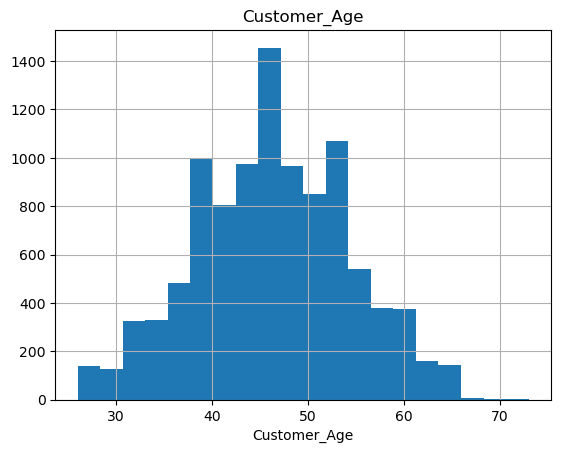

count   10127.00
mean       46.33
std         8.02
min        26.00
5%         33.00
25%        41.00
50%        46.00
75%        52.00
95%        60.00
max        73.00
Name: Customer_Age, dtype: float64


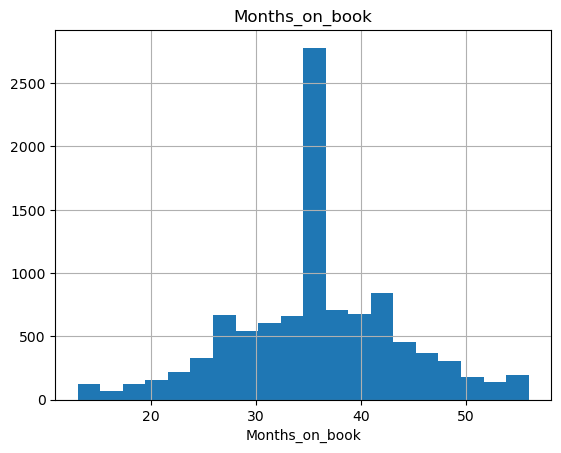

count   10127.00
mean       35.93
std         7.99
min        13.00
5%         22.00
25%        31.00
50%        36.00
75%        40.00
95%        50.00
max        56.00
Name: Months_on_book, dtype: float64


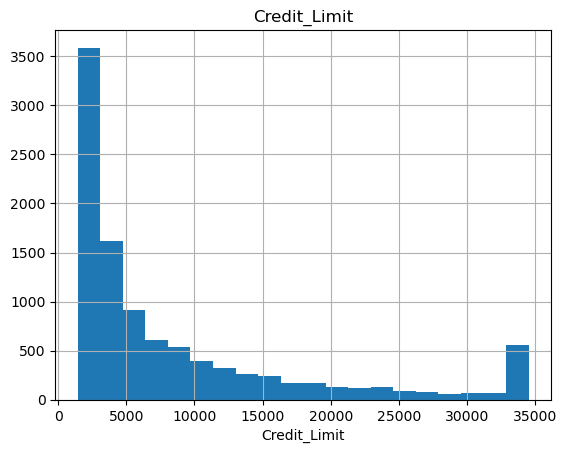

count   10127.00
mean     8631.95
std      9088.78
min      1438.30
5%       1438.51
25%      2555.00
50%      4549.00
75%     11067.50
95%     34516.00
max     34516.00
Name: Credit_Limit, dtype: float64


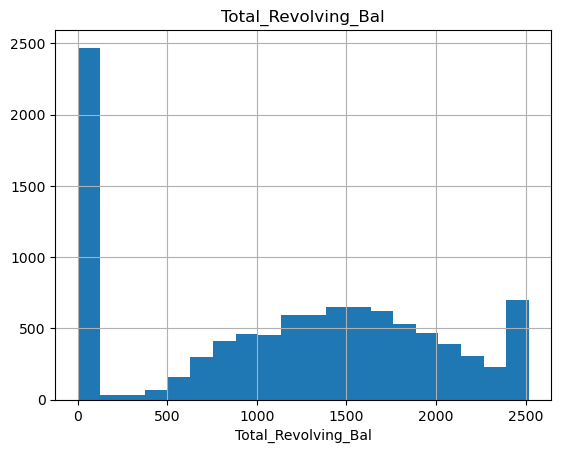

count   10127.00
mean     1162.81
std       814.99
min         0.00
5%          0.00
25%       359.00
50%      1276.00
75%      1784.00
95%      2517.00
max      2517.00
Name: Total_Revolving_Bal, dtype: float64


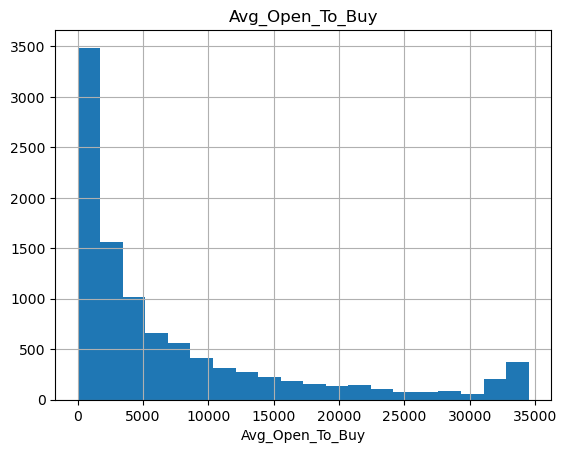

count   10127.00
mean     7469.14
std      9090.69
min         3.00
5%        480.30
25%      1324.50
50%      3474.00
75%      9859.00
95%     32183.40
max     34516.00
Name: Avg_Open_To_Buy, dtype: float64


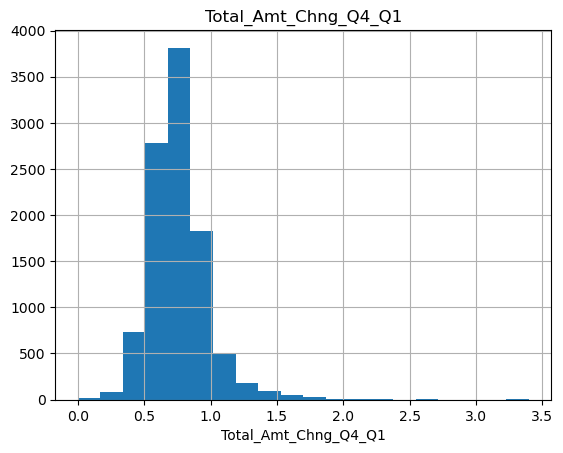

count   10127.00
mean        0.76
std         0.22
min         0.00
5%          0.46
25%         0.63
50%         0.74
75%         0.86
95%         1.10
max         3.40
Name: Total_Amt_Chng_Q4_Q1, dtype: float64


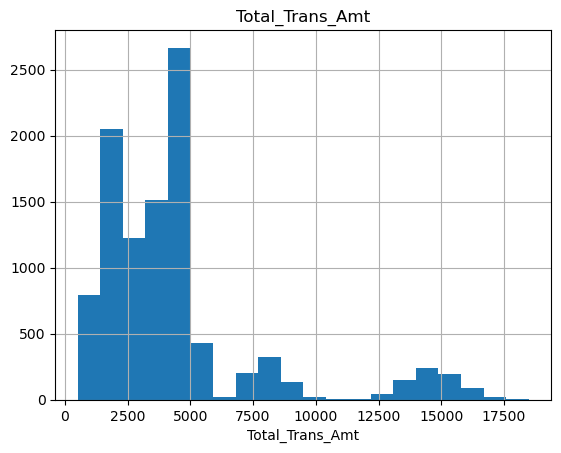

count   10127.00
mean     4404.09
std      3397.13
min       510.00
5%       1283.30
25%      2155.50
50%      3899.00
75%      4741.00
95%     14212.00
max     18484.00
Name: Total_Trans_Amt, dtype: float64


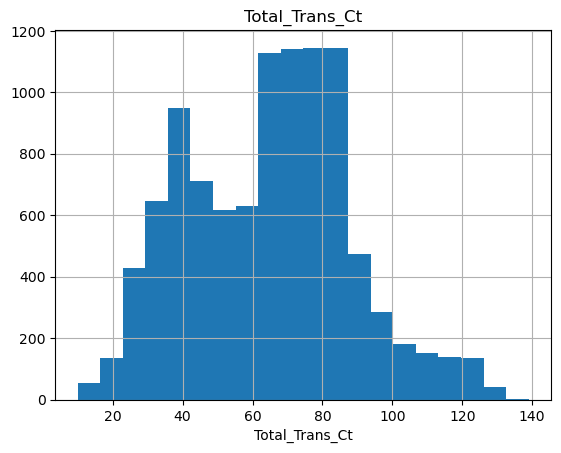

count   10127.00
mean       64.86
std        23.47
min        10.00
5%         28.00
25%        45.00
50%        67.00
75%        81.00
95%       105.00
max       139.00
Name: Total_Trans_Ct, dtype: float64


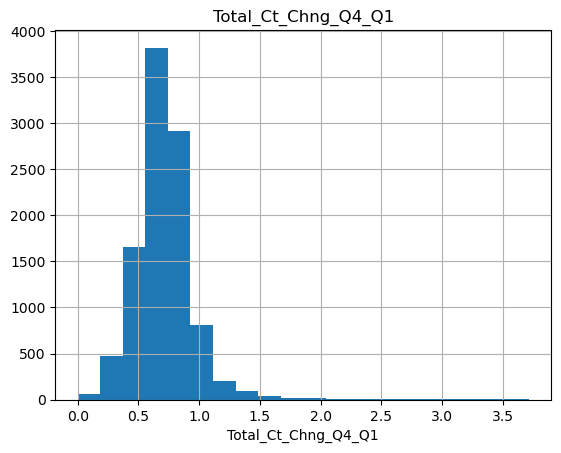

count   10127.00
mean        0.71
std         0.24
min         0.00
5%          0.37
25%         0.58
50%         0.70
75%         0.82
95%         1.07
max         3.71
Name: Total_Ct_Chng_Q4_Q1, dtype: float64


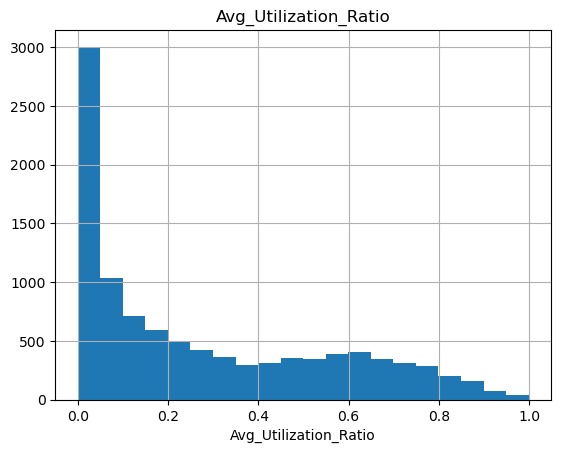

count   10127.00
mean        0.27
std         0.28
min         0.00
5%          0.00
25%         0.02
50%         0.18
75%         0.50
95%         0.79
max         1.00
Name: Avg_Utilization_Ratio, dtype: float64


In [125]:
def num_summary(dataframe, numerical_col, plot=False):
    quantiles = [0.05, 0.25, 0.50, 0.75, 0.95]

    if plot:
        dataframe[numerical_col].hist(bins=20)
        plt.xlabel(numerical_col)
        plt.title(numerical_col)
        plt.show(block=True)
        print(dataframe[numerical_col].describe(quantiles).T)

for col in num_cols:
    num_summary(df, col, plot=True)

### Distributional Findings (Numerical Predictors)
* **Demographic Symmetry:** `Customer_Age` ($\mu = 46.33, \sigma = 8.02$) and `Months_on_book` ($\mu = 35.93, \sigma = 7.99$) follow approximately symmetric, bell-shaped distributions centered around middle-aged customers with a 3-year banking tenure.
* **Right-Skewed Credit Metrics:** `Credit_Limit` (median $\$4,549$ vs. mean $\$8,631.95$) and `Avg_Open_To_Buy` exhibit strong positive skewness, reflecting a large base of standard cardholders alongside a right tail of high-limit accounts.
* **Zero-Inflated Revolving Balances:** `Total_Revolving_Bal` and `Avg_Utilization_Ratio` display bimodal/zero-inflated behavior, where a substantial subset of customers carry zero revolving balance.

### 4.1 Numerical Predictors Conditioned on Customer Attrition

In [126]:
def target_summary_with_num(dataframe,target, numerical_col):
    print(dataframe.groupby(target).agg({numerical_col:"mean"}), end="\n\n")
    print("###################################")

for col in num_cols:
    target_summary_with_num(df,"Attrition_Flag",col)

                Customer_Age
Attrition_Flag              
0                      46.66
1                      46.26

###################################
                Months_on_book
Attrition_Flag                
0                        36.18
1                        35.88

###################################
                Credit_Limit
Attrition_Flag              
0                    8136.04
1                    8726.88

###################################
                Total_Revolving_Bal
Attrition_Flag                     
0                            672.82
1                           1256.60

###################################
                Avg_Open_To_Buy
Attrition_Flag                 
0                       7463.22
1                       7470.27

###################################
                Total_Amt_Chng_Q4_Q1
Attrition_Flag                      
0                               0.69
1                               0.77

###################################
  

### Bivariate Comparison (Retained `1` vs. Attrited `0`)
* **Transaction Activity Gap:** Churned customers (`0`) exhibit substantially lower annual transaction volume (`Total_Trans_Amt`: $\$3,095.03$ vs. $\$4,654.66$) and fewer transactions (`Total_Trans_Ct`: $44.93$ vs. $68.67$) compared to retained customers (`1`).
* **Revolving Balance & Utilization:** Attrited customers hold significantly lower revolving balances ($\$672.82$ vs. $\$1,256.60$) and lower card utilization ratios ($0.16$ vs. $0.30$).
* **Quarterly Activity Momentum:** Both `Total_Amt_Chng_Q4_Q1` ($0.69$ vs. $0.77$) and `Total_Ct_Chng_Q4_Q1` ($0.55$ vs. $0.74$) are markedly lower among churned accounts, indicating that a sharp drop in Q4-to-Q1 transaction frequency is an early warning signal of attrition.
* **Demographic Invariance:** Mean `Customer_Age` ($46.66$ vs. $46.26$) and `Months_on_book` ($36.18$ vs. $35.88$) are nearly identical across both groups, suggesting that static age and tenure alone do not drive churn.

## 5. Univariate & Bivariate Analysis of Categorical Variables

In [127]:
print("Frequency Distributions of Categorical Variables")
for col in cat_cols: 
    print(df[col].value_counts(), end="\n\n")
    print("###################################")

Kategorik değişkenlerin frekansları
Gender
F    5358
M    4769
Name: count, dtype: int64

###################################
Education_Level
Graduate         3128
High School      2013
Unknown          1519
Uneducated       1487
College          1013
Post-Graduate     516
Doctorate         451
Name: count, dtype: int64

###################################
Marital_Status
Married     4687
Single      3943
Unknown      749
Divorced     748
Name: count, dtype: int64

###################################
Income_Category
Less than $40K    3561
$40K - $60K       1790
$80K - $120K      1535
$60K - $80K       1402
Unknown           1112
$120K +            727
Name: count, dtype: int64

###################################
Card_Category
Blue        9436
Silver       555
Gold         116
Platinum      20
Name: count, dtype: int64

###################################
Attrition_Flag
1    8500
0    1627
Name: count, dtype: int64

###################################
Dependent_count
3    2732
2    2655

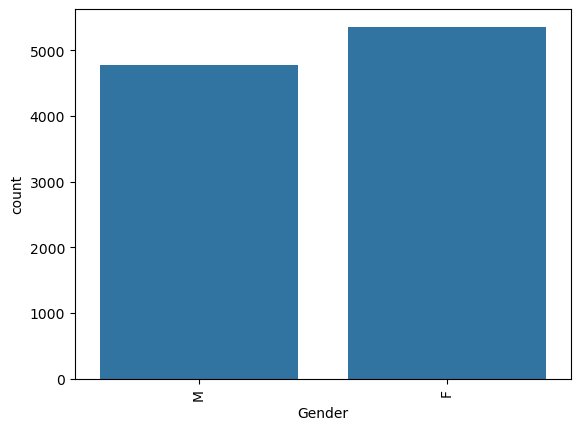

        Gender  Ratio
Gender               
F         5358  52.91
M         4769  47.09
##########################################


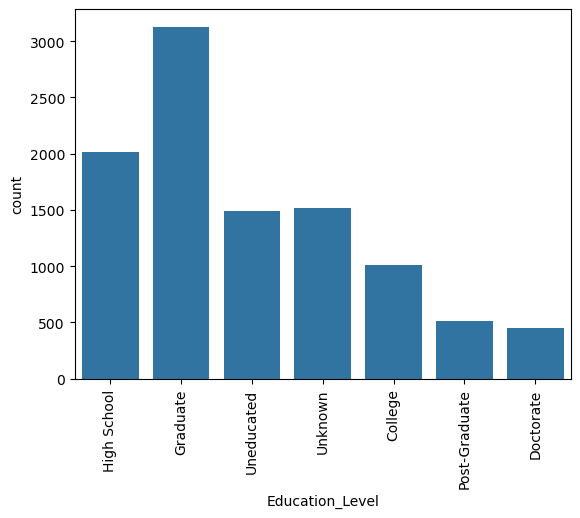

                 Education_Level  Ratio
Education_Level                        
Graduate                    3128  30.89
High School                 2013  19.88
Unknown                     1519  15.00
Uneducated                  1487  14.68
College                     1013  10.00
Post-Graduate                516   5.10
Doctorate                    451   4.45
##########################################


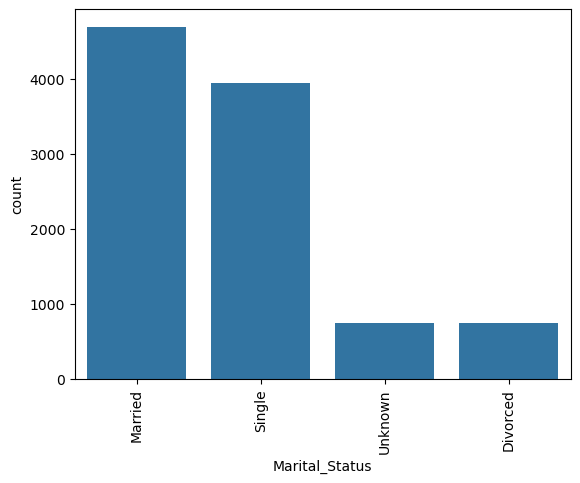

                Marital_Status  Ratio
Marital_Status                       
Married                   4687  46.28
Single                    3943  38.94
Unknown                    749   7.40
Divorced                   748   7.39
##########################################


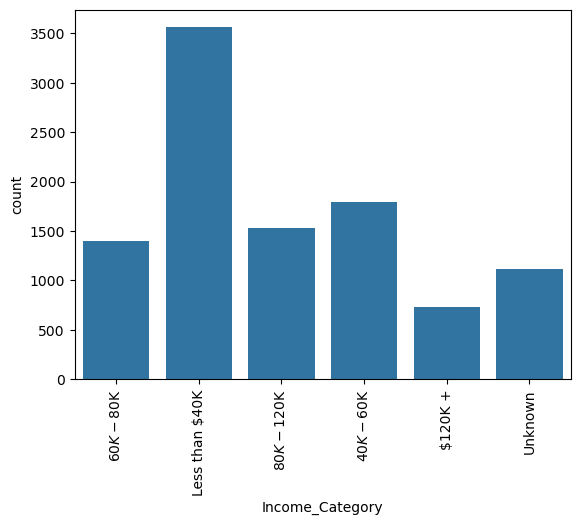

                 Income_Category  Ratio
Income_Category                        
Less than $40K              3561  35.16
$40K - $60K                 1790  17.68
$80K - $120K                1535  15.16
$60K - $80K                 1402  13.84
Unknown                     1112  10.98
$120K +                      727   7.18
##########################################


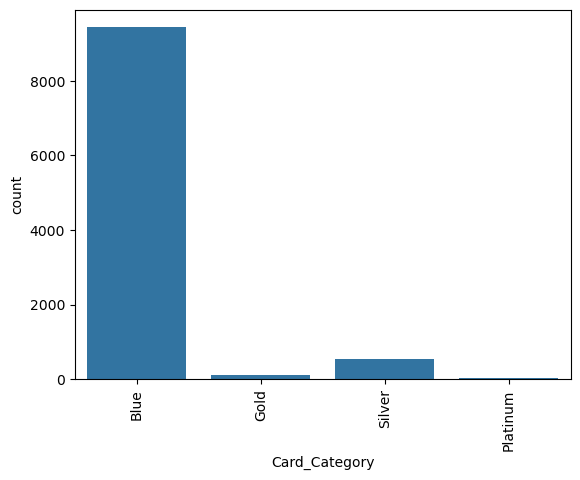

               Card_Category  Ratio
Card_Category                      
Blue                    9436  93.18
Silver                   555   5.48
Gold                     116   1.15
Platinum                  20   0.20
##########################################


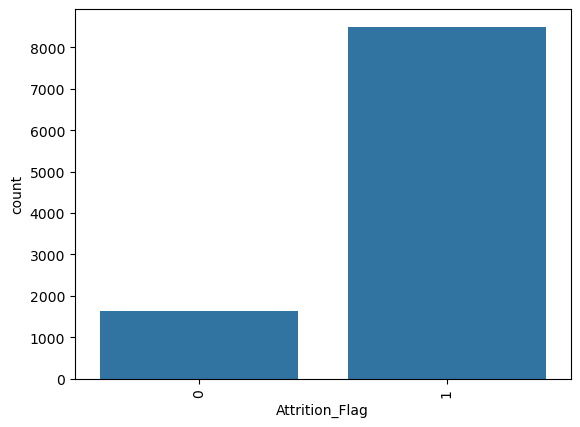

                Attrition_Flag  Ratio
Attrition_Flag                       
1                         8500  83.93
0                         1627  16.07
##########################################


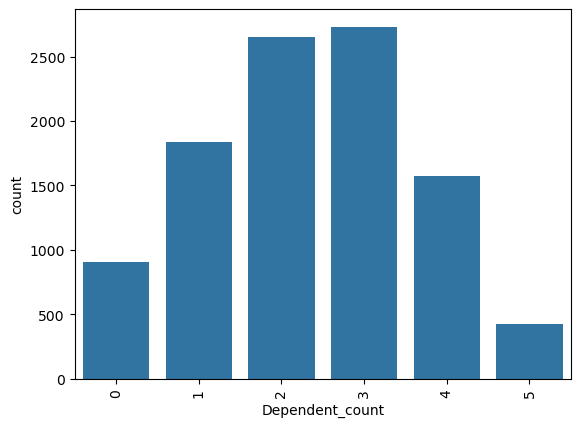

                 Dependent_count  Ratio
Dependent_count                        
3                           2732  26.98
2                           2655  26.22
1                           1838  18.15
4                           1574  15.54
0                            904   8.93
5                            424   4.19
##########################################


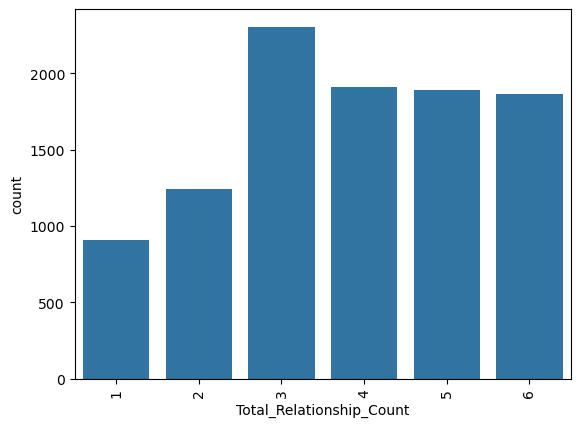

                          Total_Relationship_Count  Ratio
Total_Relationship_Count                                 
3                                             2305  22.76
4                                             1912  18.88
5                                             1891  18.67
6                                             1866  18.43
2                                             1243  12.27
1                                              910   8.99
##########################################


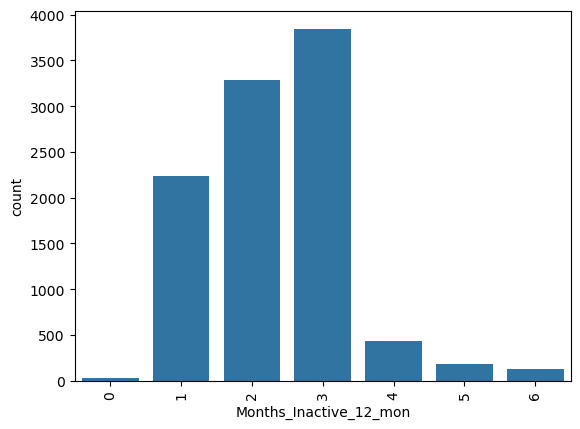

                        Months_Inactive_12_mon  Ratio
Months_Inactive_12_mon                               
3                                         3846  37.98
2                                         3282  32.41
1                                         2233  22.05
4                                          435   4.30
5                                          178   1.76
6                                          124   1.22
0                                           29   0.29
##########################################


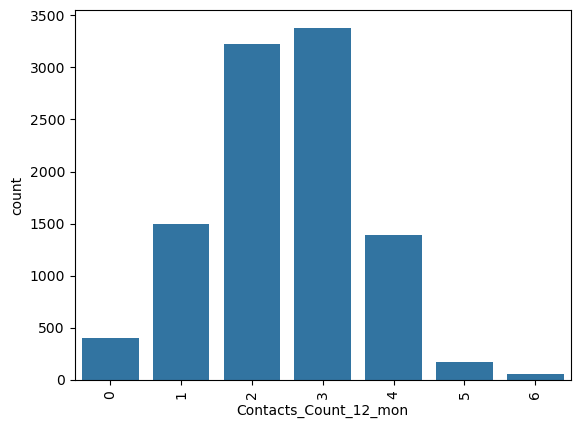

                       Contacts_Count_12_mon  Ratio
Contacts_Count_12_mon                              
3                                       3380  33.38
2                                       3227  31.87
1                                       1499  14.80
4                                       1392  13.75
0                                        399   3.94
5                                        176   1.74
6                                         54   0.53
##########################################


In [129]:
def cat_summary(dataframe, col_name, plot=False):
    
    if plot:
        sns.countplot(x=dataframe[col_name], data=dataframe)
        plt.xticks(rotation=90) 
        plt.show(block=True)
        print(pd.DataFrame({col_name: dataframe[col_name].value_counts(),
                        "Ratio": 100 * dataframe[col_name].value_counts() / len(dataframe)}))
        print("##########################################")


for col in cat_cols:
    cat_summary(df, col,plot=True)

### Distributional Findings (Categorical Predictors)
* **Card Tier Dominance:** Over $93.2\%$ of the portfolio consists of `Blue` cardholders ($9,436$ accounts), followed by `Silver` ($5.5\%$), `Gold` ($1.1\%$), and `Platinum` ($0.2\%$).
* **Demographic Profile:** The sample is balanced by gender ($52.9\%$ Female, $47.1\%$ Male), with `Graduate` ($30.9\%$) and `High School` ($19.9\%$) representing the largest education segments, and `Less than $40K` ($35.2\%$) forming the largest income bracket.

### 5.1 Retention & Attrition Rates Across Categorical Segments

In [130]:
def target_summary_with_cat(dataframe, target, categorical_col):
    print(categorical_col)
    print(pd.DataFrame({"Retention Rate (Mean)": dataframe.groupby(categorical_col)[target].mean(),
                        "Count": dataframe[categorical_col].value_counts(),
                        "Ratio": 100 * dataframe[categorical_col].value_counts() / len(dataframe)}), end="\n\n\n")

for col in cat_cols:
    target_summary_with_cat(df, "Attrition_Flag", col)

Gender
        Churn Mean  Count  Ratio
Gender                          
F             0.83   5358  52.91
M             0.85   4769  47.09


Education_Level
                 Churn Mean  Count  Ratio
Education_Level                          
College                0.85   1013  10.00
Doctorate              0.79    451   4.45
Graduate               0.84   3128  30.89
High School            0.85   2013  19.88
Post-Graduate          0.82    516   5.10
Uneducated             0.84   1487  14.68
Unknown                0.83   1519  15.00


Marital_Status
                Churn Mean  Count  Ratio
Marital_Status                          
Divorced              0.84    748   7.39
Married               0.85   4687  46.28
Single                0.83   3943  38.94
Unknown               0.83    749   7.40


Income_Category
                 Churn Mean  Count  Ratio
Income_Category                          
$120K +                0.83    727   7.18
$40K - $60K            0.85   1790  17.68
$60K - $80K     

### Bivariate Categorical Insights
* **Customer Service Contact Frequency (`Contacts_Count_12_mon`):** Accounts with **6 contacts** in the last 12 months have a $0\%$ retention rate ($100\%$ churn across all 54 customers), and those with **4 contacts** show a $68.5\%$ retention rate ($31.5\%$ churn). Frequent contact with bank support strongly signals unresolved dissatisfaction.
* **Inactivity Duration (`Months_Inactive_12_mon`):** Retention drops sharply when inactivity reaches 3–4 months ($70.1\%$ retention at 4 months inactive vs. $89.9\%$ at 1 month inactive).
* **Product Depth (`Total_Relationship_Count`):** Customers holding only 1 or 2 products exhibit much higher churn (retention rates of $74.4\%$ and $72.2\%$) compared to customers holding 4 to 6 products (retention rates $>87\%$).

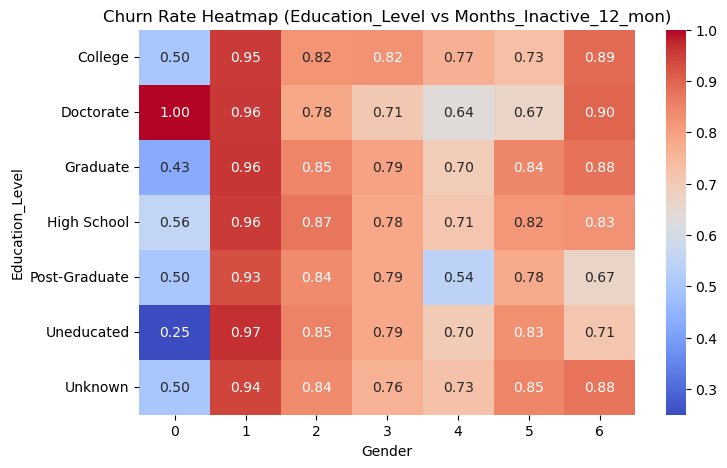

In [132]:
df.groupby(["Education_Level", "Months_Inactive_12_mon"]).agg({"Attrition_Flag" : "mean"})

pivot = df.groupby(["Education_Level", "Months_Inactive_12_mon"])["Attrition_Flag"].mean().unstack()

plt.figure(figsize=(8, 5))
sns.heatmap(pivot, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Retention Rate Heatmap (Education_Level vs Months_Inactive_12_mon)")
plt.ylabel("Education_Level")
plt.xlabel("Months_Inactive_12_mon")
plt.show()

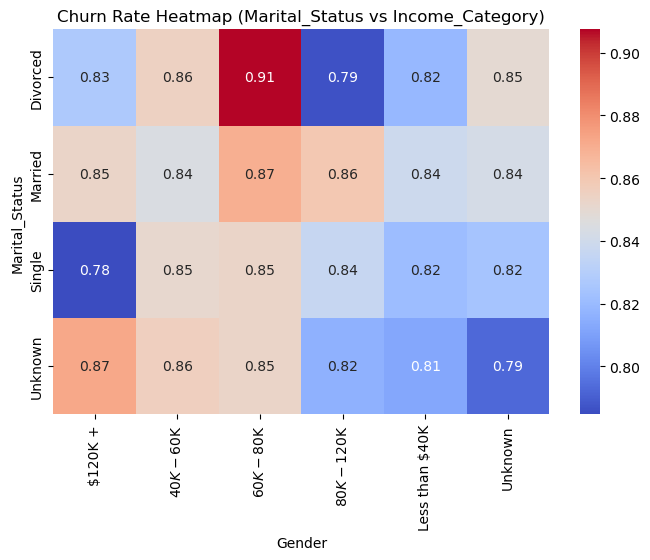

In [133]:
df.groupby(["Marital_Status", "Income_Category"]).agg({"Attrition_Flag" : "mean"})

pivot = df.groupby(["Marital_Status", "Income_Category"])["Attrition_Flag"].mean().unstack()

plt.figure(figsize=(8, 5))
sns.heatmap(pivot, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Retention Rate Heatmap (Marital_Status vs Income_Category)")
plt.ylabel("Marital_Status")
plt.xlabel("Income_Category")
plt.show()

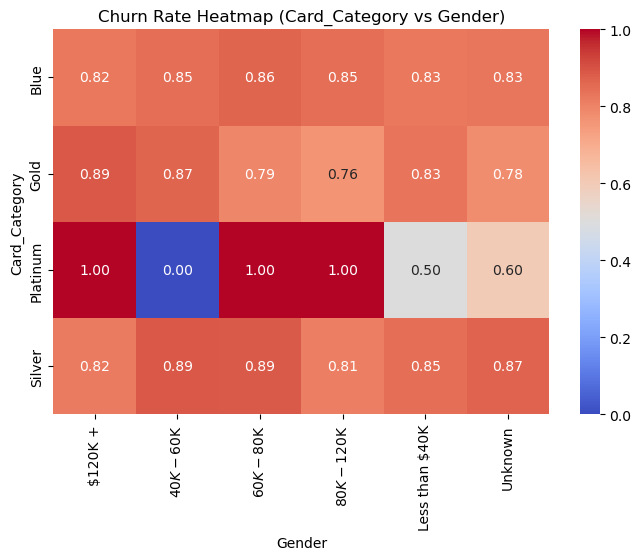

In [134]:
df.groupby(["Card_Category", "Income_Category"]).agg({"Attrition_Flag" : "mean"})

pivot = df.groupby(["Card_Category", "Income_Category"])["Attrition_Flag"].mean().unstack()

plt.figure(figsize=(8, 5))
sns.heatmap(pivot, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Retention Rate Heatmap (Card_Category vs Income_Category)")
plt.ylabel("Card_Category")
plt.xlabel("Income_Category")
plt.show()

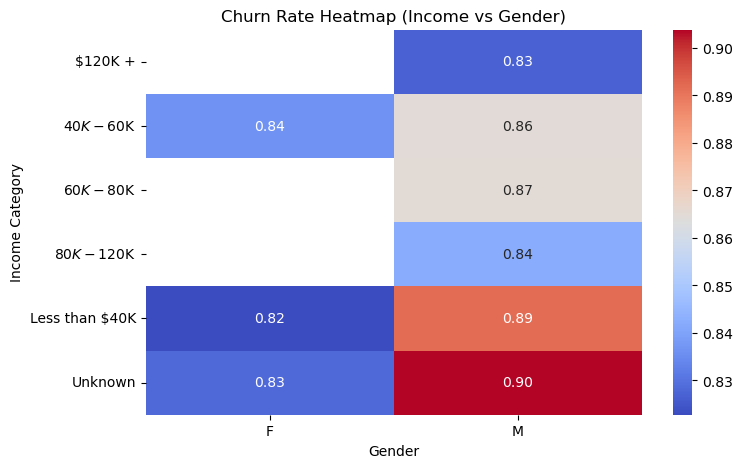

In [135]:
pivot = df.groupby(["Income_Category", "Gender"])["Attrition_Flag"].mean().unstack()

plt.figure(figsize=(8, 5))
sns.heatmap(pivot, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Churn Rate Heatmap (Income vs Gender)")
plt.ylabel("Income Category")
plt.xlabel("Gender")
plt.show()

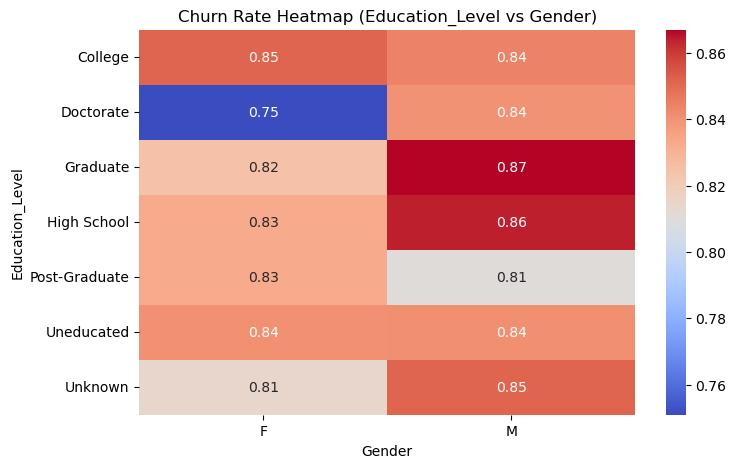

In [136]:
pivot = df.groupby(["Education_Level", "Gender"])["Attrition_Flag"].mean().unstack()

plt.figure(figsize=(8, 5))
sns.heatmap(pivot, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Churn Rate Heatmap (Education_Level vs Gender)")
plt.ylabel("Education_Level")
plt.xlabel("Gender")
plt.show()

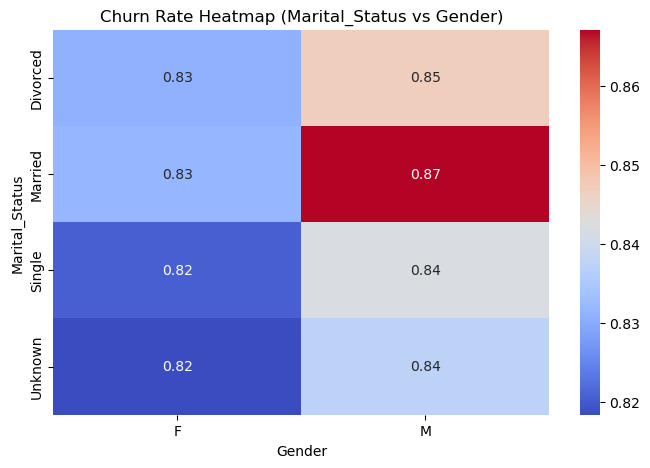

In [137]:
pivot = df.groupby(["Marital_Status", "Gender"])["Attrition_Flag"].mean().unstack()

plt.figure(figsize=(8, 5))
sns.heatmap(pivot, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Churn Rate Heatmap (Marital_Status vs Gender)")
plt.ylabel("Marital_Status")
plt.xlabel("Gender")
plt.show()

## 6. Multi-Dimensional Data Visualization

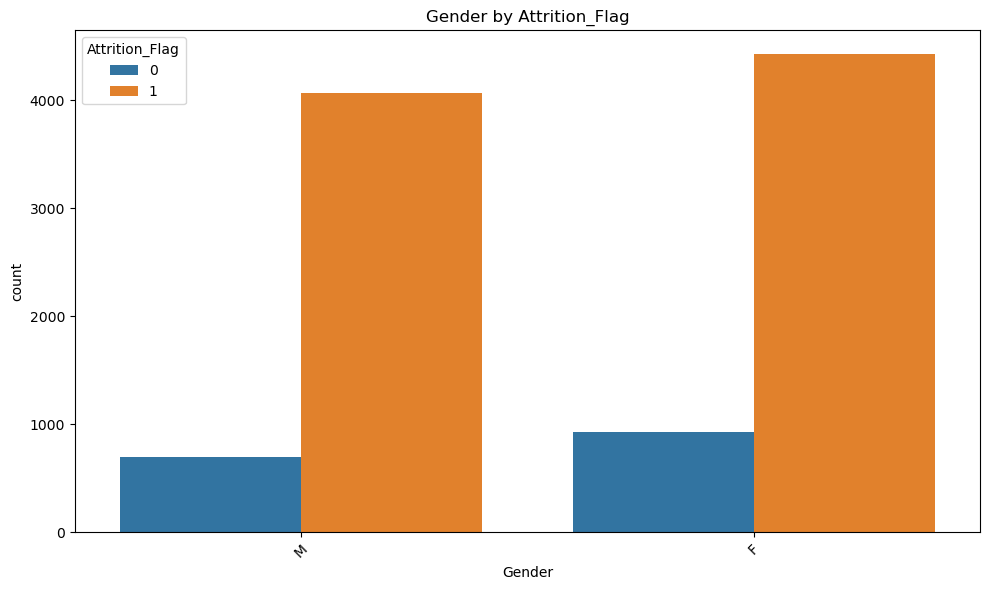

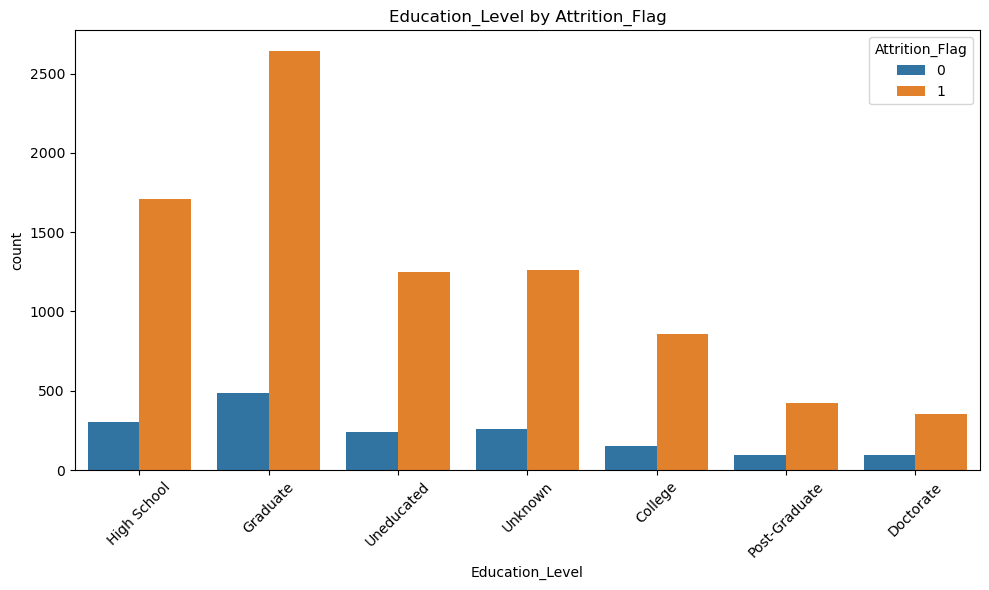

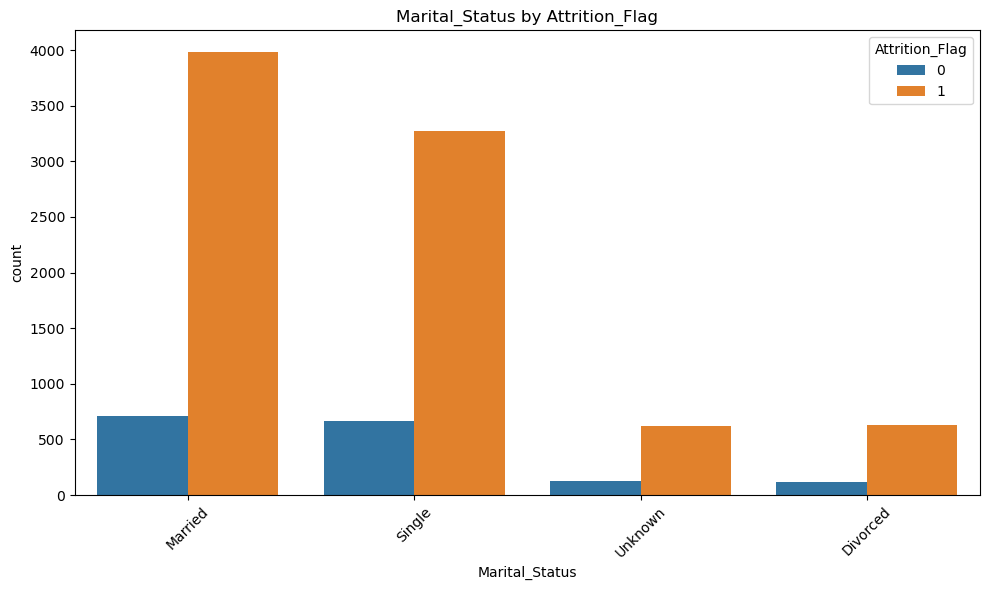

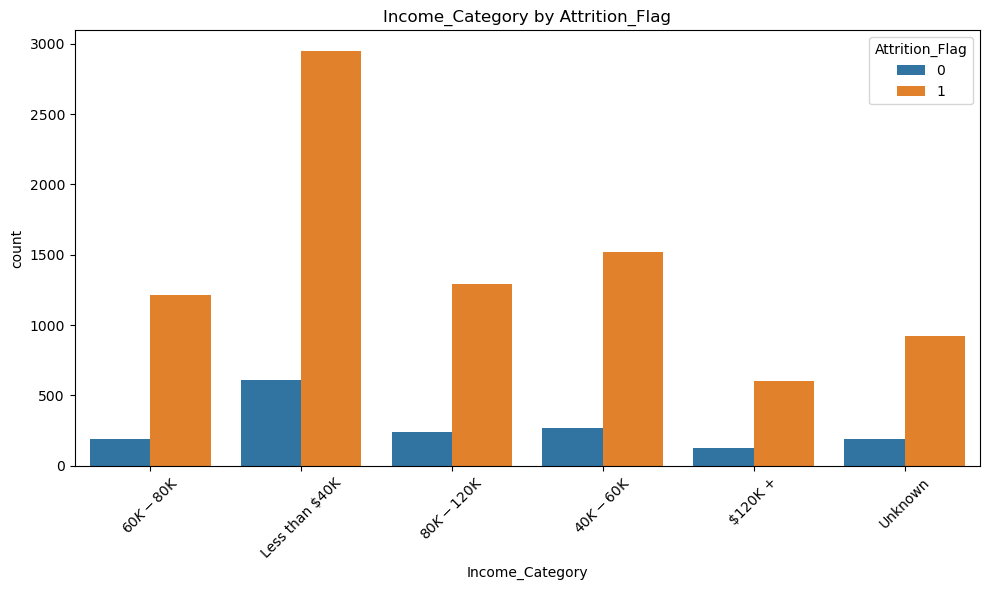

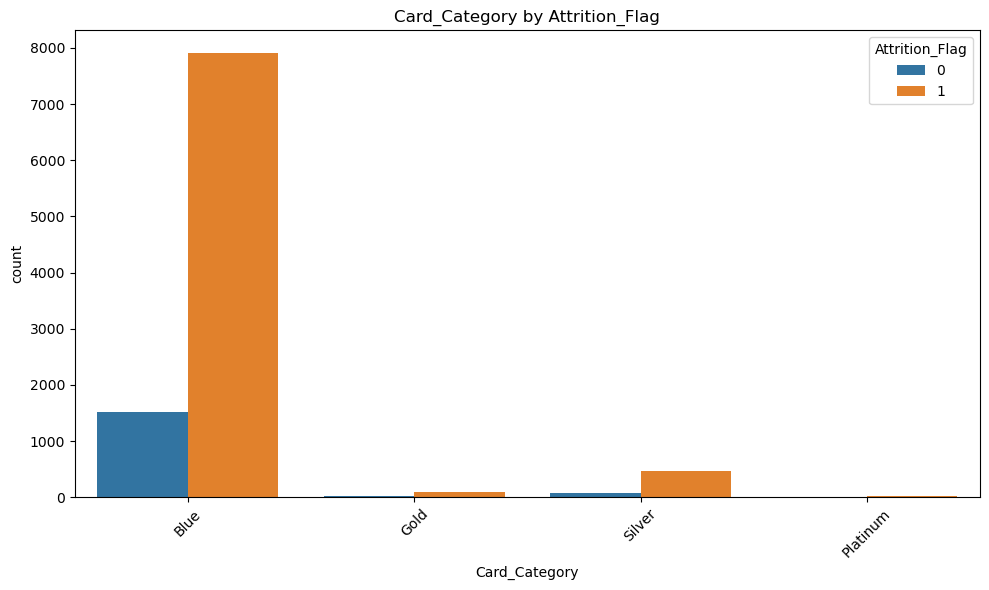

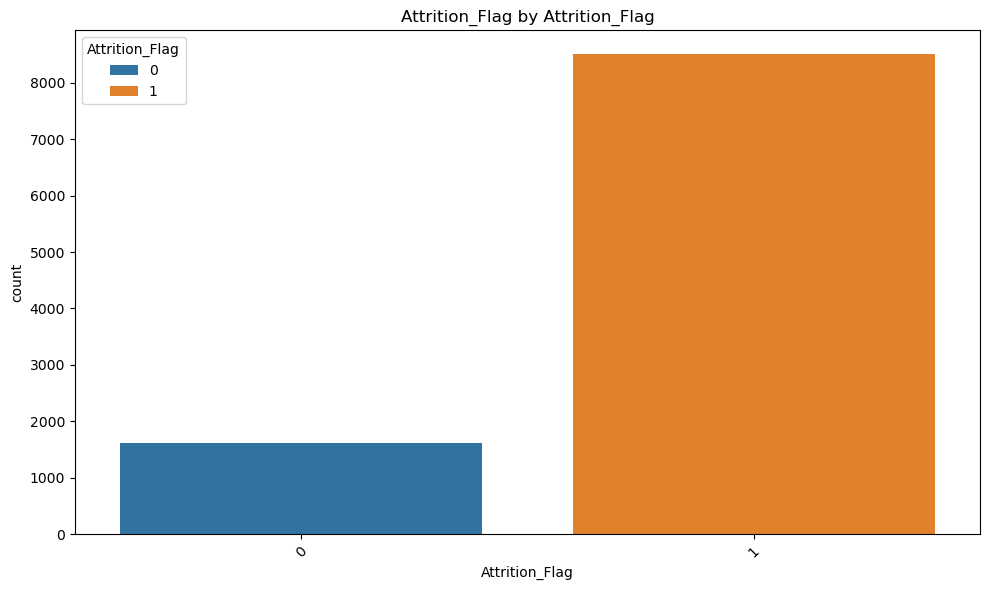

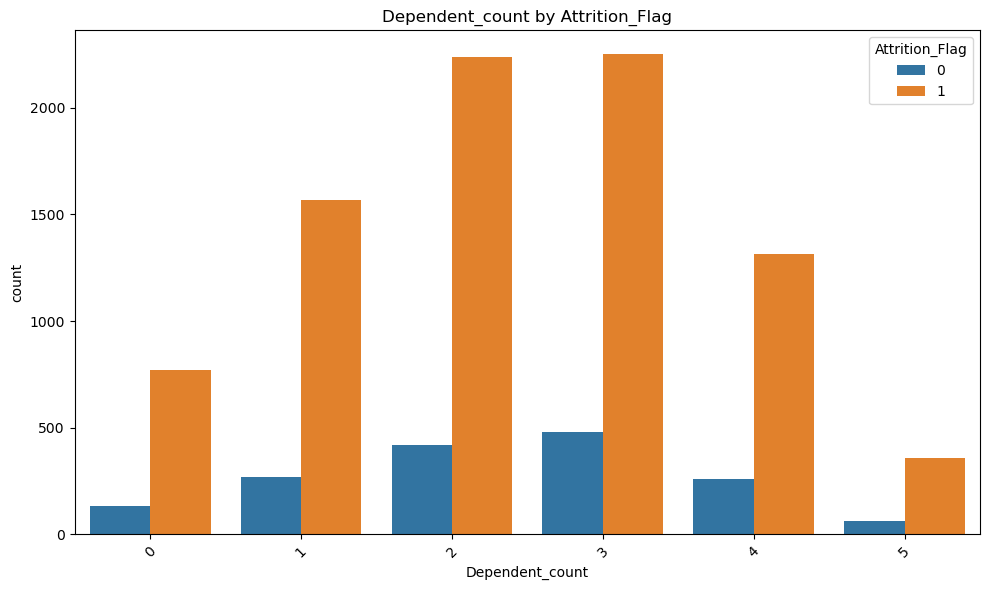

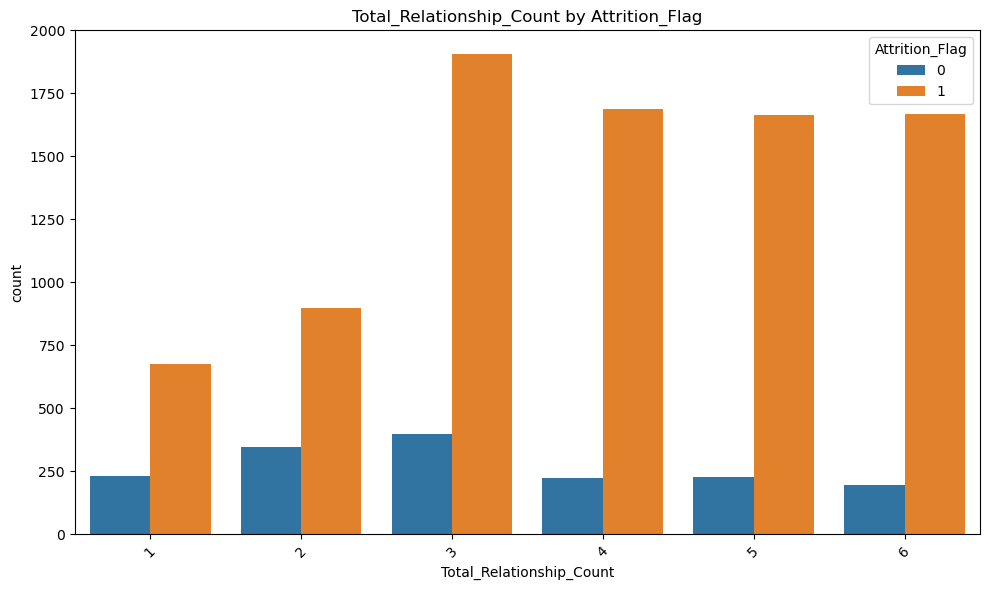

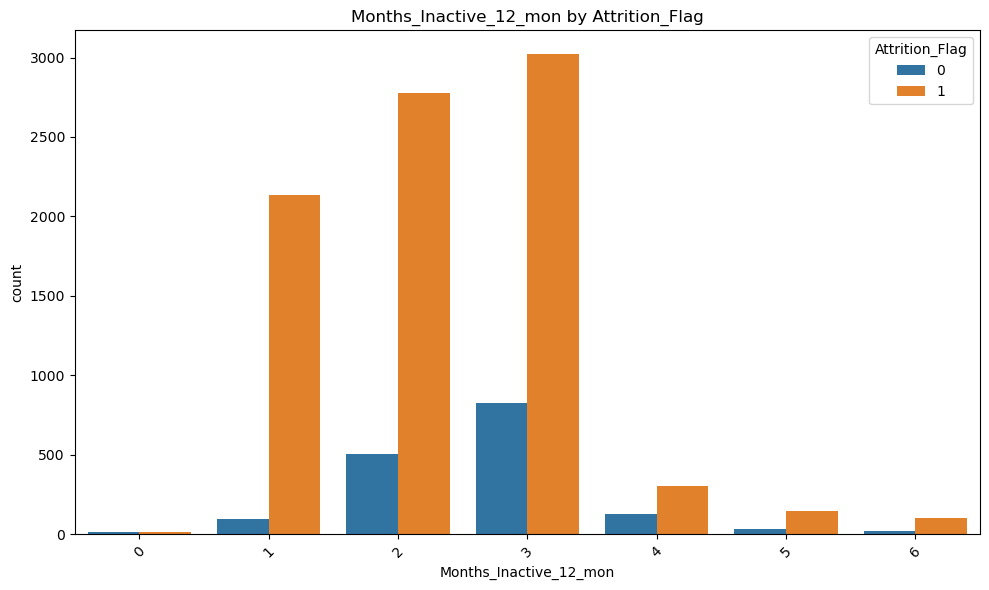

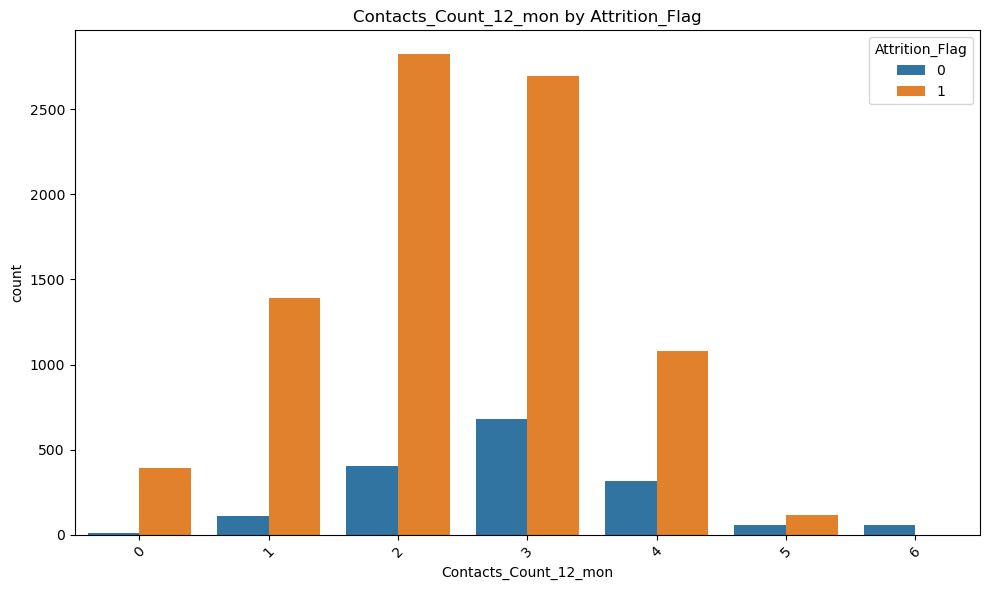

In [139]:
def plot_countplots_separate(df, cols, hue='Attrition_Flag', figsize=(8, 6)):
    """
    Generates separate countplots for each categorical variable stratified by the target variable.
    """
    for col in cols:
        fig, ax = plt.subplots(figsize=figsize)
        sns.countplot(x=col, hue=hue, data=df, ax=ax)
        ax.set_title(f"{col} by {hue}")
        ax.tick_params(axis='x', rotation=45)
        plt.tight_layout()
        plt.show()

plot_countplots_separate(df, cat_cols, hue='Attrition_Flag', figsize=(10, 6))

### Visual Insights from Stratified Countplots
* **Inactivity & Contact Concentration:** Attrited accounts (`0`) cluster heavily at 2–3 months of inactivity and 3–4 customer service contacts over the trailing 12-month window.
* **Relationship Depth:** Multi-product holders (`Total_Relationship_Count` $\ge 4$) demonstrate strong retention resilience compared to single- or dual-product users.

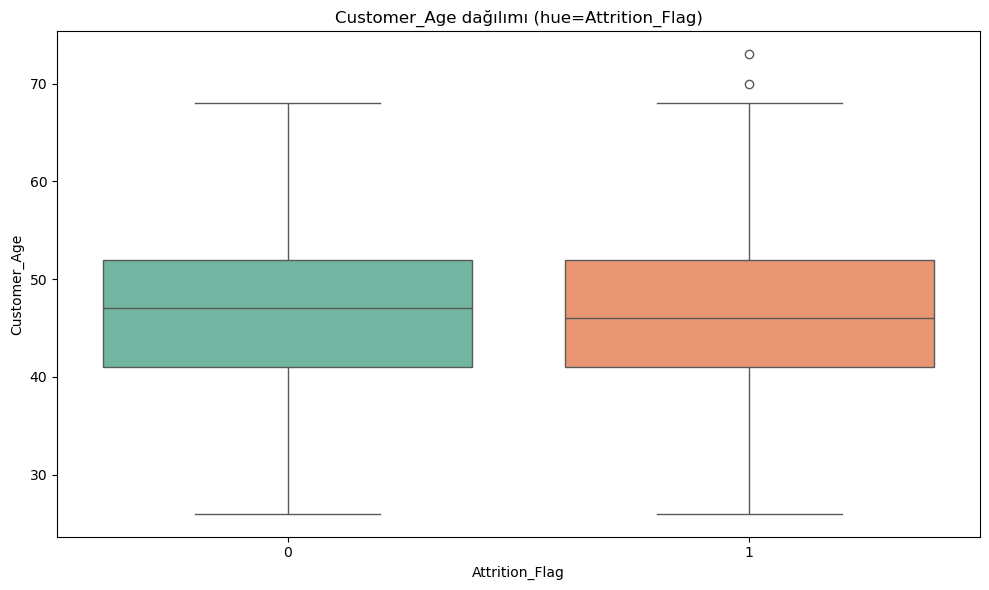

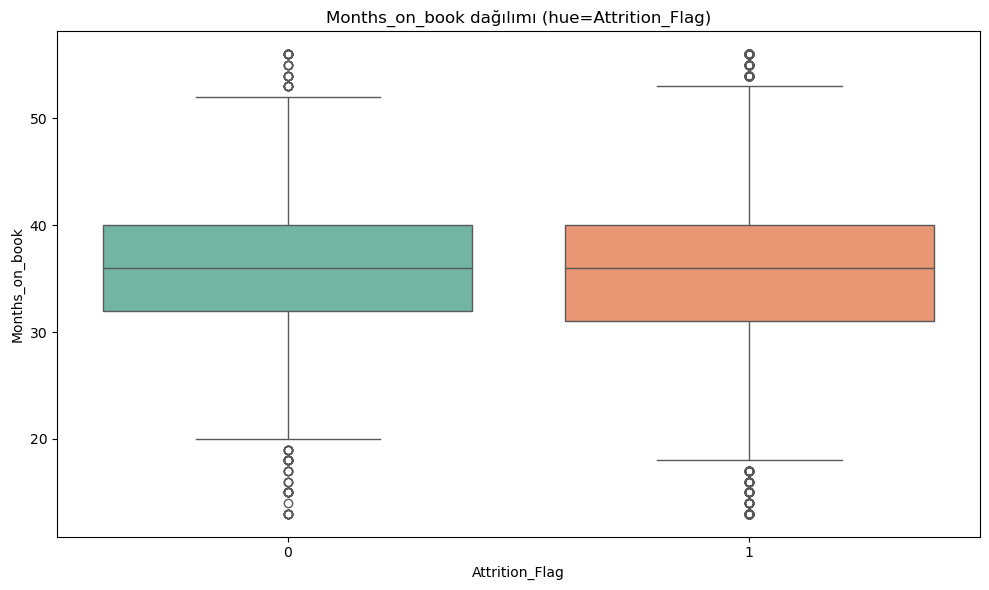

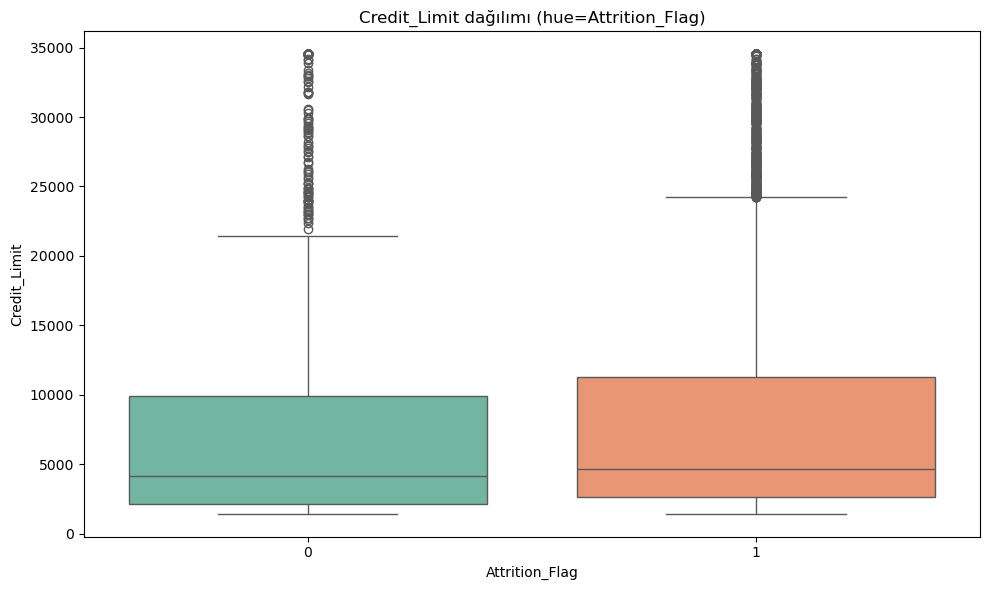

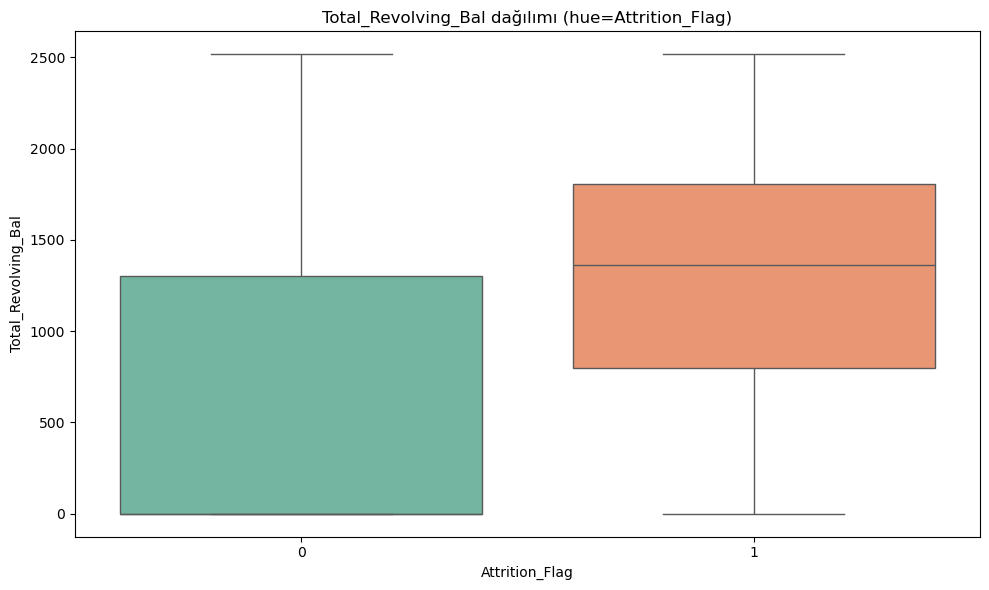

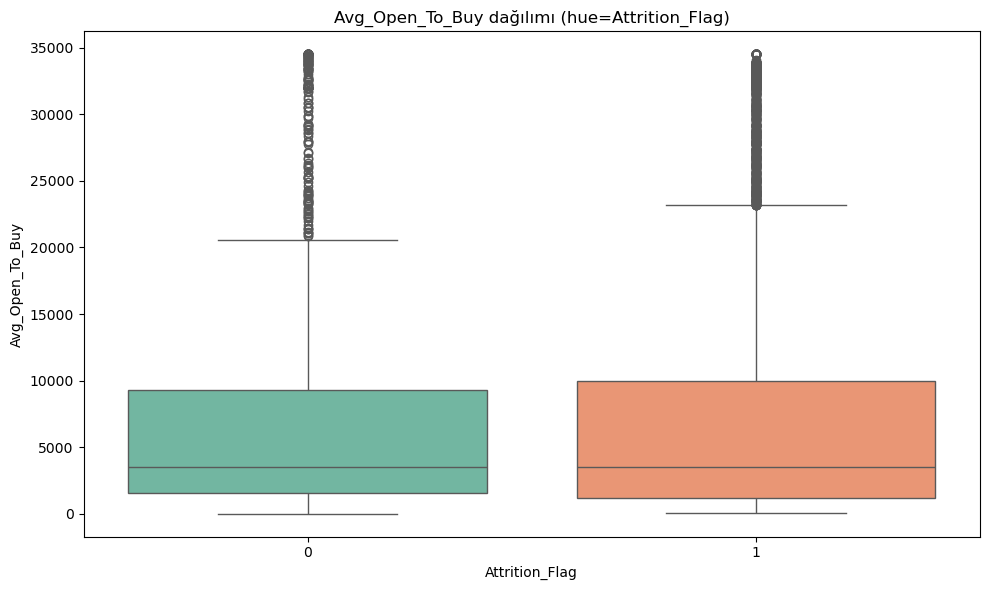

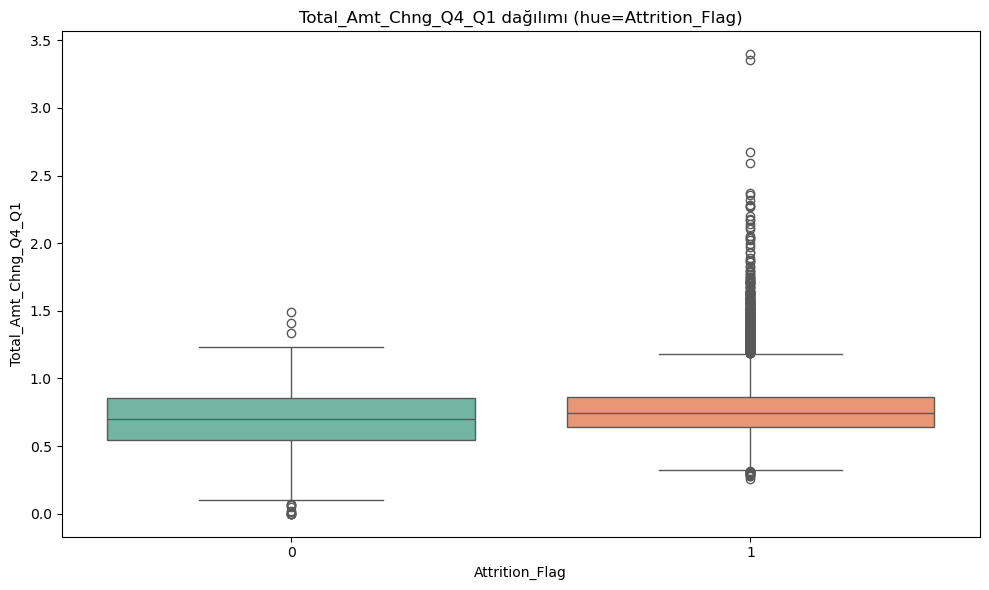

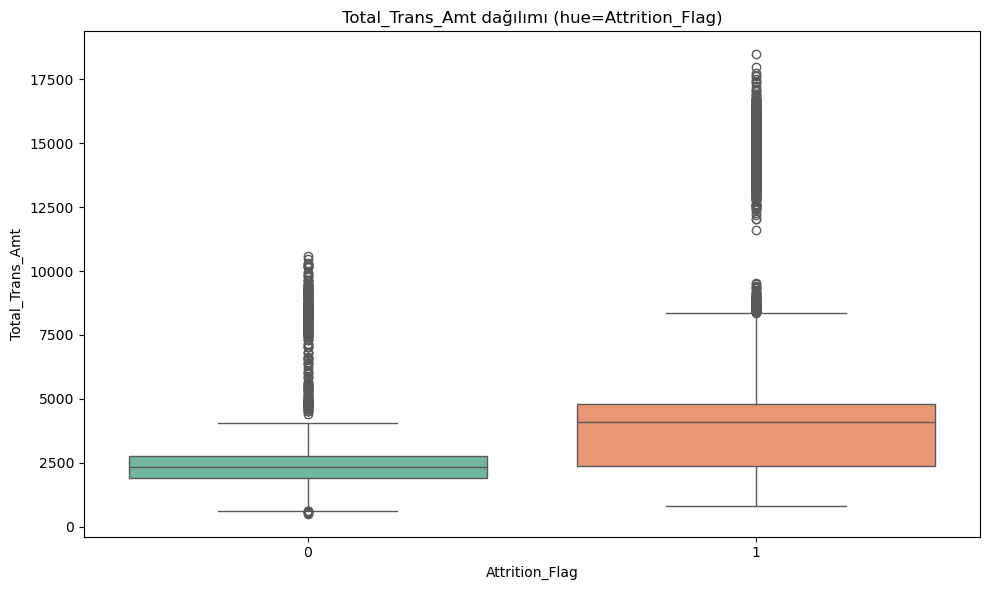

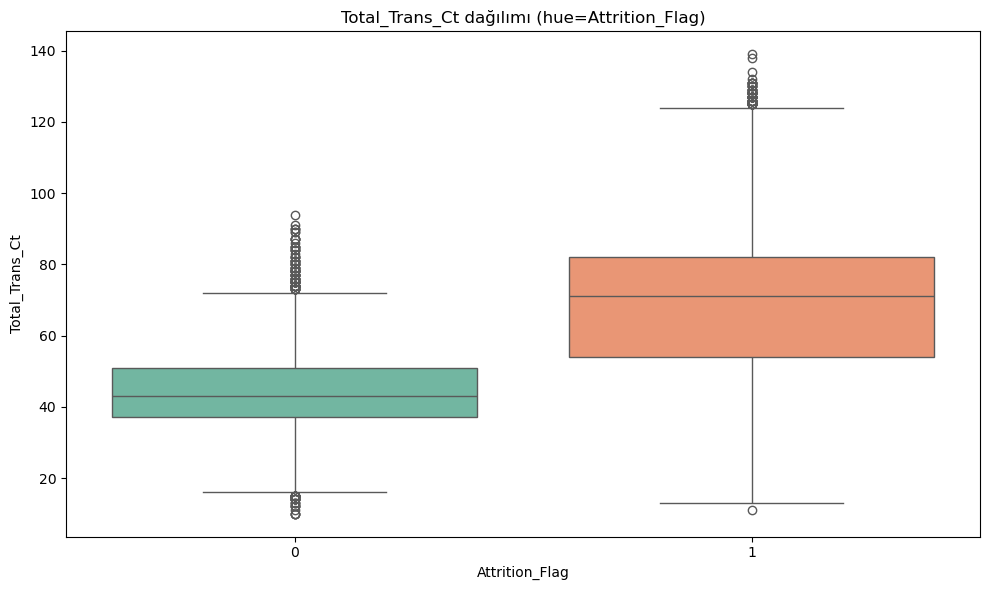

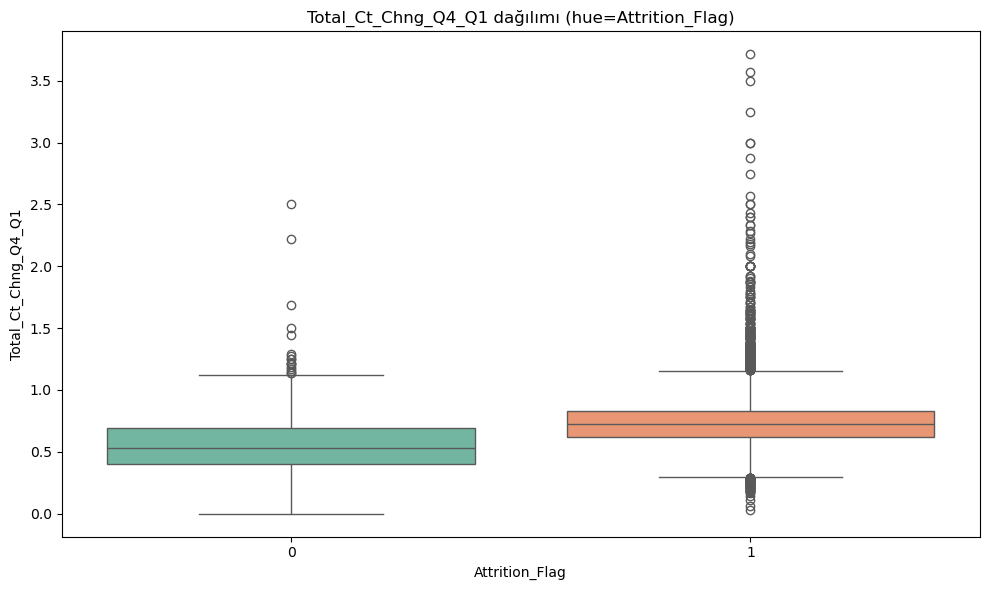

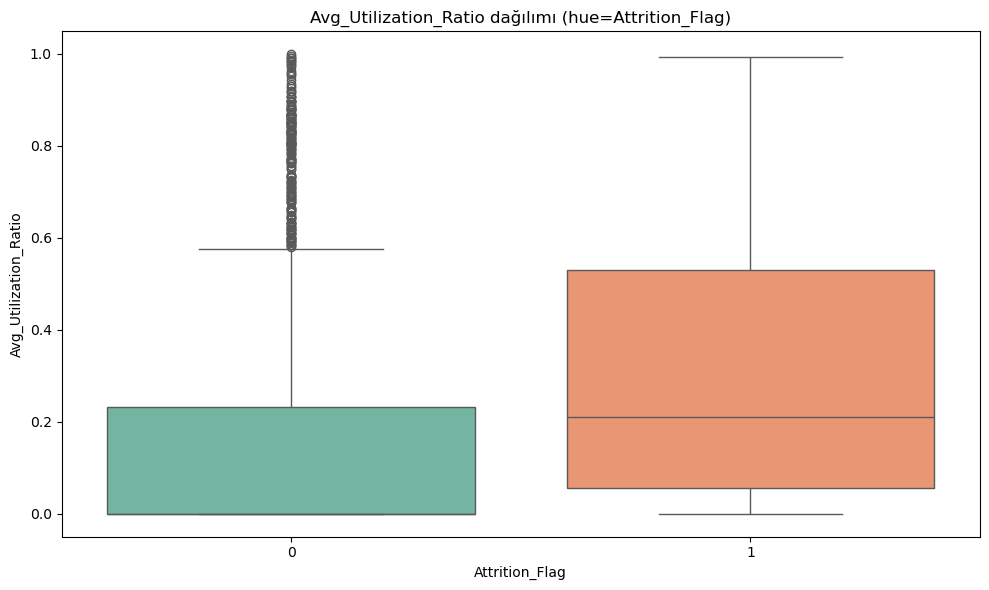

In [140]:
def plot_boxplots_vertical(df, cols, hue='Attrition_Flag', figsize=(8, 6)):
    """
    Generates vertical boxplots for each numerical feature grouped by the target variable.
    """
    for col in cols:
        fig, ax = plt.subplots(figsize=figsize)
        sns.boxplot(x=hue, y=col, data=df, ax=ax, orient='v', palette='Set2')
        ax.set_title(f"Distribution of {col} by {hue}")
        ax.set_xlabel(hue)
        ax.set_ylabel(col)
        plt.tight_layout()
        plt.show()

plot_boxplots_vertical(df, num_cols, hue='Attrition_Flag', figsize=(10, 6))

### Visual Insights from Boxplot Comparisons
* **Clear Separation in Behavioral Variables:** `Total_Trans_Ct`, `Total_Trans_Amt`, `Total_Revolving_Bal`, and `Total_Ct_Chng_Q4_Q1` show pronounced median and interquartile separation between attrited (`0`) and retained (`1`) groups.
* **Overlapping Static Distributions:** `Customer_Age`, `Months_on_book`, and `Avg_Open_To_Buy` show hampir identical median levels across both groups, confirming that dynamic usage behavior outweighs static demographic attributes.

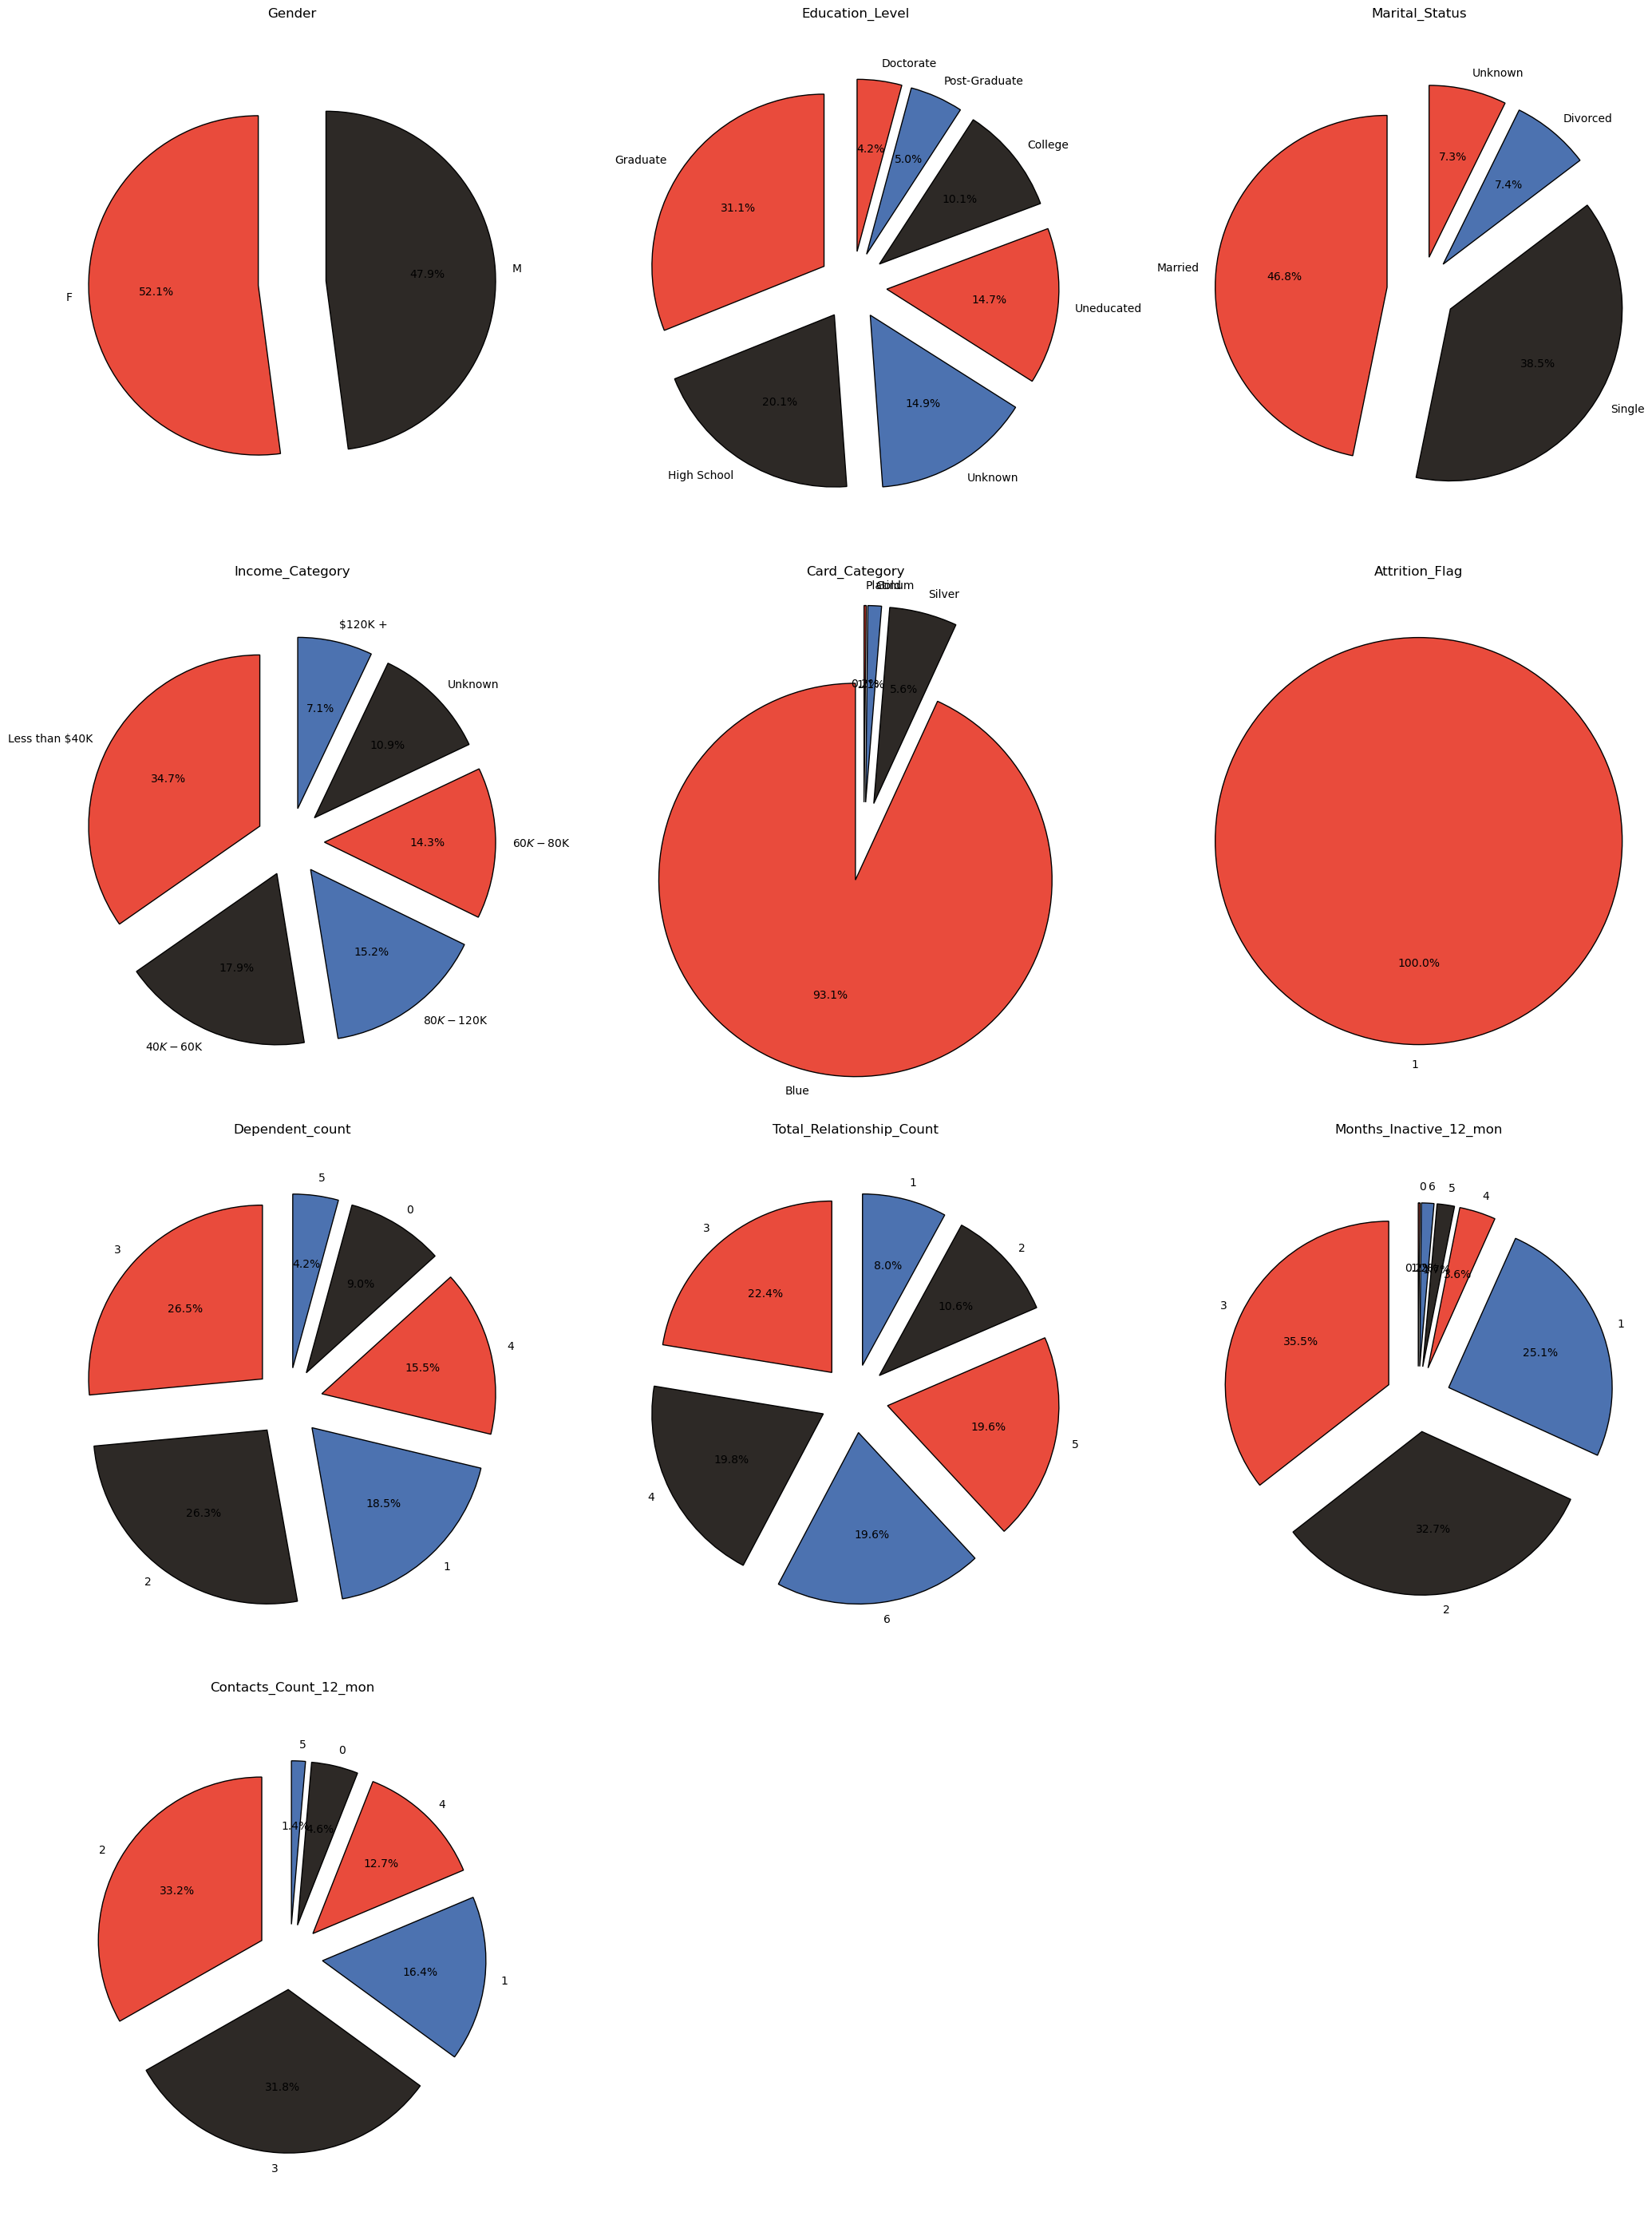

In [143]:
import matplotlib.pyplot as plt

def plot_churn_pies(
    df,
    cols,
    target='Attrition_Flag',
    target_value=1,
    ncols=3,
    figsize_per_plot=(7, 7),
    colors=None,
    explode_dist=0.2,
    wspace=0.5,
    hspace=0.5
):
    subset_df = df[df[target] == target_value]
    n = len(cols)
    nrows = (n - 1)//ncols + 1
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(figsize_per_plot[0]*ncols,
                                      figsize_per_plot[1]*nrows))
    axes = axes.flatten()
    
    for ax, col in zip(axes, cols):
        vc = subset_df[col].value_counts()
        labels = vc.index.tolist()
        sizes = vc.values
        sizes_pct = sizes / sizes.sum() * 100
        explode = [explode_dist] * len(labels)
        
        wedges, texts, autotexts = ax.pie(
            sizes_pct,
            labels=labels,
            autopct='%1.1f%%',
            startangle=90,
            explode=explode,
            colors=colors,
            wedgeprops={'edgecolor':'black','linewidth':1}
        )
        ax.set_title(col)
        ax.axis('equal')
    
    for ax in axes[n:]:
        fig.delaxes(ax)
    
    fig.subplots_adjust(wspace=wspace, hspace=hspace)
    plt.tight_layout()
    plt.show()
    
plot_churn_pies(
    df,
    cols=cat_cols,
    target='Attrition_Flag',
    target_value=1,
    ncols=3,
    colors=['#E94B3C','#2D2926','#4C72B0']
)

In [144]:
# Percentage breakdown across categorical segments for Retained Customers (Attrition_Flag == 1)
retained_df = df[df['Attrition_Flag'] == 1]

for col in cat_cols:
    pct = retained_df[col].value_counts(normalize=True) * 100
    print(f"=== {col} ===")
    print(pct.round(1).astype(str))

=== Gender ===
Gender
F    52.1
M    47.9
Name: proportion, dtype: object
=== Education_Level ===
Education_Level
Graduate         31.1
High School      20.1
Unknown          14.9
Uneducated       14.7
College          10.1
Post-Graduate     5.0
Doctorate         4.2
Name: proportion, dtype: object
=== Marital_Status ===
Marital_Status
Married     46.8
Single      38.5
Divorced     7.4
Unknown      7.3
Name: proportion, dtype: object
=== Income_Category ===
Income_Category
Less than $40K    34.7
$40K - $60K       17.9
$80K - $120K      15.2
$60K - $80K       14.3
Unknown           10.9
$120K +            7.1
Name: proportion, dtype: object
=== Card_Category ===
Card_Category
Blue        93.1
Silver       5.6
Gold         1.1
Platinum     0.2
Name: proportion, dtype: object
=== Attrition_Flag ===
Attrition_Flag
1    100.0
Name: proportion, dtype: object
=== Dependent_count ===
Dependent_count
3    26.5
2    26.3
1    18.5
4    15.5
0     9.0
5     4.2
Name: proportion, dtype: object
===

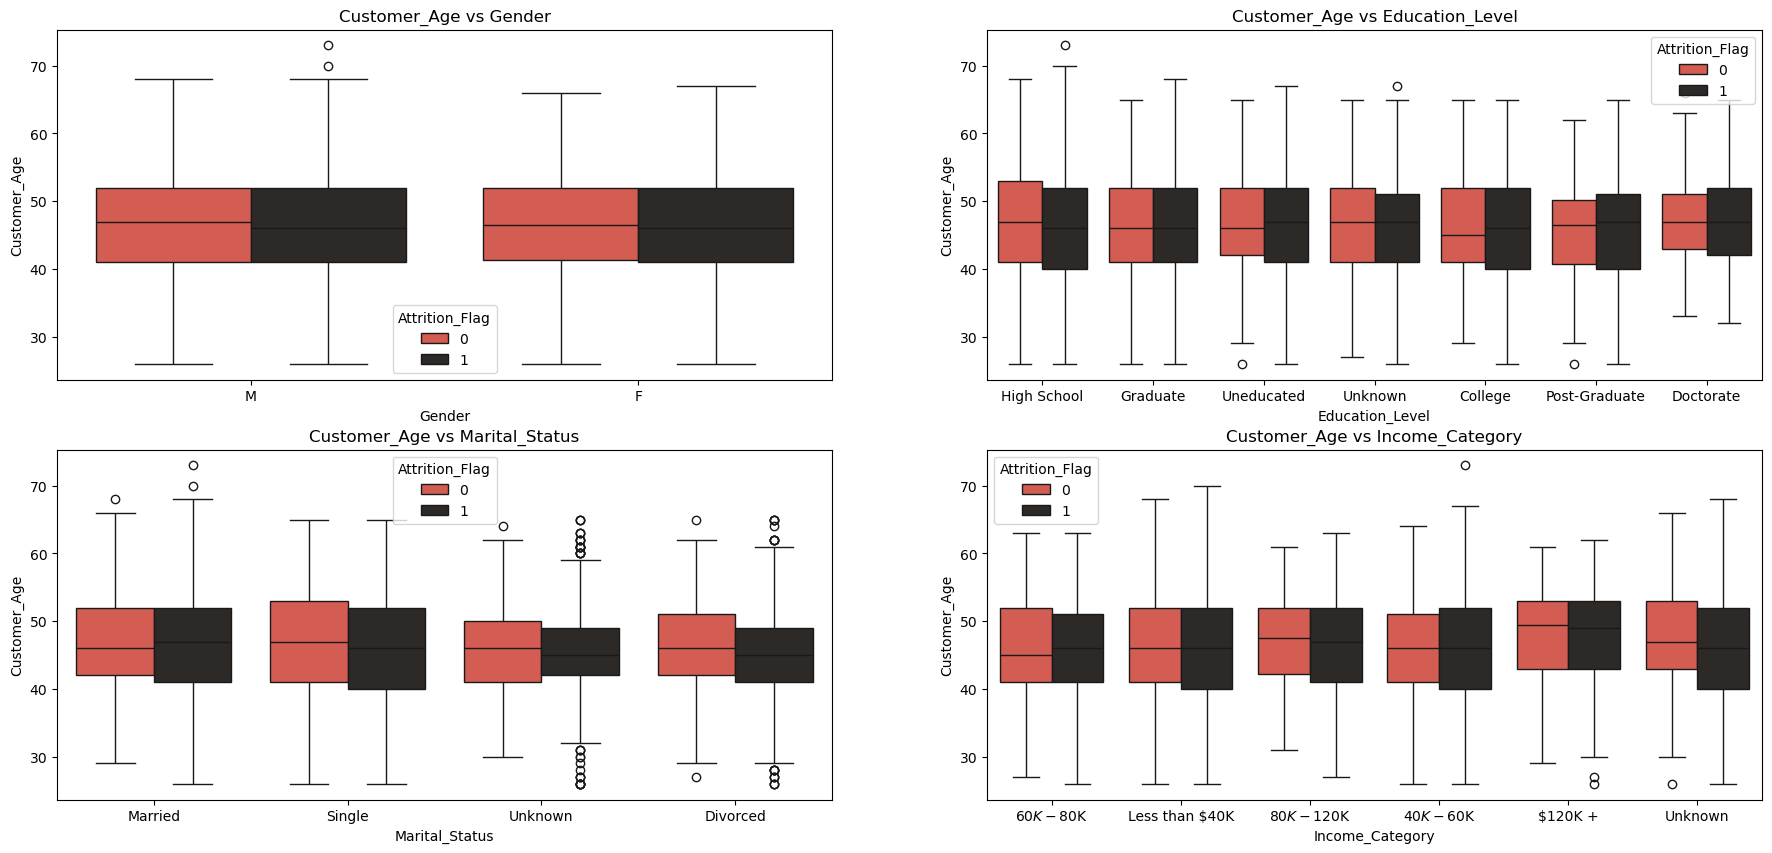

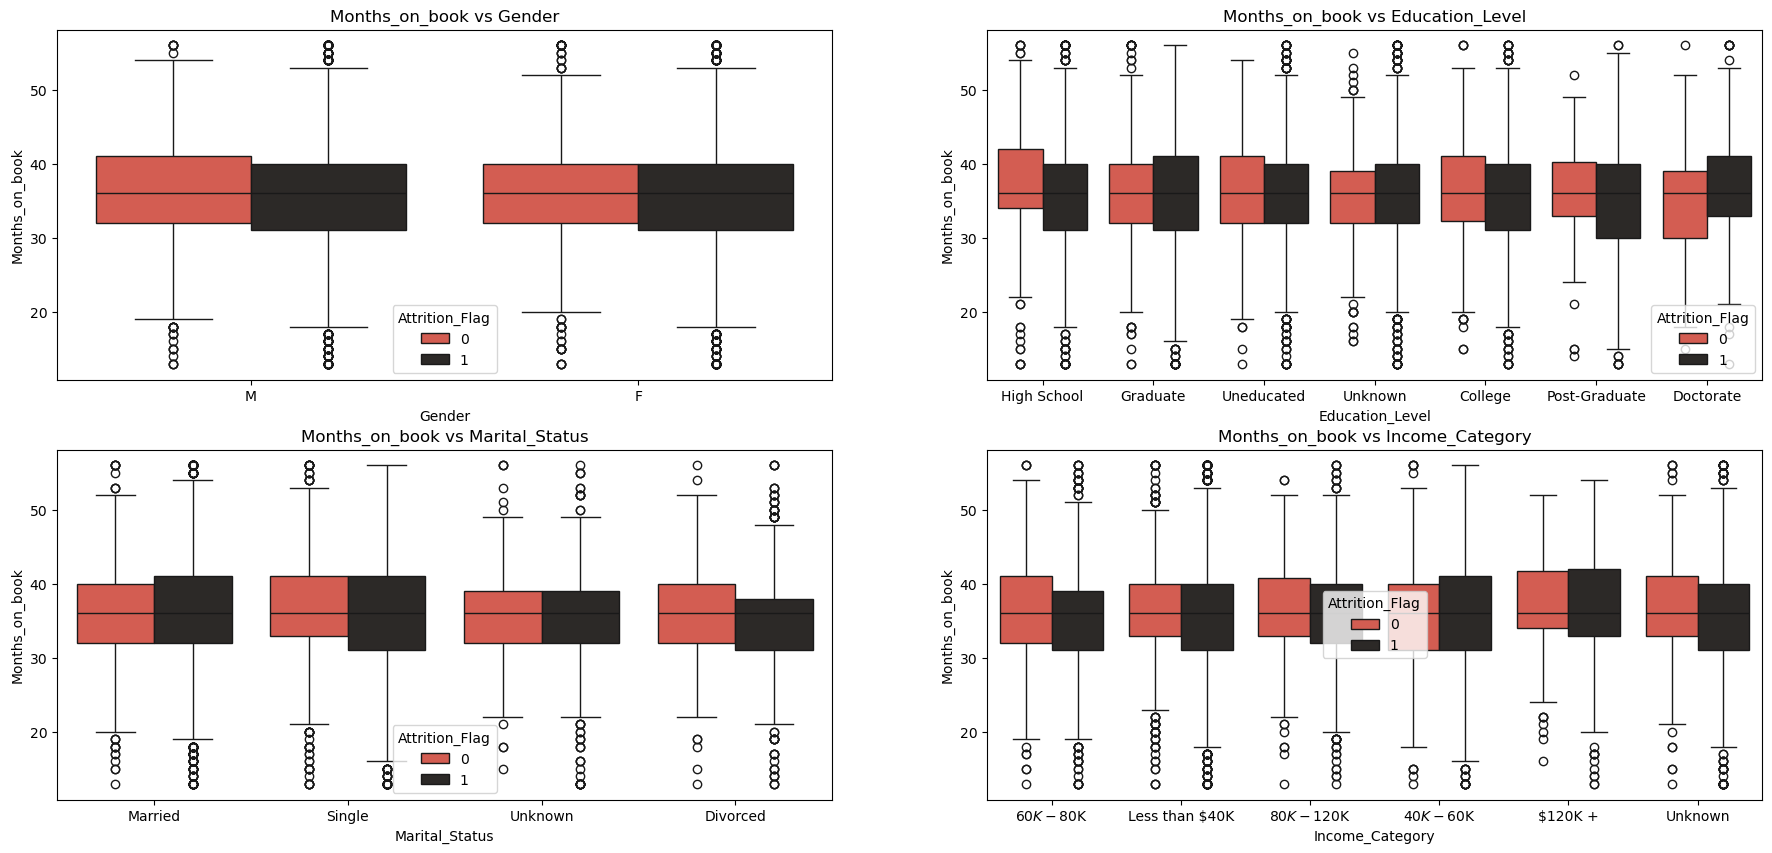

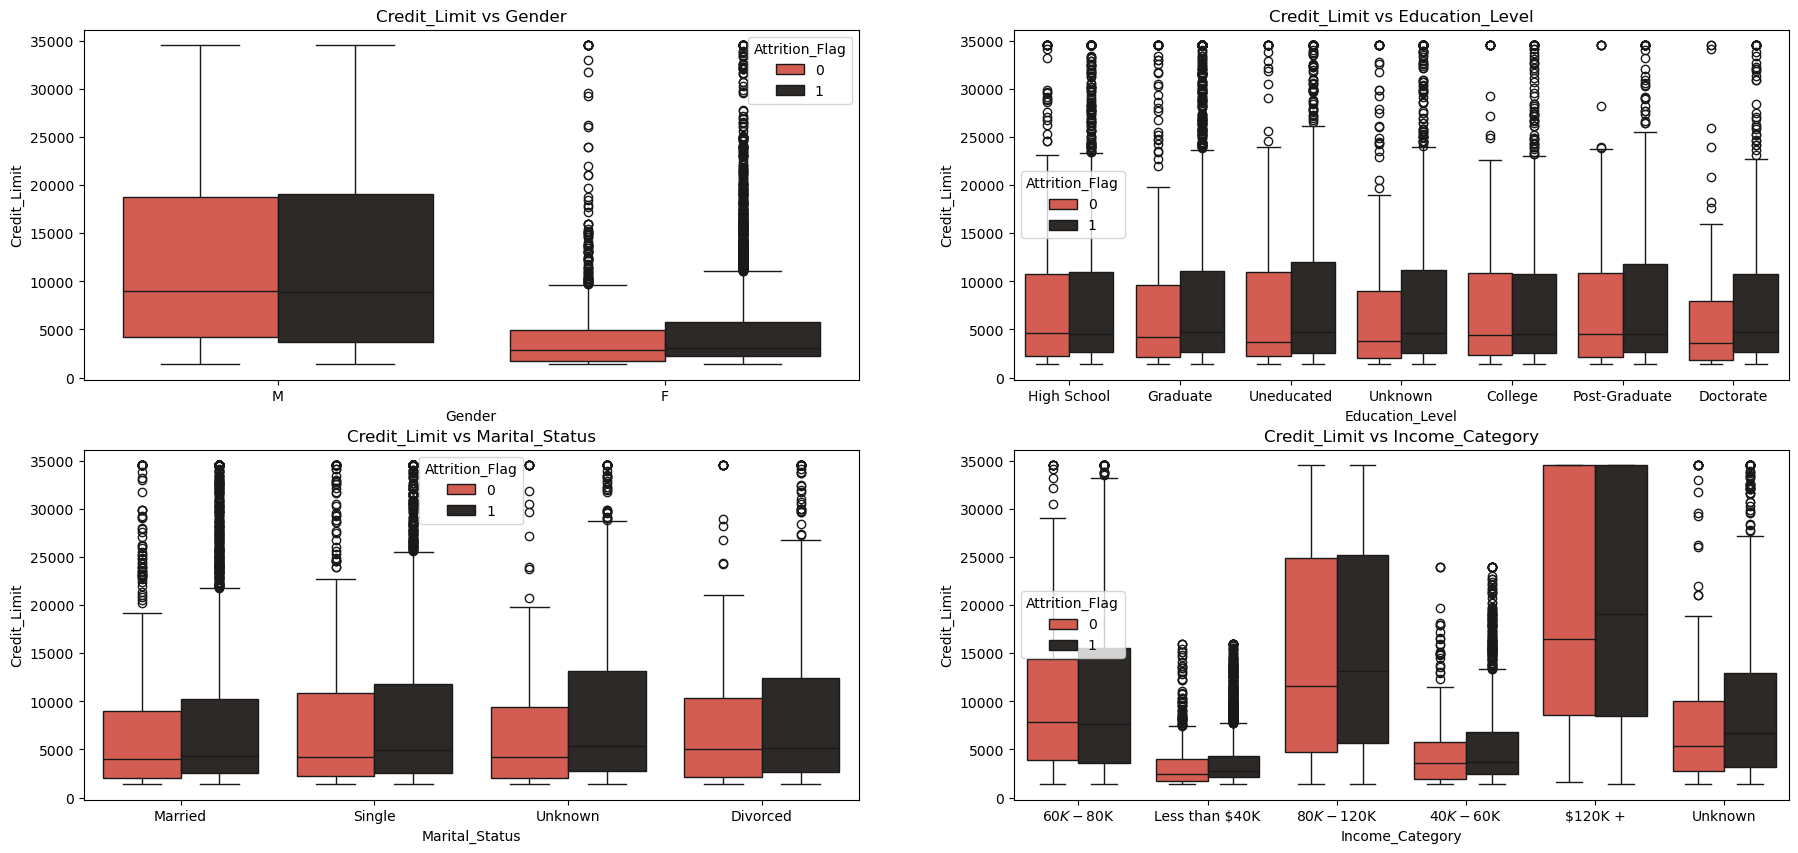

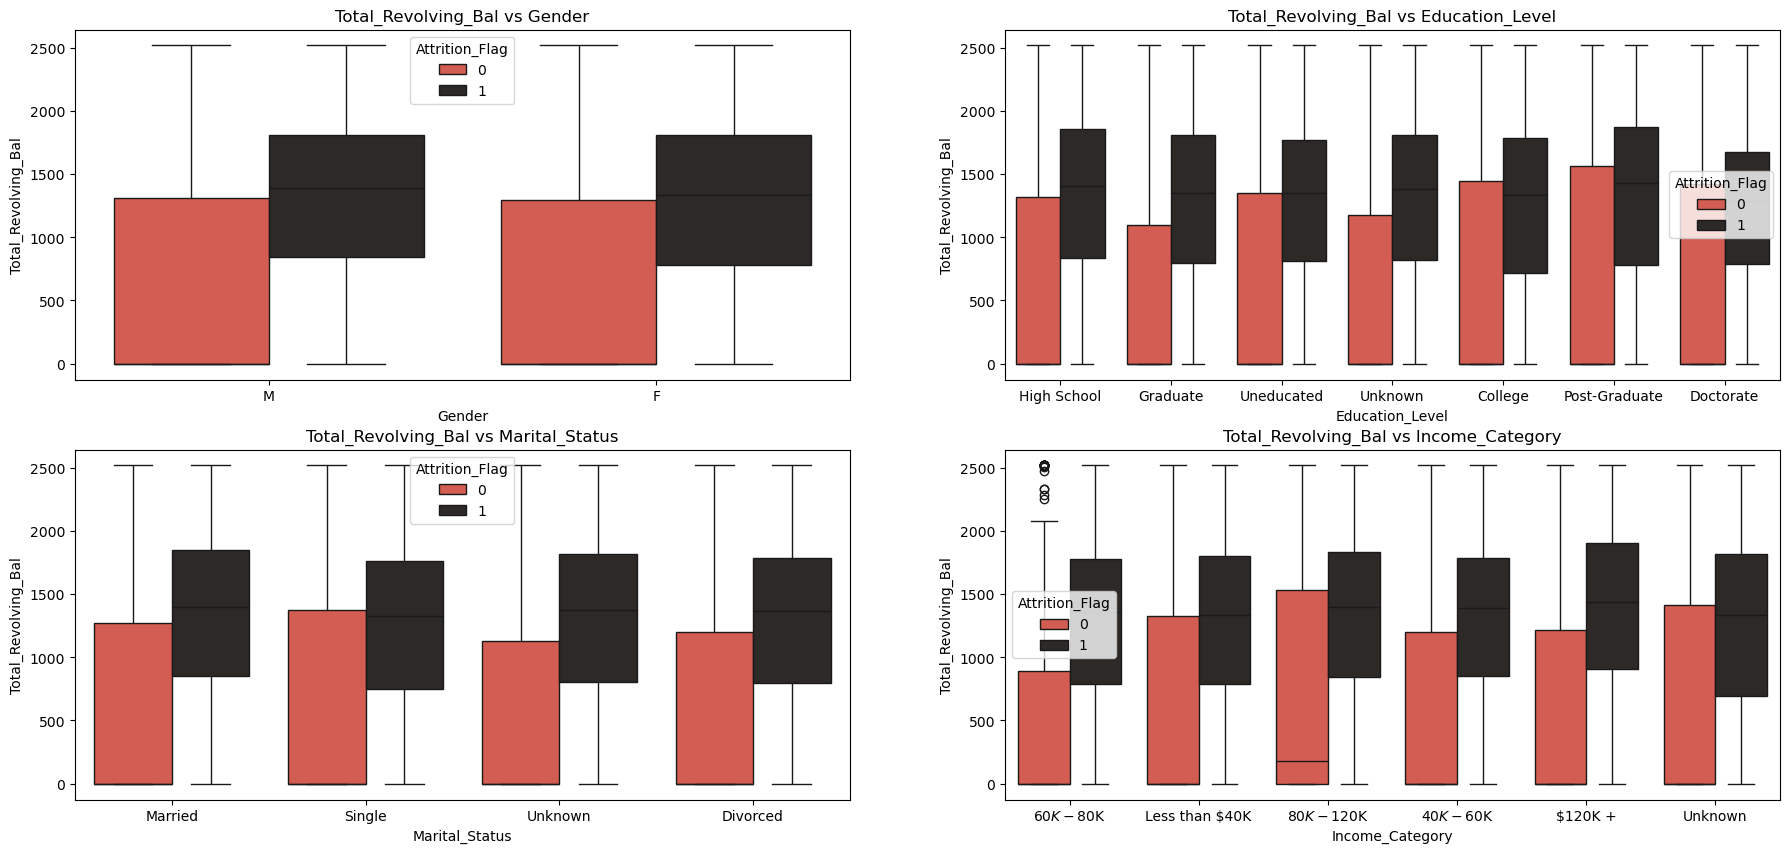

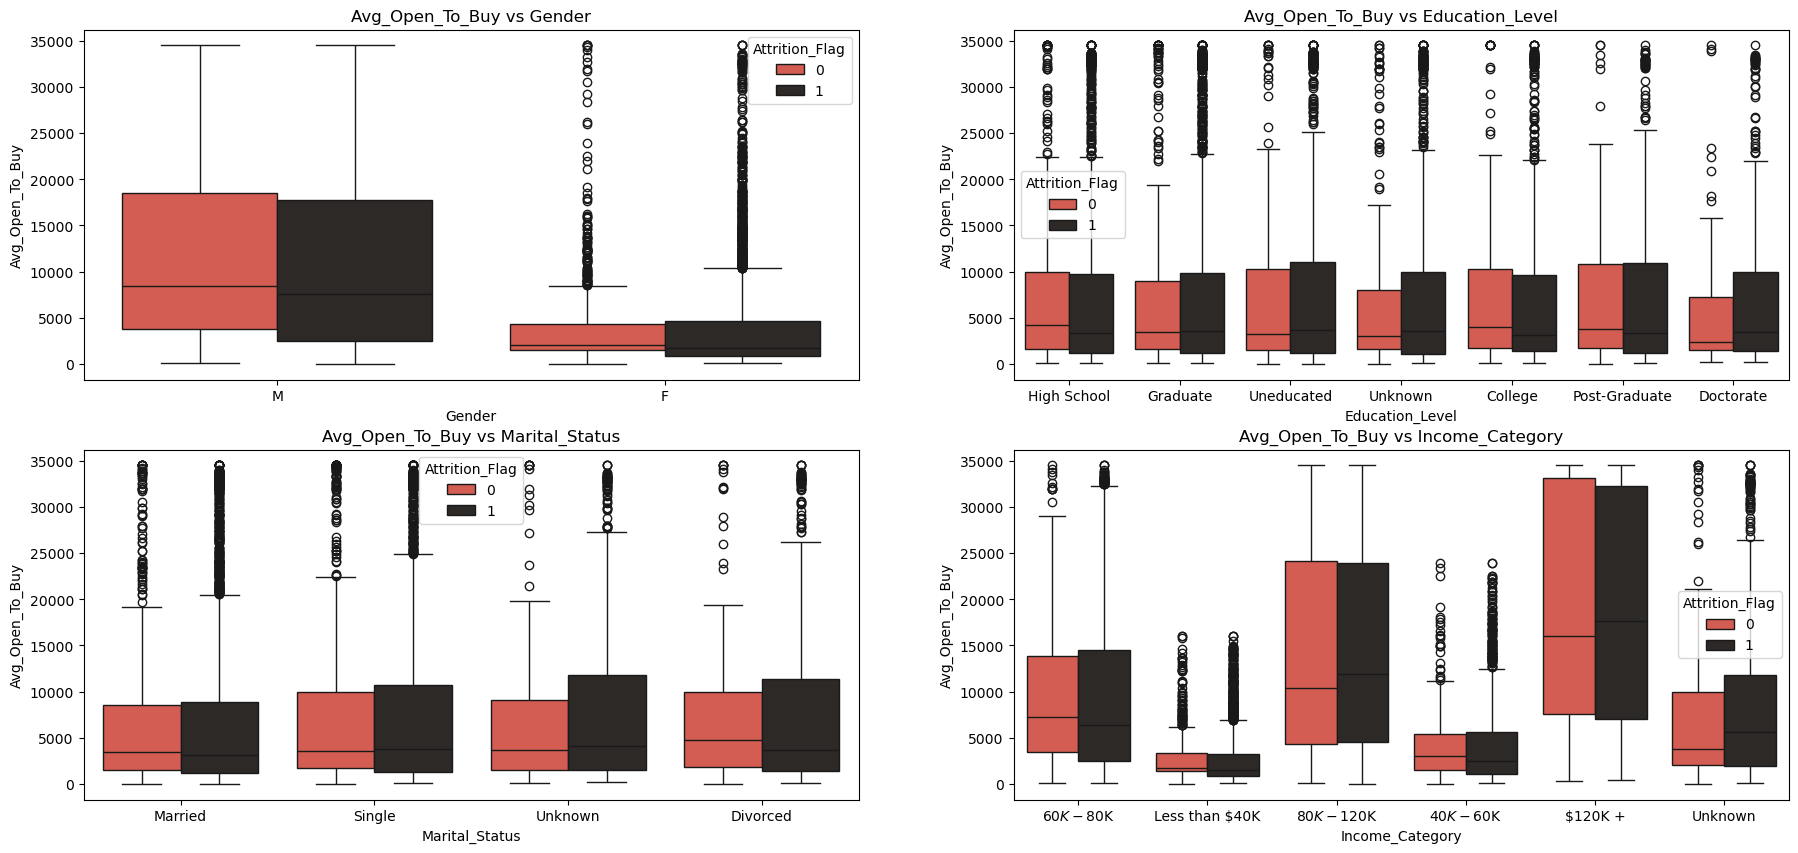

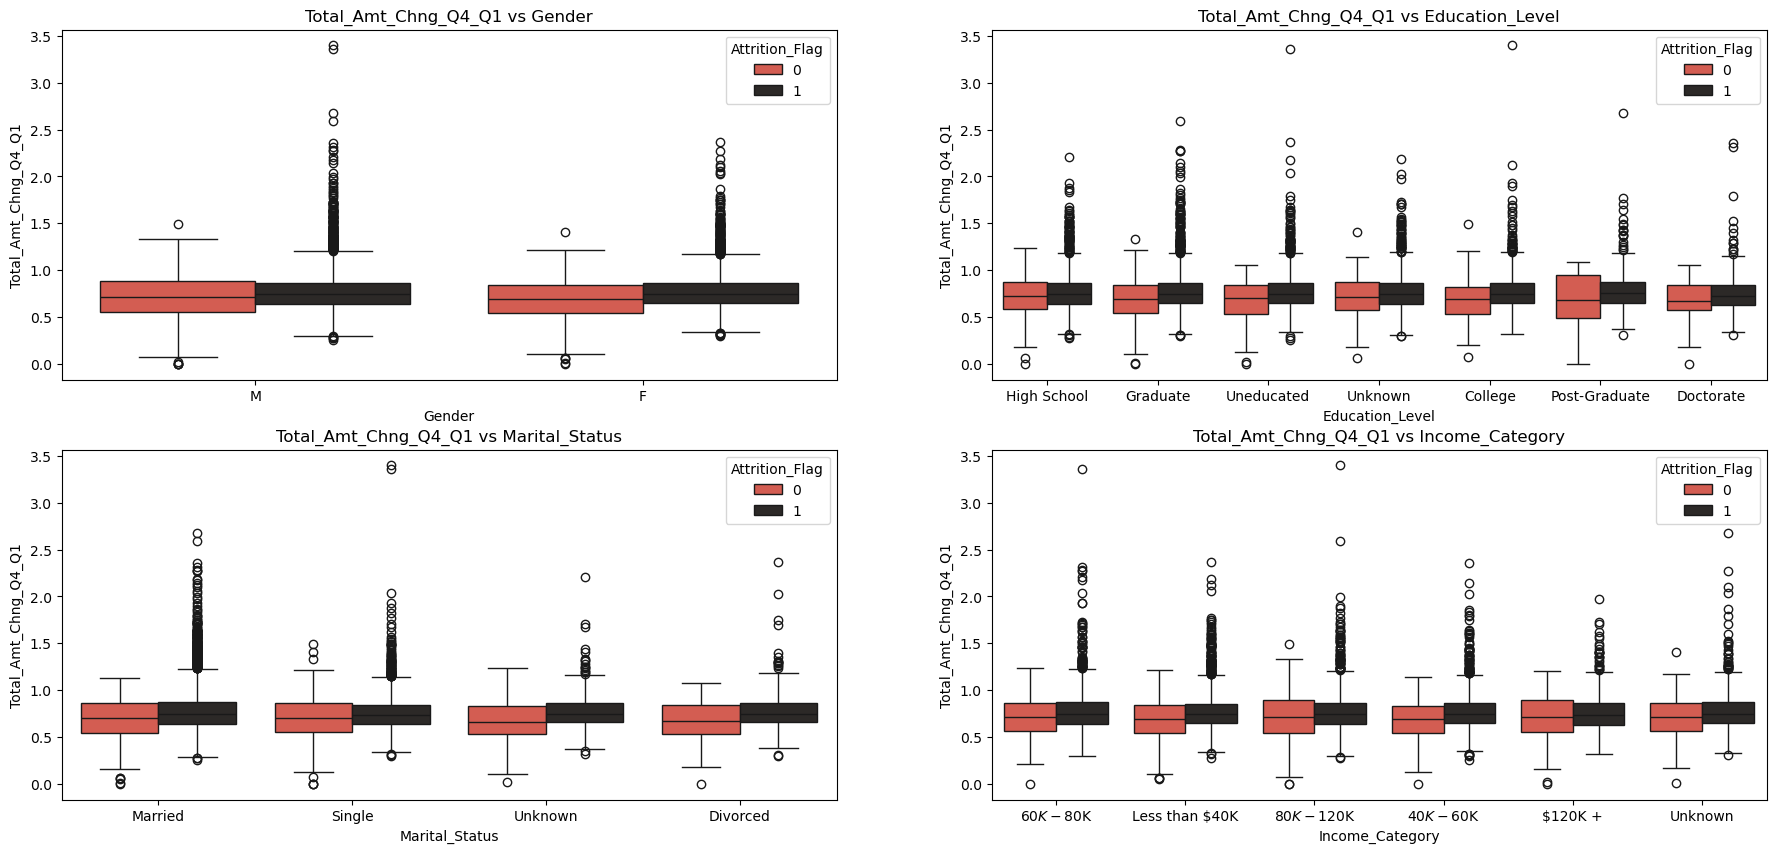

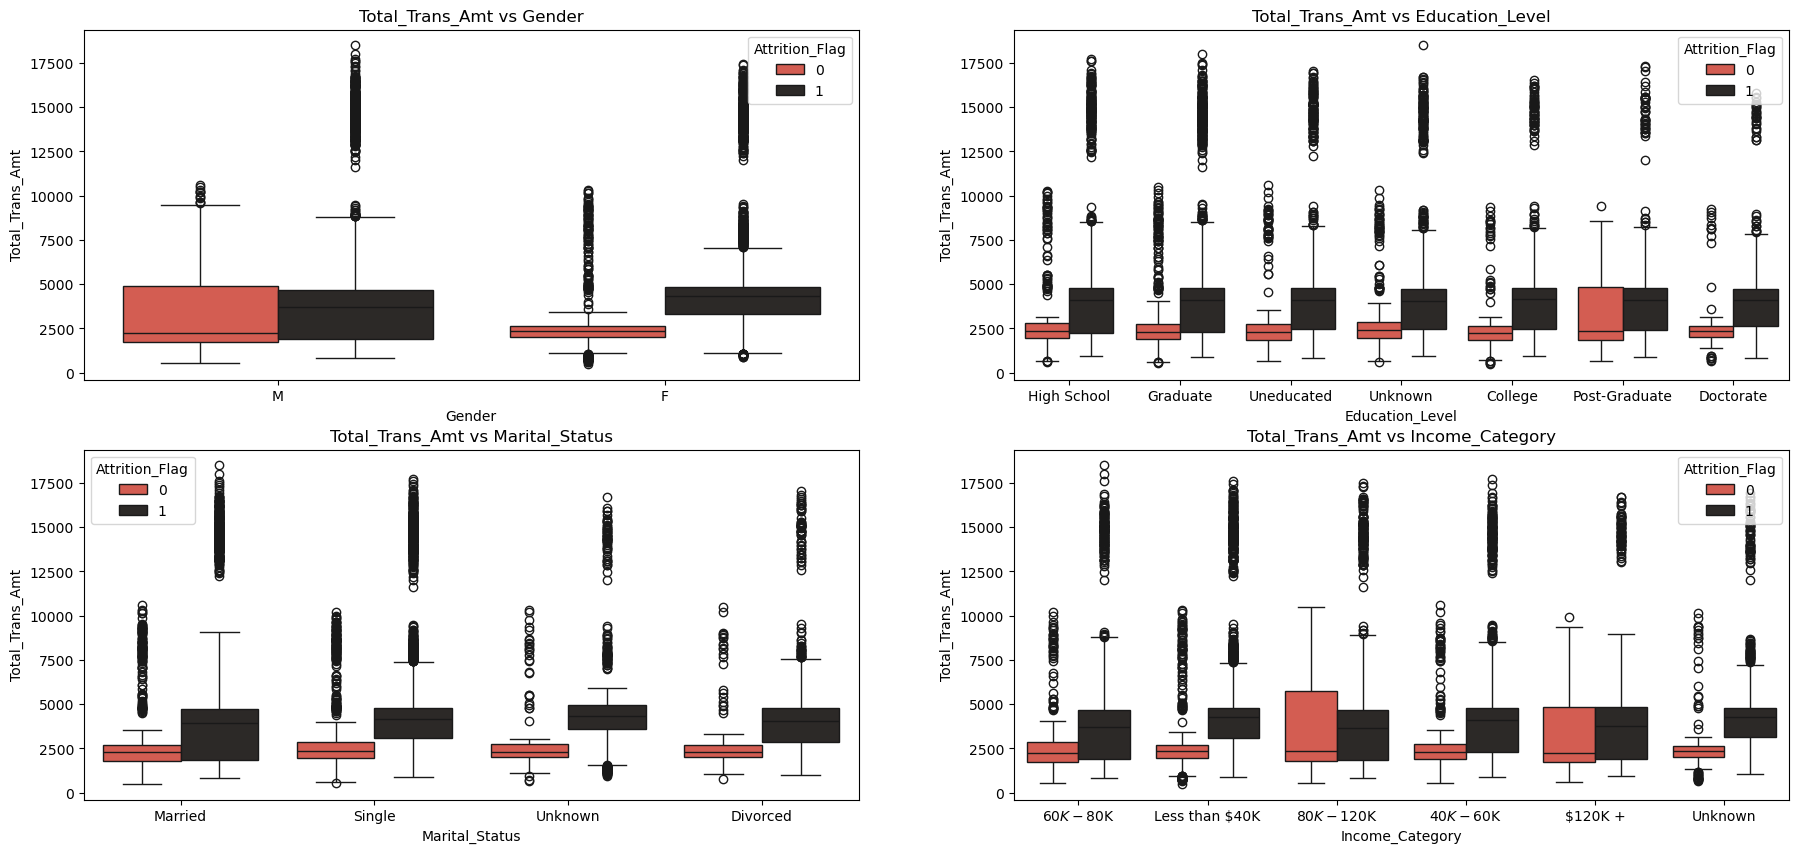

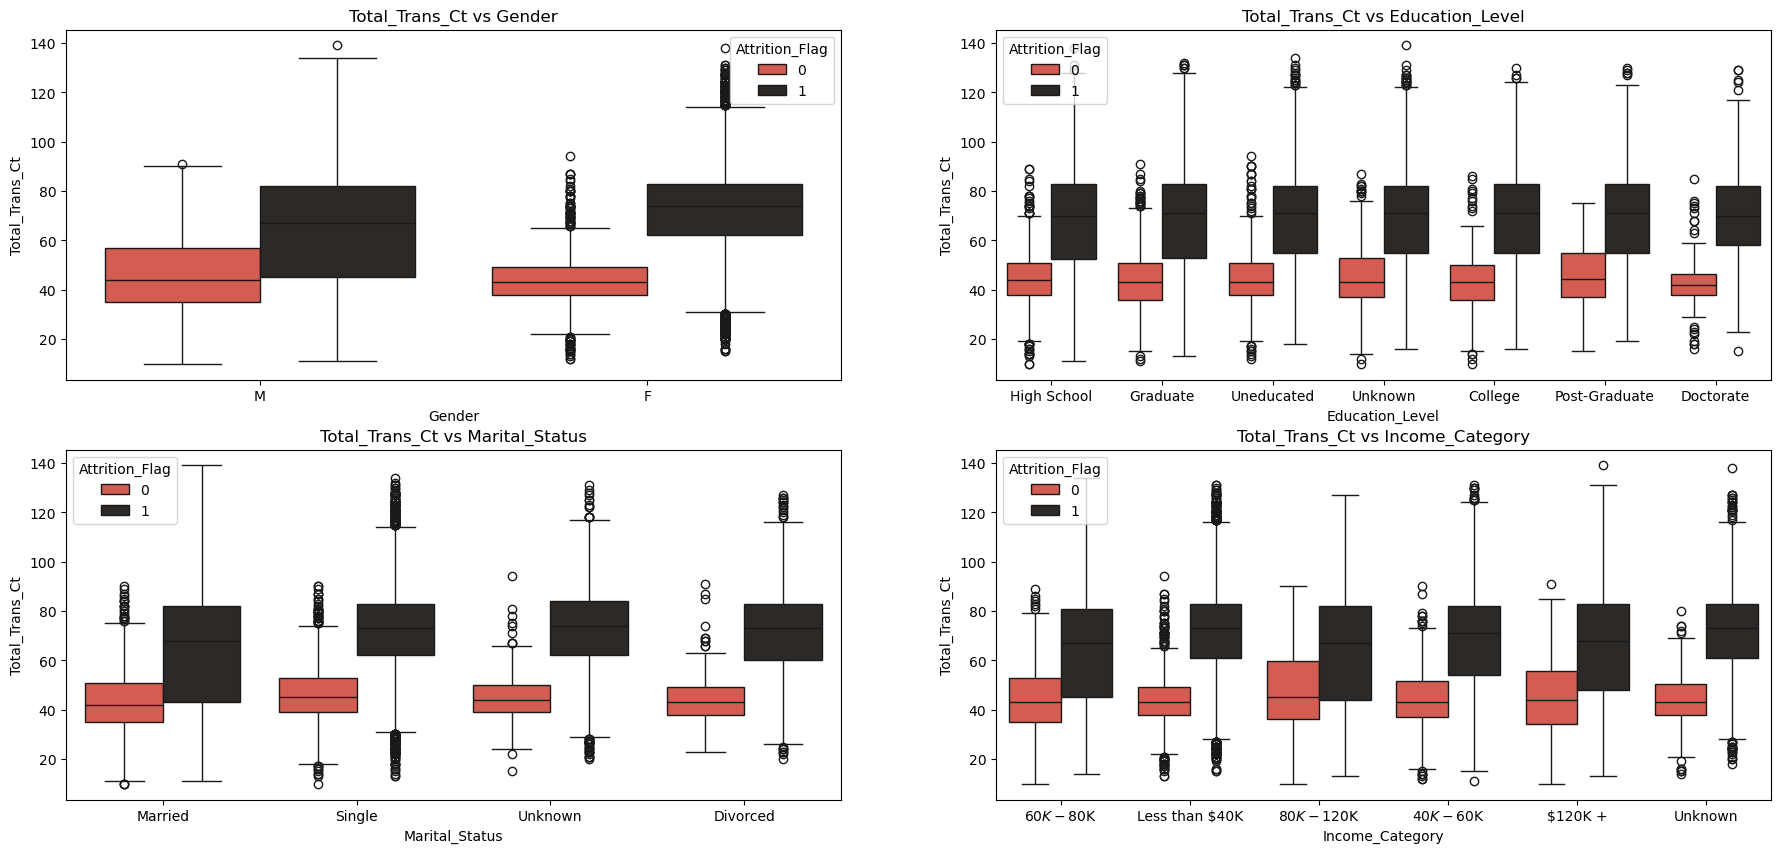

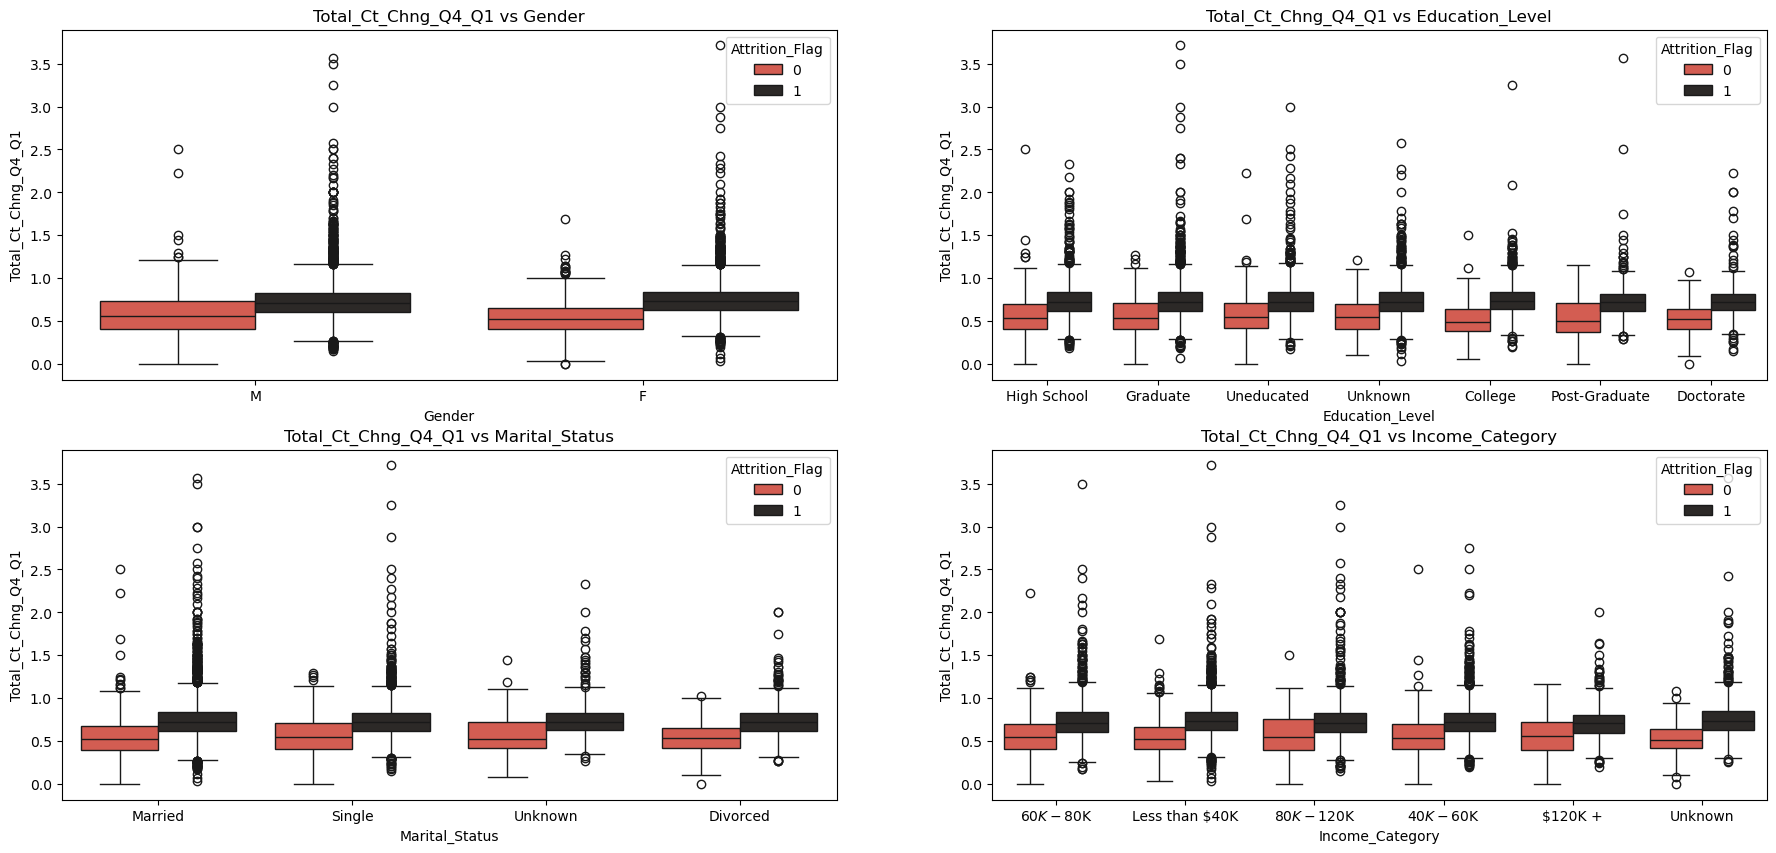

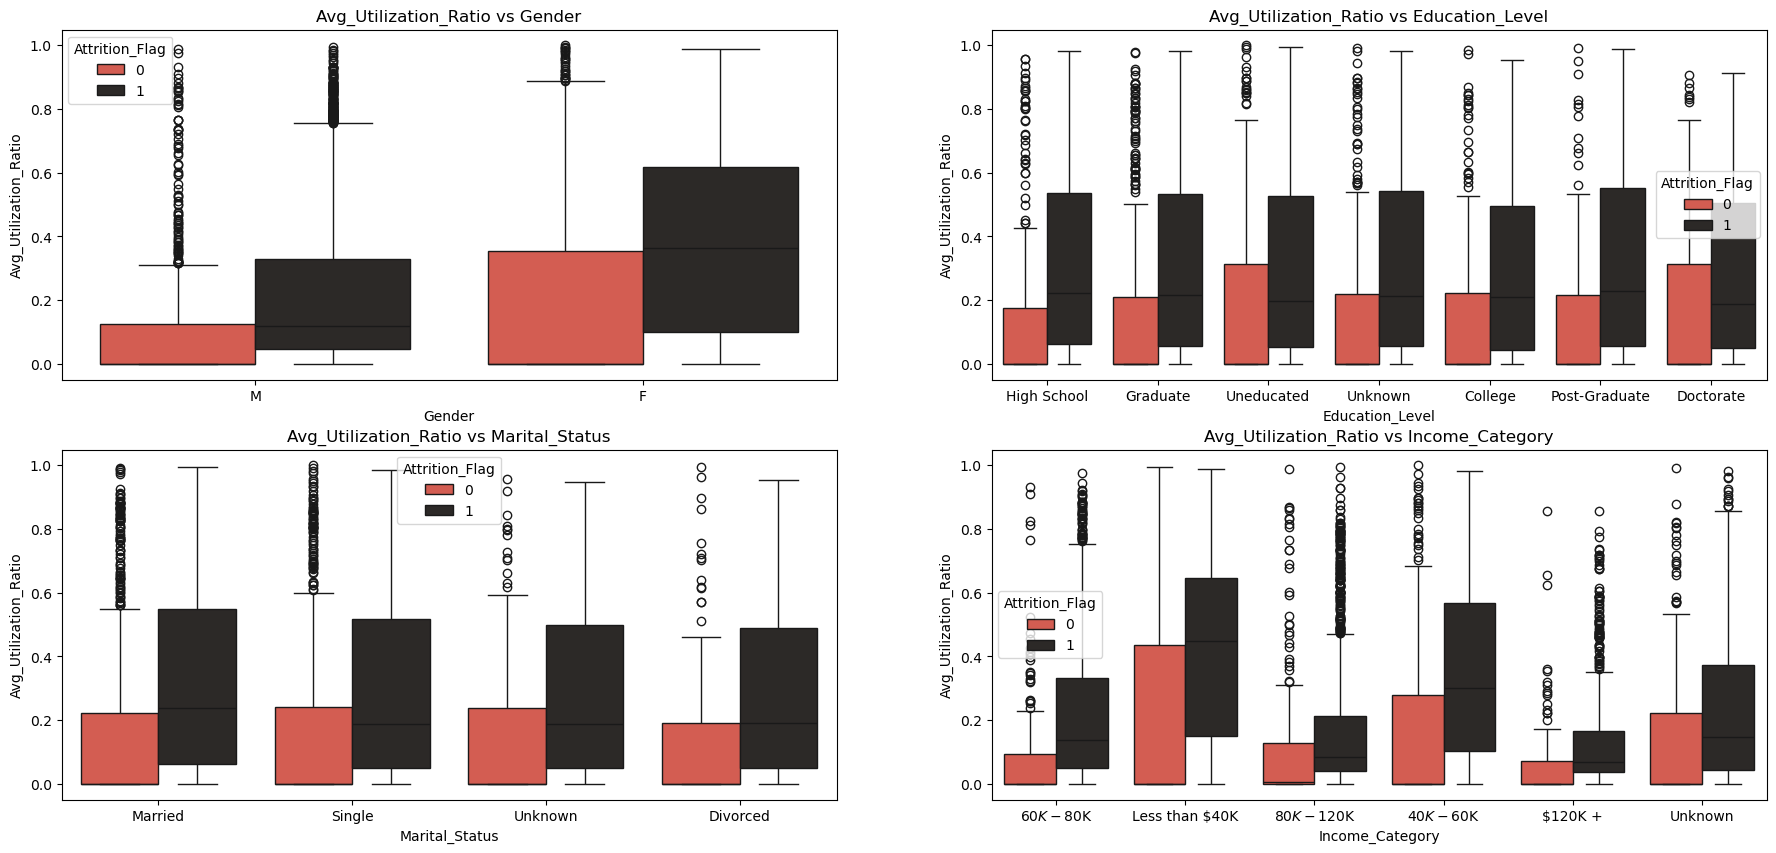

In [146]:
colors = ['#E94B3C','#2D2926']
for col in num_cols:
    fig = plt.subplots(nrows = 2,ncols = 2,figsize = (22,10))
    for i in range(4):
        plt.subplot(2,2,i+1)
        ax = sns.boxplot(x = cat_cols[i],y = col ,data = df,hue = 'Attrition_Flag',palette = colors)
        plt.title(col +' vs '+ cat_cols[i])

## 7. Correlation Structure & Multicollinearity Diagnostics

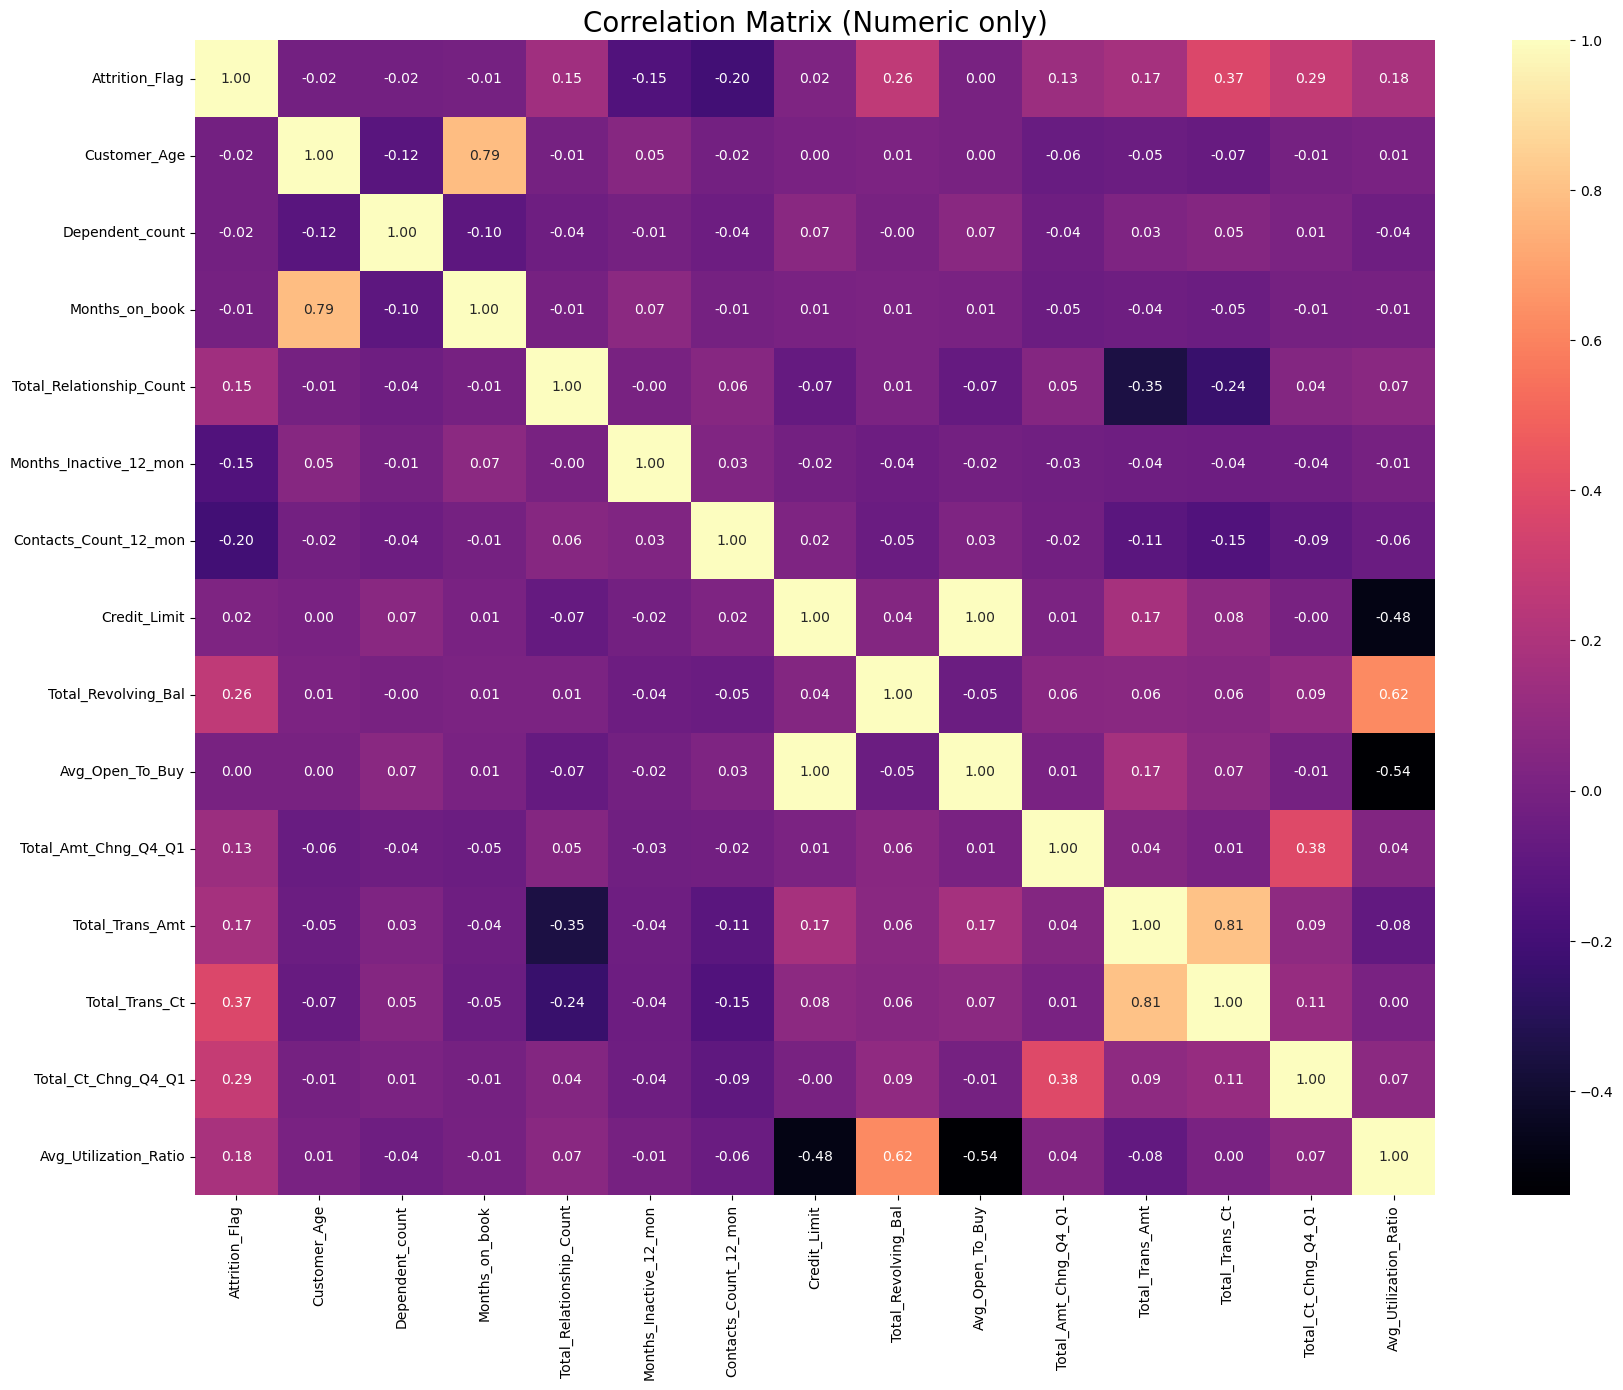

In [147]:
num_df = df.select_dtypes(include=[np.number])
corr = num_df.corr()

plt.figure(figsize=(20,15))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="magma")
plt.title("Correlation Matrix (Numeric only)", fontsize=20)
plt.show()

### Correlation Matrix Interpretation
* **Strongest Positive Correlates with Retention (`Attrition_Flag`):** `Total_Trans_Ct` ($r = 0.37$), `Total_Ct_Chng_Q4_Q1` ($r = 0.29$), `Total_Revolving_Bal` ($r = 0.26$), and `Avg_Utilization_Ratio` ($r = 0.18$) are positively associated with customer retention.
* **Negative Correlates with Retention:** `Contacts_Count_12_mon` ($r = -0.20$) and `Months_Inactive_12_mon` ($r = -0.15$) are negatively correlated with retention (i.e., higher inactivity and contact counts increase churn risk).
* **Structural Collinearity:** 
  - `Credit_Limit` and `Avg_Open_To_Buy` are almost perfectly collinear ($r = 1.00$), as open-to-buy credit is directly derived from the credit limit minus revolving balance.
  - `Total_Trans_Amt` and `Total_Trans_Ct` share a strong positive correlation ($r = 0.81$), while `Customer_Age` and `Months_on_book` are strongly correlated ($r = 0.79$).

In [148]:
corr_matrix = df[num_cols].corr()
corr_matrix

,Customer_Age,Months_on_book,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
Customer_Age,1.00,0.79,0.00,0.01,0.00,-0.06,-0.05,-0.07,-0.01,0.01
Months_on_book,0.79,1.00,0.01,0.01,0.01,-0.05,-0.04,-0.05,-0.01,-0.01
Credit_Limit,0.00,0.01,1.00,0.04,1.00,0.01,0.17,0.08,-0.00,-0.48
Total_Revolving_Bal,0.01,0.01,0.04,1.00,-0.05,0.06,0.06,0.06,0.09,0.62
Avg_Open_To_Buy,0.00,0.01,1.00,-0.05,1.00,0.01,0.17,0.07,-0.01,-0.54
Total_Amt_Chng_Q4_Q1,-0.06,-0.05,0.01,0.06,0.01,1.00,0.04,0.01,0.38,0.04
Total_Trans_Amt,-0.05,-0.04,0.17,0.06,0.17,0.04,1.00,0.81,0.09,-0.08
Total_Trans_Ct,-0.07,-0.05,0.08,0.06,0.07,0.01,0.81,1.00,0.11,0.00
Total_Ct_Chng_Q4_Q1,-0.01,-0.01,-0.00,0.09,-0.01,0.38,0.09,0.11,1.00,0.07
Avg_Utilization_Ratio,0.01,-0.01,-0.48,0.62,-0.54,0.04,-0.08,0.00,0.07,1.00


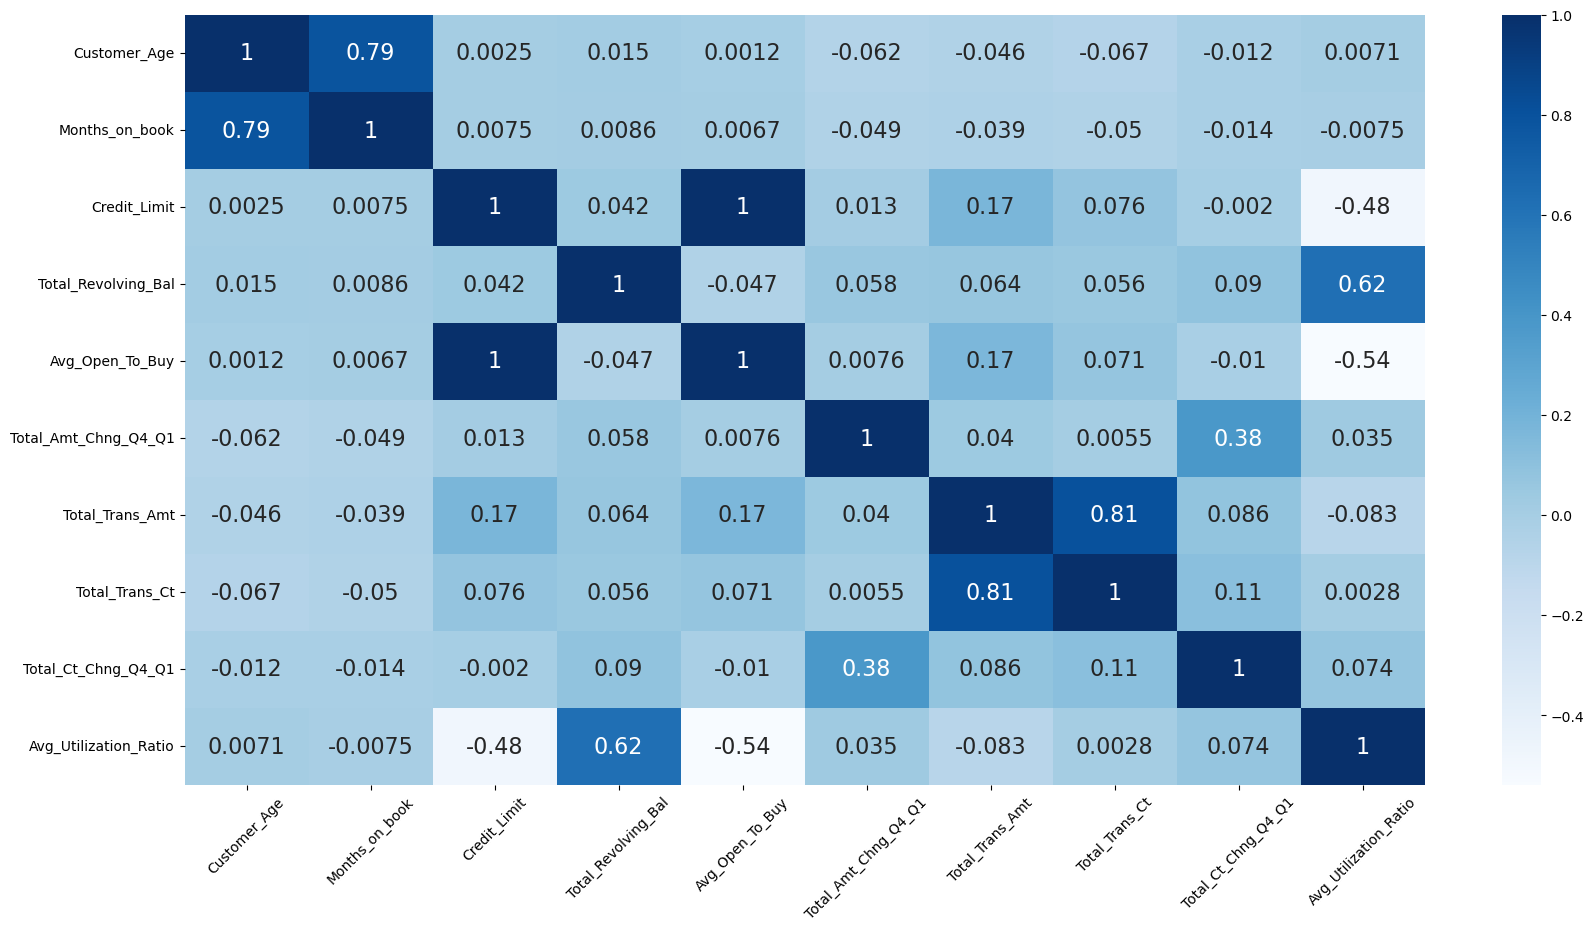

In [149]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import cm

fig, ax = plt.subplots(figsize=(20, 10))

sns.heatmap(df[num_cols].corr(),
            annot=True,
            annot_kws={'fontsize': 16},
            cmap='Blues',
            ax=ax)

ax.tick_params(axis='x', rotation=45)
ax.tick_params(axis='y', rotation=360);

# 8. Data Preparation & Robust Outlier Treatment
### 8.1 Missing Values Diagnostics

In [150]:
def missing_values_table(dataframe, na_name=False):
    na_columns = [col for col in dataframe.columns if dataframe[col].isnull().sum() > 0]
    n_miss = dataframe[na_columns].isnull().sum().sort_values(ascending=False)
    ratio = (dataframe[na_columns].isnull().sum() / dataframe.shape[0] * 100).sort_values(ascending=False)
    missing_df = pd.concat([n_miss, np.round(ratio, 2)], axis=1, keys=['n_miss', 'ratio'])
    print(missing_df, end="\n")
    if na_name:
        return na_columns

na_columns = missing_values_table(df, na_name=True)

Empty DataFrame
Columns: [n_miss, ratio]
Index: []


In [151]:
df.isnull().sum()

Attrition_Flag              0
Customer_Age                0
Gender                      0
Dependent_count             0
Education_Level             0
Marital_Status              0
Income_Category             0
Card_Category               0
Months_on_book              0
Total_Relationship_Count    0
Months_Inactive_12_mon      0
Contacts_Count_12_mon       0
Credit_Limit                0
Total_Revolving_Bal         0
Avg_Open_To_Buy             0
Total_Amt_Chng_Q4_Q1        0
Total_Trans_Amt             0
Total_Trans_Ct              0
Total_Ct_Chng_Q4_Q1         0
Avg_Utilization_Ratio       0
dtype: int64

### 8.2 Non-Parametric Outlier Detection & Winsorization ($Q_{0.05} - Q_{0.95}$ IQR Fencing)

In [153]:
df[num_cols].describe([0.25,0.5,0.75,0.9,0.95,0.99]).T

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
Customer_Age,10127.00,46.33,8.02,26.00,41.00,46.00,52.00,57.00,60.00,65.00,73.00
Months_on_book,10127.00,35.93,7.99,13.00,31.00,36.00,40.00,46.00,50.00,56.00,56.00
Credit_Limit,10127.00,8631.95,9088.78,1438.30,2555.00,4549.00,11067.50,23400.20,34516.00,34516.00,34516.00
Total_Revolving_Bal,10127.00,1162.81,814.99,0.00,359.00,1276.00,1784.00,2228.40,2517.00,2517.00,2517.00
Avg_Open_To_Buy,10127.00,7469.14,9090.69,3.00,1324.50,3474.00,9859.00,21964.60,32183.40,34294.14,34516.00
Total_Amt_Chng_Q4_Q1,10127.00,0.76,0.22,0.00,0.63,0.74,0.86,1.00,1.10,1.51,3.40
Total_Trans_Amt,10127.00,4404.09,3397.13,510.00,2155.50,3899.00,4741.00,8212.40,14212.00,15882.36,18484.00
Total_Trans_Ct,10127.00,64.86,23.47,10.00,45.00,67.00,81.00,92.00,105.00,123.00,139.00
Total_Ct_Chng_Q4_Q1,10127.00,0.71,0.24,0.00,0.58,0.70,0.82,0.95,1.07,1.46,3.71
Avg_Utilization_Ratio,10127.00,0.27,0.28,0.00,0.02,0.18,0.50,0.71,0.79,0.91,1.00


In [154]:
def outlier_thresholds(dataframe, col_name, q1=0.05, q3=0.95):
    quartile1 = dataframe[col_name].quantile(q1)
    quartile3 = dataframe[col_name].quantile(q3)
    interquantile_range = quartile3 - quartile1
    up_limit = quartile3 + 1.5 * interquantile_range
    low_limit = quartile1 - 1.5 * interquantile_range
    return low_limit, up_limit

In [155]:
for col in num_cols:
    if col != "Attrition_Flag":
        print(f"{col} outlier thresholds: {outlier_thresholds(df, col)}")

Customer_Age outlier thresholds: (-7.5, 100.5)
Months_on_book outlier thresholds: (-20.0, 92.0)
Credit_Limit outlier thresholds: (-48177.725, 84132.235)
Total_Revolving_Bal outlier thresholds: (-3775.5, 6292.5)
Avg_Open_To_Buy outlier thresholds: (-47074.34999999999, 79738.04999999999)
Total_Amt_Chng_Q4_Q1 outlier thresholds: (-0.49699999999999983, 2.0629999999999997)
Total_Trans_Amt outlier thresholds: (-18109.750000000004, 33605.05)
Total_Trans_Ct outlier thresholds: (-87.5, 220.5)
Total_Ct_Chng_Q4_Q1 outlier thresholds: (-0.6834999999999999, 2.1205)
Avg_Utilization_Ratio outlier thresholds: (-1.1895, 1.9825)


In [158]:
def outlier_th(dataframe, col_name, q1=0.05, q3=0.95):
    quartile1 = dataframe[col_name].quantile(q1)
    quartile3 = dataframe[col_name].quantile(q3)
    interquantile_range = quartile3 - quartile1
    up_limit = quartile3 + 1.5 * interquantile_range
    low_limit = quartile1 - 1.5 * interquantile_range
    return low_limit, up_limit

def check_outlier(dataframe, col_name):
    low_limit, up_limit = outlier_th(dataframe, col_name)
    if dataframe[(dataframe[col_name] > up_limit) | (dataframe[col_name] < low_limit)].any(axis=None):
        return True
    else:
        return False

def replace_with_thresholds(dataframe, variable):
    low_limit, up_limit = outlier_th(dataframe, variable)
    dataframe.loc[(dataframe[variable] < low_limit), variable] = low_limit
    dataframe.loc[(dataframe[variable] > up_limit), variable] = up_limit

In [159]:
for col in num_cols:
    print(col, check_outlier(df, col))

Customer_Age False
Months_on_book False
Credit_Limit False
Total_Revolving_Bal False
Avg_Open_To_Buy False
Total_Amt_Chng_Q4_Q1 True
Total_Trans_Amt False
Total_Trans_Ct False
Total_Ct_Chng_Q4_Q1 True
Avg_Utilization_Ratio False


In [160]:
for col in num_cols:
    replace_with_thresholds(df, col)

for col in num_cols:
    print(col, check_outlier(df, col))

Customer_Age False
Months_on_book False
Credit_Limit False
Total_Revolving_Bal False
Avg_Open_To_Buy False
Total_Amt_Chng_Q4_Q1 False
Total_Trans_Amt False
Total_Trans_Ct False
Total_Ct_Chng_Q4_Q1 False
Avg_Utilization_Ratio False


# 9. Domain-Specific Feature Engineering
To capture non-linear customer lifecycle dynamics, five domain-specific interaction ratios are engineered:
* $\text{TenureYears} = \frac{\text{Months\_on\_book}}{12}$
* $\text{CreditLimitPerYear} = \frac{\text{Credit\_Limit}}{\text{TenureYears}}$
* $\text{InactiveRate} = \frac{\text{Months\_Inactive\_12\_mon}}{\text{Months\_on\_book}}$
* $\text{DependentsAgeRatio} = \frac{\text{Dependent\_count}}{\text{Customer\_Age}}$
* $\text{BalancePerMonth} = \frac{\text{Total\_Revolving\_Bal}}{\text{Months\_on\_book}}$

In [201]:
# Creating interaction terms
df1 = df.copy()
df1['TenureYears'] = df1['Months_on_book'] / 12
df1['CreditLimitPerYear'] = df1['Credit_Limit'] / df1['TenureYears']
df1['InactiveRate'] = df1['Months_Inactive_12_mon'] / df1['Months_on_book']
df1['DependentsAgeRatio'] = df1['Dependent_count'] / df1['Customer_Age']
df1['BalancePerMonth'] = df1['Total_Revolving_Bal'] / df1['Months_on_book']

In [164]:
df1.head()

,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,TenureYears,CreditLimitPerYear,InactiveRate,DependentsAgeRatio,BalancePerMonth
0,1,45.00,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.00,777.00,11914.00,1.33,1144.00,42.00,1.62,0.06,3.25,3904.92,0.03,0.07,19.92
1,1,49.00,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.00,864.00,7392.00,1.54,1291.00,33.00,2.12,0.10,3.67,2251.64,0.02,0.10,19.64
2,1,51.00,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.00,0.00,3418.00,2.06,1887.00,20.00,2.12,0.00,3.00,1139.33,0.03,0.06,0.00
3,1,40.00,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.00,2517.00,796.00,1.41,1171.00,20.00,2.12,0.76,2.83,1169.29,0.12,0.10,74.03
4,1,40.00,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.00,0.00,4716.00,2.06,816.00,28.00,2.12,0.00,1.75,2694.86,0.05,0.07,0.00


In [165]:
for col in cat_cols:
    print(f"{col} unique values: {df1[col].value_counts()}")

Gender unique values: Gender
F    5358
M    4769
Name: count, dtype: int64
Education_Level unique values: Education_Level
Graduate         3128
High School      2013
Unknown          1519
Uneducated       1487
College          1013
Post-Graduate     516
Doctorate         451
Name: count, dtype: int64
Marital_Status unique values: Marital_Status
Married     4687
Single      3943
Unknown      749
Divorced     748
Name: count, dtype: int64
Income_Category unique values: Income_Category
Less than $40K    3561
$40K - $60K       1790
$80K - $120K      1535
$60K - $80K       1402
Unknown           1112
$120K +            727
Name: count, dtype: int64
Card_Category unique values: Card_Category
Blue        9436
Silver       555
Gold         116
Platinum      20
Name: count, dtype: int64
Attrition_Flag unique values: Attrition_Flag
1    8500
0    1627
Name: count, dtype: int64
Dependent_count unique values: Dependent_count
3    2732
2    2655
1    1838
4    1574
0     904
5     424
Name: count, 

In [166]:
# Verify minimum and maximum bounds of numerical features after winsorization
for col in num_cols:
    print(f"{col} min: {df1[col].min()}, max: {df1[col].max()}")

Customer_Age min: 26.0, max: 73.0
Months_on_book min: 13, max: 56
Credit_Limit min: 1438.3, max: 34516.0
Total_Revolving_Bal min: 0.0, max: 2517.0
Avg_Open_To_Buy min: 3.0, max: 34516.0
Total_Amt_Chng_Q4_Q1 min: 0.0, max: 2.0629999999999997
Total_Trans_Amt min: 510.0, max: 18484.0
Total_Trans_Ct min: 10.0, max: 139.0
Total_Ct_Chng_Q4_Q1 min: 0.0, max: 2.1205
Avg_Utilization_Ratio min: 0.0, max: 0.999


## 10. Categorical Encoding & Feature Scaling

In [203]:
cat_cols, num_cols, cat_but_car = grab_col_names(df1)

Observations: 10127
Variables: 25
cat_cols: 10
num_cols: 15
cat_but_car: 0
num_but_cat: 5


In [171]:
from sklearn.preprocessing import MinMaxScaler, LabelEncoder, StandardScaler, RobustScaler


le = LabelEncoder()

binary_cols = [col for col in df1.columns if df1[col].dtype not in [int, float]
               and df1[col].nunique() == 2]

def label_encoder(dataframe, binary_col):
    labelencoder = LabelEncoder()
    dataframe[binary_col] = labelencoder.fit_transform(dataframe[binary_col])
    return dataframe


for col in binary_cols:
    df1 = label_encoder(df1, col)

def one_hot_encoder(dataframe, categorical_cols, drop_first=True):
    dataframe = pd.get_dummies(dataframe, columns=categorical_cols, drop_first=drop_first)
    return dataframe

ohe_cols = [col for col in df1.columns if 10 >= df1[col].nunique() > 2]

In [172]:
binary_cols

['Attrition_Flag', 'Gender']

In [173]:
ohe_cols

['Dependent_count',
 'Education_Level',
 'Marital_Status',
 'Income_Category',
 'Card_Category',
 'Total_Relationship_Count',
 'Months_Inactive_12_mon',
 'Contacts_Count_12_mon']

In [174]:
df1 = one_hot_encoder(df1, ohe_cols)

In [68]:
df1.head(20)

,Attrition_Flag,Customer_Age,Gender,Months_on_book,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,TenureYears,CreditLimitPerYear,InactiveRate,DependentsAgeRatio,BalancePerMonth,Dependent_count_1,Dependent_count_2,Dependent_count_3,Dependent_count_4,Dependent_count_5,Education_Level_Doctorate,Education_Level_Graduate,Education_Level_High School,Education_Level_Post-Graduate,Education_Level_Uneducated,Education_Level_Unknown,Marital_Status_Married,Marital_Status_Single,Marital_Status_Unknown,Income_Category_$40K - $60K,Income_Category_$60K - $80K,Income_Category_$80K - $120K,Income_Category_Less than $40K,Income_Category_Unknown,Card_Category_Gold,Card_Category_Platinum,Card_Category_Silver,Total_Relationship_Count_2,Total_Relationship_Count_3,Total_Relationship_Count_4,Total_Relationship_Count_5,Total_Relationship_Count_6,Months_Inactive_12_mon_1,Months_Inactive_12_mon_2,Months_Inactive_12_mon_3,Months_Inactive_12_mon_4,Months_Inactive_12_mon_5,Months_Inactive_12_mon_6,Contacts_Count_12_mon_1,Contacts_Count_12_mon_2,Contacts_Count_12_mon_3,Contacts_Count_12_mon_4,Contacts_Count_12_mon_5,Contacts_Count_12_mon_6
0,1,45.00,1,39,12691.00,777.00,11914.00,1.33,1144.00,42.00,1.62,0.06,3.25,3904.92,0.03,0.07,19.92,False,False,True,False,False,False,False,True,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,True,False,False,False
1,1,49.00,0,44,8256.00,864.00,7392.00,1.54,1291.00,33.00,2.12,0.10,3.67,2251.64,0.02,0.10,19.64,False,False,False,False,True,False,True,False,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False,False,True,True,False,False,False,False,False,False,True,False,False,False,False
2,1,51.00,1,36,3418.00,0.00,3418.00,2.06,1887.00,20.00,2.12,0.00,3.00,1139.33,0.03,0.06,0.00,False,False,True,False,False,False,True,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False
3,1,40.00,0,34,3313.00,2517.00,796.00,1.41,1171.00,20.00,2.12,0.76,2.83,1169.29,0.12,0.10,74.03,False,False,False,True,False,False,False,True,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,True,False,False,False,False,False,False,True,False,False,True,False,False,False,False,False
4,1,40.00,1,21,4716.00,0.00,4716.00,2.06,816.00,28.00,2.12,0.00,1.75,2694.86,0.05,0.07,0.00,False,False,True,False,False,False,False,False,False,True,False,True,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False
5,1,44.00,1,36,4010.00,1247.00,2763.00,1.38,1088.00,24.00,0.85,0.31,3.00,1336.67,0.03,0.05,34.64,False,True,False,False,False,False,True,False,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,True,False,False,False,False
6,1,51.00,1,46,34516.00,2264.00,32252.00,1.98,1330.00,31.00,0.72,0.07,3.83,9004.17,0.02,0.08,49.22,False,False,False,True,False,False,False,False,False,False,True,True,False,False,False,False,False,False,False,True,False,False,False,False,False,False,True,True,False,False,False,False,False,False,False,True,False,False,False
7,1,32.00,1,27,29081.00,1396.00,27685.00,2.06,1538.00,36.00,0.71,0.05,2.25,12924.89,0.07,0.00,51.70,False,False,False,False,False,False,False,True,False,False,False,False,False,True,False,True,False,False,False,False,False,True,True,False,False,False,False,False,True,False,False,False,False,False,True,False,False,False,False
8,1,37.00,1,36,22352.00,2517.00,19835.00,2.06,1350.00,24.00,1.18,0.11,3.00,7450.67,0.06,0.08,69.92,False,False,True,False,False,False,False,False,False,True,False,False,True,False,False,Tr

### 10.1 Feature Normalization & Statistical Feature Selection

In [175]:
num_cols

['Customer_Age',
 'Months_on_book',
 'Credit_Limit',
 'Total_Revolving_Bal',
 'Avg_Open_To_Buy',
 'Total_Amt_Chng_Q4_Q1',
 'Total_Trans_Amt',
 'Total_Trans_Ct',
 'Total_Ct_Chng_Q4_Q1',
 'Avg_Utilization_Ratio',
 'TenureYears',
 'CreditLimitPerYear',
 'InactiveRate',
 'DependentsAgeRatio',
 'BalancePerMonth']

In [176]:
scaler = MinMaxScaler()
df1[num_cols] = scaler.fit_transform(df1[num_cols])

df1[num_cols].head(20)

,Customer_Age,Months_on_book,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,TenureYears,CreditLimitPerYear,InactiveRate,DependentsAgeRatio,BalancePerMonth
0,0.40,0.60,0.34,0.31,0.35,0.65,0.04,0.25,0.77,0.06,0.60,0.11,0.06,0.45,0.10
1,0.49,0.72,0.21,0.34,0.21,0.75,0.04,0.18,1.00,0.11,0.72,0.06,0.05,0.69,0.10
2,0.53,0.53,0.06,0.00,0.10,1.00,0.08,0.08,1.00,0.00,0.53,0.03,0.06,0.40,0.00
3,0.30,0.49,0.06,1.00,0.02,0.68,0.04,0.08,1.00,0.76,0.49,0.03,0.25,0.68,0.38
4,0.30,0.19,0.10,0.00,0.14,1.00,0.02,0.14,1.00,0.00,0.19,0.08,0.10,0.51,0.00
5,0.38,0.53,0.08,0.50,0.08,0.67,0.03,0.11,0.40,0.31,0.53,0.03,0.06,0.31,0.18
6,0.53,0.77,1.00,0.90,0.93,0.96,0.05,0.16,0.34,0.07,0.77,0.28,0.05,0.53,0.25
7,0.13,0.33,0.84,0.55,0.80,1.00,0.06,0.20,0.34,0.05,0.33,0.40,0.16,0.00,0.27
8,0.23,0.53,0.63,1.00,0.57,1.00,0.05,0.11,0.56,0.11,0.53,0.23,0.12,0.55,0.36
9,0.47,0.53,0.31,0.67,0.29,0.74,0.05,0.17,0.42,0.14,0.53,0.11,0.18,0.28,0.24


In [177]:
cat_cols, num_cols, cat_but_car = grab_col_names(df1)

Observations: 10127
Variables: 56
cat_cols: 41
num_cols: 15
cat_but_car: 0
num_but_cat: 41


### 10.2 Chi-Square ($\chi^2$) Test of Independence for Categorical Predictors

In [181]:
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import chi2,mutual_info_classif

Text(0.5, 1.0, 'Selection of Categorical Features')

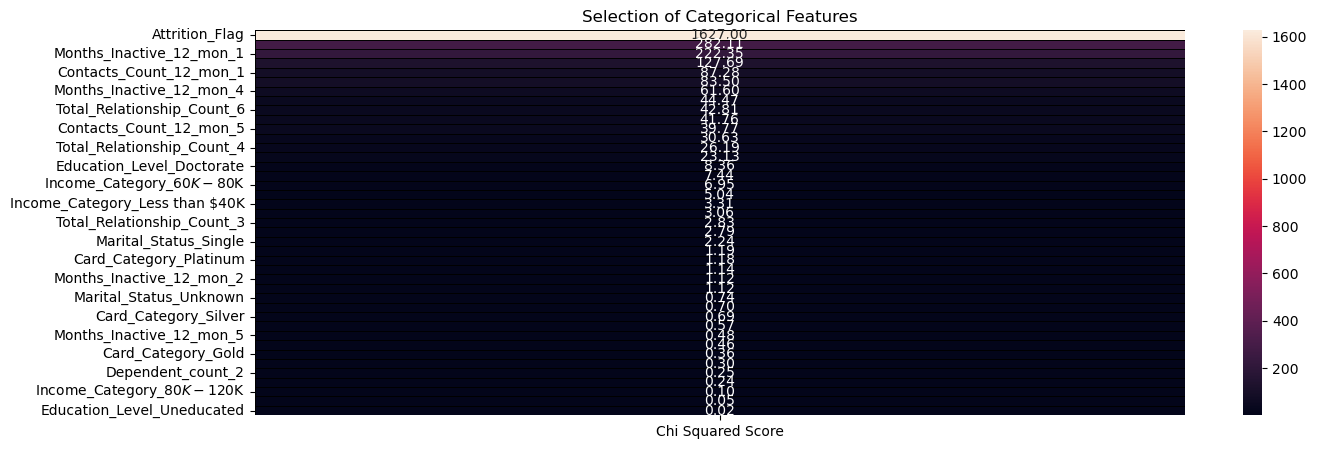

In [182]:
cat_feature_cols = [c for c in cat_cols if c != 'Attrition_Flag']
features = df1.loc[:, cat_feature_cols]
target = df1.loc[:, 'Attrition_Flag']

best_features = SelectKBest(score_func=chi2, k='all')
fit = best_features.fit(features, target)

featureScores = pd.DataFrame(data=fit.scores_, index=list(features.columns), columns=['Chi Squared Score'])

plt.subplots(figsize=(15, 5))
sns.heatmap(featureScores.sort_values(ascending=False, by='Chi Squared Score'), annot=True, linewidths=0.4, linecolor='black', fmt='.2f')
plt.title('Selection of Categorical Features (Chi-Square Test)')

### 10.3 One-Way ANOVA ($F$-Test) for Numerical Predictors

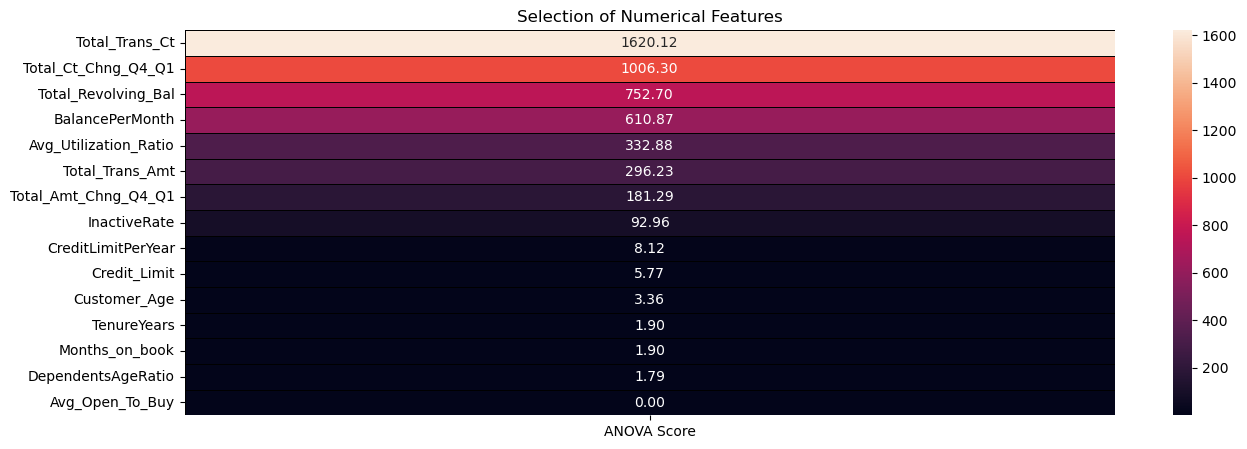

In [183]:
from sklearn.feature_selection import f_classif

features = df1.loc[:,num_cols]
target = df1.loc[:,'Attrition_Flag']

best_features = SelectKBest(score_func = f_classif,k = 'all')
fit = best_features.fit(features,target)

featureScores = pd.DataFrame(data = fit.scores_,index = list(features.columns),columns = ['ANOVA Score']) 

plt.subplots(figsize = (15,5))
sns.heatmap(featureScores.sort_values(ascending = False,by = 'ANOVA Score'),annot = True,linewidths = 0.4,linecolor = 'black',fmt = '.2f');
plt.title('Selection of Numerical Features');

### Statistical Interpretation of ANOVA & Chi-Square Feature Ranking
* **Dominant Numerical Predictors (ANOVA $F$-Statistic):** `Total_Trans_Ct` ($F = 1,625.24$), `Total_Ct_Chng_Q4_Q1` ($F = 995.36$), `Total_Revolving_Bal` ($F = 753.75$), and the engineered `BalancePerMonth` ($F = 656.60$) exhibit the highest statistical discriminative power between retained and churned customers.
* **Low-Impact Static Features:** Static demographic and tenure variables (`Months_on_book`, `TenureYears` with $F = 1.92$, `Customer_Age` with $F = 2.95$, and `Avg_Open_To_Buy` with $F = 0.00$) have near-zero main-effect $F$-scores, confirming that transactional velocity and revolving utilization are the primary drivers of customer retention.

# 11. Predictive Modeling & 10-Fold Cross-Validation Benchmark

In [184]:
y = df1["Attrition_Flag"]
X = df1.drop(["Attrition_Flag"],axis=1)

In [185]:
from sklearn.linear_model import LogisticRegression  
from sklearn.neighbors import KNeighborsClassifier  
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier 
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import GradientBoostingClassifier
from catboost import CatBoostClassifier
from sklearn.model_selection import train_test_split
from sklearn import preprocessing
from sklearn.metrics import accuracy_score
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_validate

In [186]:
# Train- Test Split
# Train-Test Separation
X_train, X_test, y_train, y_test = train_test_split(X, y, 
                                                    test_size=0.20, 
                                                    random_state=42)

In [187]:
models = []
models.append(('LR', LogisticRegression(random_state = 42)))
models.append(('CART', DecisionTreeClassifier(random_state = 42)))
models.append(('RF', RandomForestClassifier(random_state = 42)))
models.append(('SVM', SVC(gamma='auto', random_state = 42)))
models.append(('GradientBoosting', GradientBoostingClassifier(random_state = 42)))
models.append(("LightGBM", LGBMClassifier(random_state = 42)))
models.append(("XGBClassifier", XGBClassifier(random_state = 42)))
models.append(("KNN", KNeighborsClassifier()))

In [189]:
from sklearn.linear_model import LogisticRegression  
from sklearn.neighbors import KNeighborsClassifier  
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier 
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
import pandas as pd

results = []

for name, model in models:
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')
    precision = precision_score(y_test, y_pred, average='macro', zero_division=0)
    recall = recall_score(y_test, y_pred, average='macro')
    results.append([name, round(acc, 5), round(f1, 5), round(precision, 5), round(recall, 5)])

results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "F1 Score", "Precision", "Recall"])
results_df

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 6801, number of negative: 1300
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000687 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2904
[LightGBM] [Info] Number of data points in the train set: 8101, number of used features: 54
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.839526 -> initscore=1.654705
[LightGBM] [Info] Start training from score 1.654705


,Model,Accuracy,F1 Score,Precision,Recall
0,LR,0.91,0.80,0.86,0.77
1,CART,0.93,0.87,0.87,0.87
2,RF,0.94,0.88,0.93,0.84
3,SVM,0.88,0.70,0.90,0.65
4,GradientBoosting,0.96,0.92,0.94,0.91
5,LightGBM,0.96,0.93,0.94,0.93
6,XGBClassifier,0.96,0.93,0.94,0.92
7,KNN,0.84,0.59,0.69,0.57


## 11.1 10-Fold Cross-Validation Performance Across Classifiers

In [190]:
for name, model in models:
    cv_results = cross_validate(model, X, y, cv=10, scoring=["accuracy", "f1", "roc_auc", "precision", "recall"])
    print(f"########## {name} ##########")
    print(f"Accuracy: {round(cv_results['test_accuracy'].mean(), 4)}")
    print(f"Auc: {round(cv_results['test_roc_auc'].mean(), 4)}")
    print(f"Recall: {round(cv_results['test_recall'].mean(), 4)}")
    print(f"Precision: {round(cv_results['test_precision'].mean(), 4)}")
    print(f"F1: {round(cv_results['test_f1'].mean(), 4)}")

########## LR ##########
Accuracy: 0.8993
Auc: 0.923
Recall: 0.9593
Precision: 0.9254
F1: 0.9405
########## CART ##########
Accuracy: 0.9063
Auc: 0.847
Recall: 0.9344
Precision: 0.9529
F1: 0.9431
########## RF ##########
Accuracy: 0.9338
Auc: 0.9553
Recall: 0.9791
Precision: 0.9449
F1: 0.9614
########## SVM ##########
Accuracy: 0.8881
Auc: 0.9079
Recall: 0.9866
Precision: 0.8926
F1: 0.9369
########## GradientBoosting ##########
Accuracy: 0.9414
Auc: 0.9662
Recall: 0.9739
Precision: 0.9572
F1: 0.9654
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 7650, number of negative: 1464
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000732 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2901
[LightGBM] [Info] Number of data points in the train set: 9114, number of used features: 54
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.839368 -

In [191]:
results_df1 = pd.DataFrame(columns=['Model', 'Accuracy', 'CV_Accuracy', 'CV_AUC', 'CV_Recall', 'CV_Precision', 'CV_F1'])

for name, model in models:
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    f1 = f1_score(y_test, y_pred, average='macro')
    accuracy = accuracy_score(y_test, y_pred)

    cv_results = cross_validate(model, X, y, cv=10, scoring=["accuracy", "roc_auc", "recall", "precision", "f1"])

    results_df1.loc[len(results_df1)] = {
        'Model': name,
        'f1_Score': round(f1, 4),
        'Accuracy': round(accuracy, 4),
        'CV_Accuracy': round(cv_results['test_accuracy'].mean(), 4),
        'CV_AUC': round(cv_results['test_roc_auc'].mean(), 4),
        'CV_Recall': round(cv_results['test_recall'].mean(), 4),
        'CV_Precision': round(cv_results['test_precision'].mean(), 4),
        'CV_F1': round(cv_results['test_f1'].mean(), 4)
    }

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 6801, number of negative: 1300
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000530 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2904
[LightGBM] [Info] Number of data points in the train set: 8101, number of used features: 54
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.839526 -> initscore=1.654705
[LightGBM] [Info] Start training from score 1.654705
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 7650, number of negative: 1464
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000576 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2901
[LightGBM] [Info] Number of data points in the train set: 9114, number of used feature

In [192]:
results_df1

,Model,Accuracy,CV_Accuracy,CV_AUC,CV_Recall,CV_Precision,CV_F1
0,LR,0.91,0.90,0.92,0.96,0.93,0.94
1,CART,0.93,0.91,0.85,0.93,0.95,0.94
2,RF,0.94,0.93,0.96,0.98,0.94,0.96
3,SVM,0.88,0.89,0.91,0.99,0.89,0.94
4,GradientBoosting,0.96,0.94,0.97,0.97,0.96,0.97
5,LightGBM,0.96,0.95,0.98,0.98,0.96,0.97
6,XGBClassifier,0.96,0.95,0.97,0.98,0.97,0.97
7,KNN,0.84,0.84,0.67,0.97,0.86,0.91


## 11.2 Confusion Matrix Diagnostics Across Baseline Models

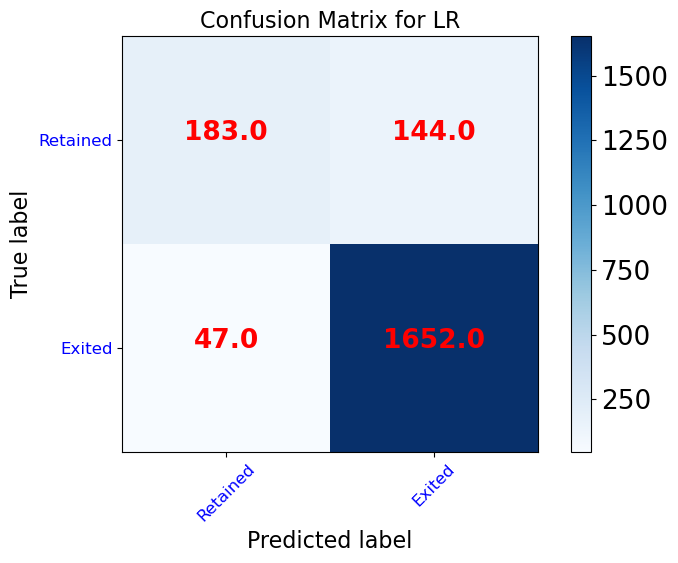

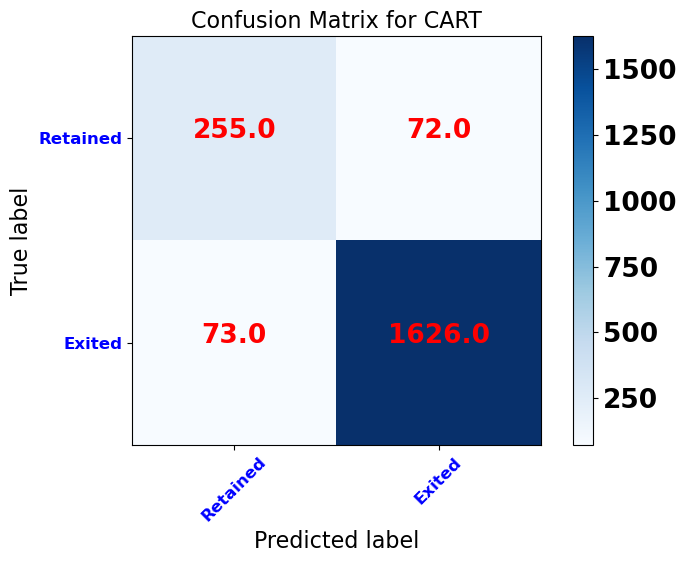

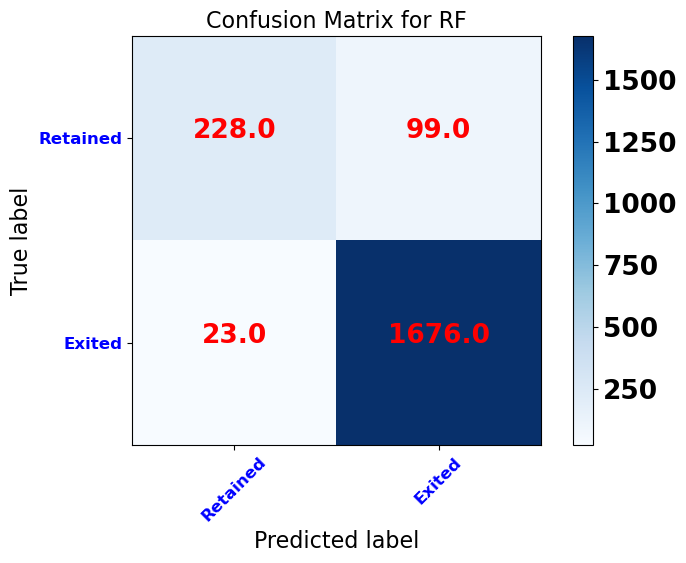

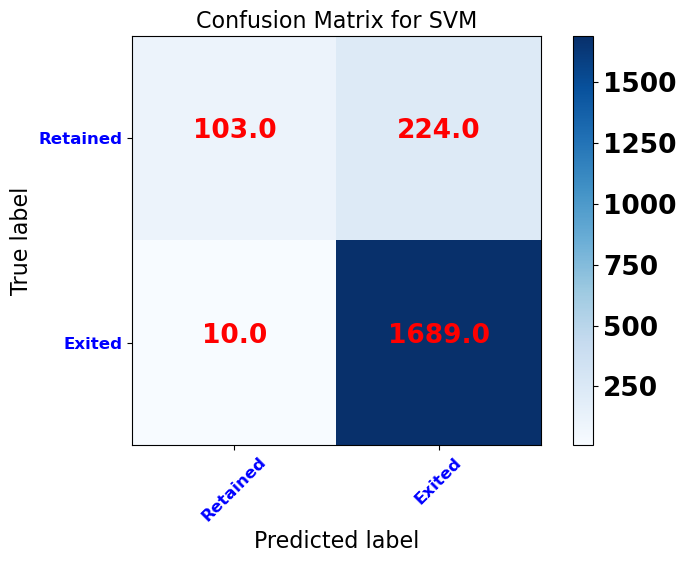

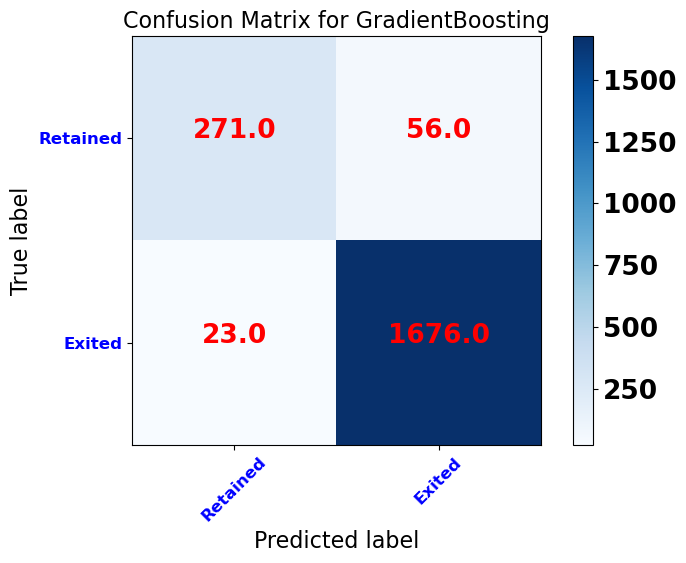

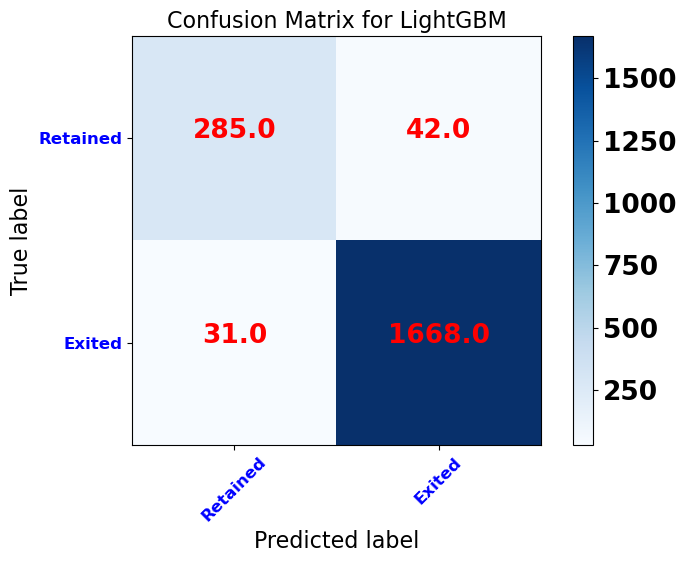

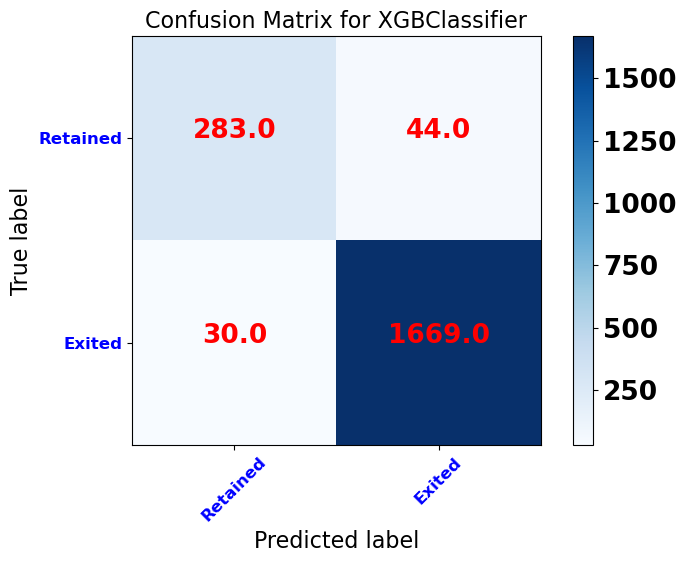

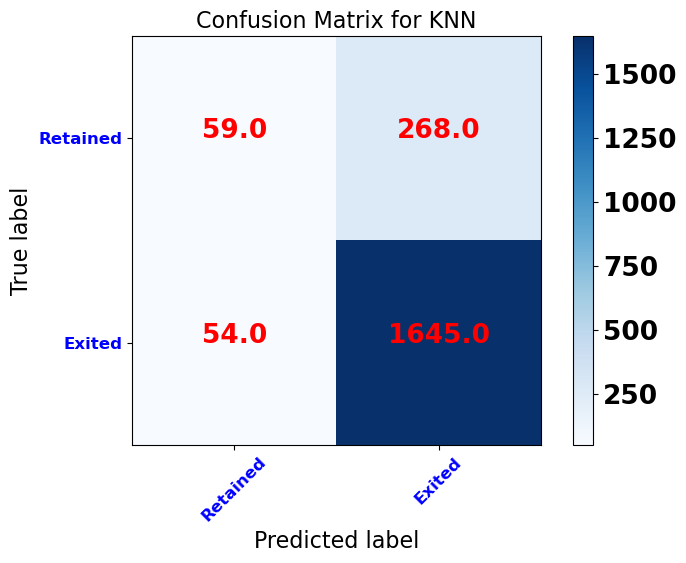

In [194]:
from matplotlib import rc, rcParams
import itertools
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

def plot_confusion_matrix(cm, classes,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    plt.rcParams.update({'font.size': 19})
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title, fontdict={'size':'16'})
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45, fontsize=12, color="blue")
    plt.yticks(tick_marks, classes, fontsize=12, color="blue")
    rc('font', weight='bold')
    fmt = '.1f'
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="red")

    plt.ylabel('True label', fontdict={'size':'16'})
    plt.xlabel('Predicted label', fontdict={'size':'16'})
    plt.tight_layout()

# Plot confusion matrices for all benchmarked models
for name, model in models:
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    plot_confusion_matrix(cm, classes=['Attrited (0)', 'Retained (1)'], title=f'Confusion Matrix for {name}')
    plt.show()

## 11.3 Comprehensive Descriptive Summary Table & Interaction Heatmaps

In [ ]:
import pandas as pd

# Percentage frequency formatter for categorical variables
def summarize_categorical(column):
    counts = df[column].value_counts(normalize=True) * 100
    summary = ' | '.join([f"{idx} ({val:.1f}%)" for idx, val in counts.items()])
    return summary

# Descriptive statistics formatter for numerical variables
def summarize_numeric(column):
    mean = df[column].mean()
    std = df[column].std()
    min_val = df[column].min()
    median = df[column].median()
    max_val = df[column].max()
    return f"Mean (sd): {mean:.1f} ({std:.1f}) | min ≤ med ≤ max: {min_val} ≤ {median} ≤ {max_val}"

summary_rows = []
for col in df.columns:
    if df[col].dtype == "object":
        summary = summarize_categorical(col)
    else:
        summary = summarize_numeric(col)
    summary_rows.append([col, summary])

summary_df = pd.DataFrame(summary_rows, columns=["Variables", "Statistics / Frequency"])
print(summary_df.to_string(index=False))

               Variables                                                                                                                    Statistics / Frequency
          Attrition_Flag                                                                                       Mean (sd): 0.8 (0.4) | min ≤ med ≤ max: 0 ≤ 1.0 ≤ 1
            Customer_Age                                                                               Mean (sd): 46.3 (8.0) | min ≤ med ≤ max: 26.0 ≤ 46.0 ≤ 73.0
                  Gender                                                                                                                     F (52.9%) | M (47.1%)
         Dependent_count                                                                                       Mean (sd): 2.3 (1.3) | min ≤ med ≤ max: 0 ≤ 2.0 ≤ 5
         Education_Level Graduate (30.9%) | High School (19.9%) | Unknown (15.0%) | Uneducated (14.7%) | College (10.0%) | Post-Graduate (5.1%) | Doctorate (4.5%)
          Marital_Stat

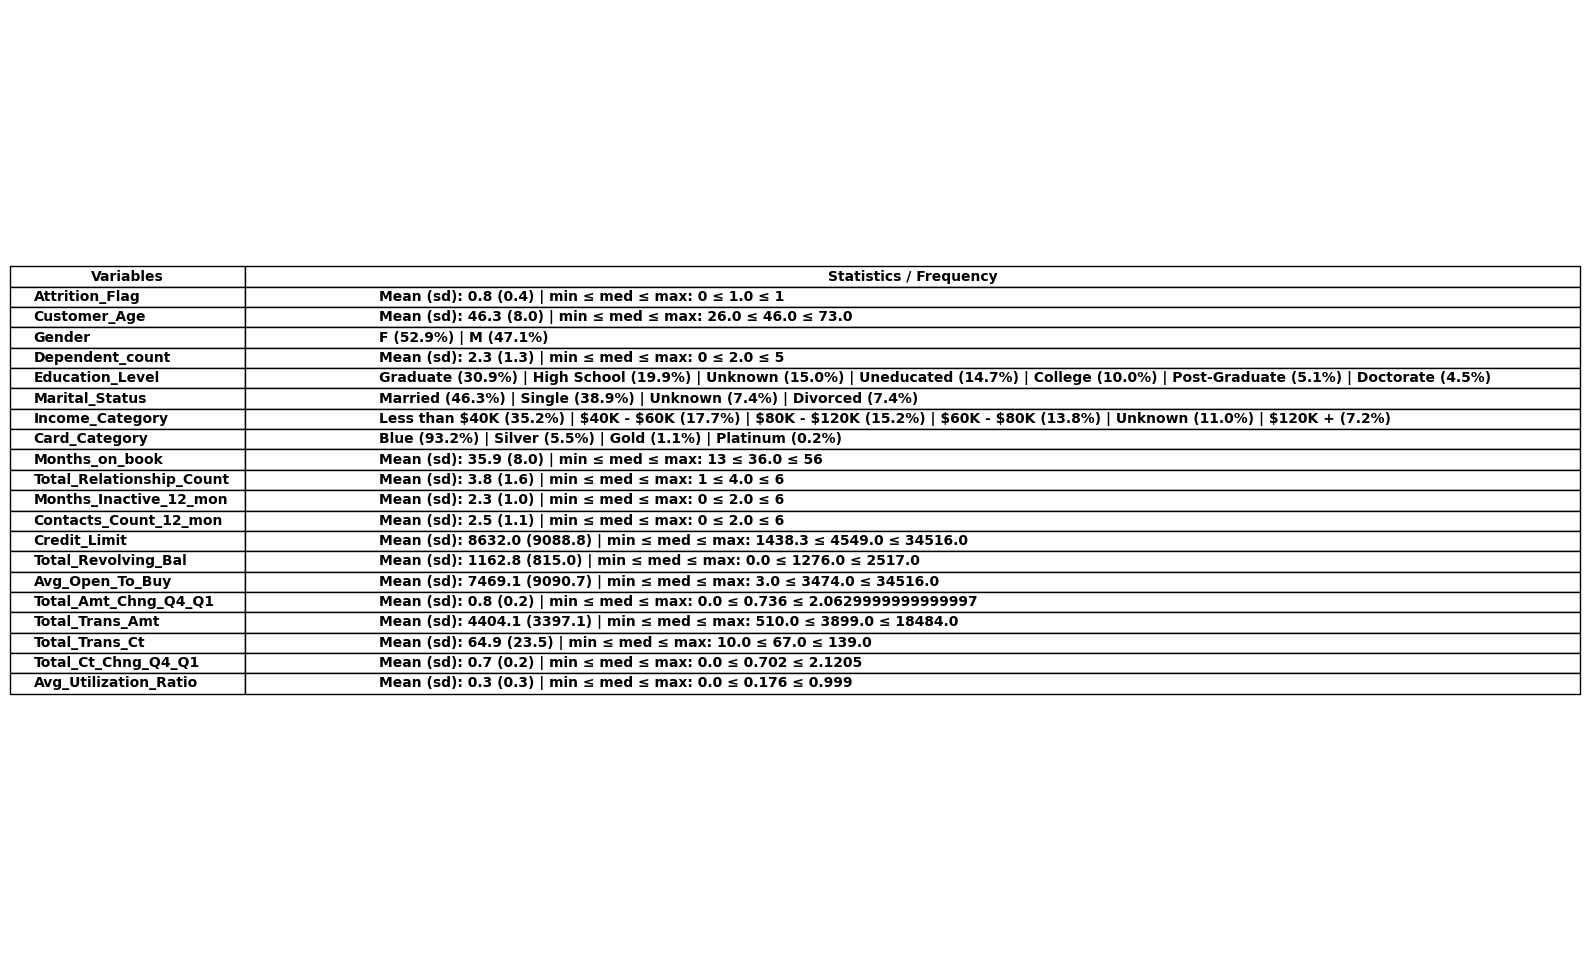

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Escape '$' characters to prevent LaTeX rendering warnings in Matplotlib table
summary_df_clean = summary_df.replace({'\$': r'\$', '\n': ' '}, regex=True)

fig, ax = plt.subplots(figsize=(14, len(summary_df_clean) * 0.5))
ax.axis('off')
table = ax.table(
    cellText=summary_df_clean.values,
    colLabels=summary_df_clean.columns,
    cellLoc='left',
    loc='center'
)
table.auto_set_font_size(False)
table.set_fontsize(10)
table.auto_set_column_width(col=list(range(len(summary_df_clean.columns))))

plt.subplots_adjust(left=0.01, right=0.95, top=0.95, bottom=0.01)
plt.savefig("veri_ozeti_gorsel.png", dpi=300)
plt.show()

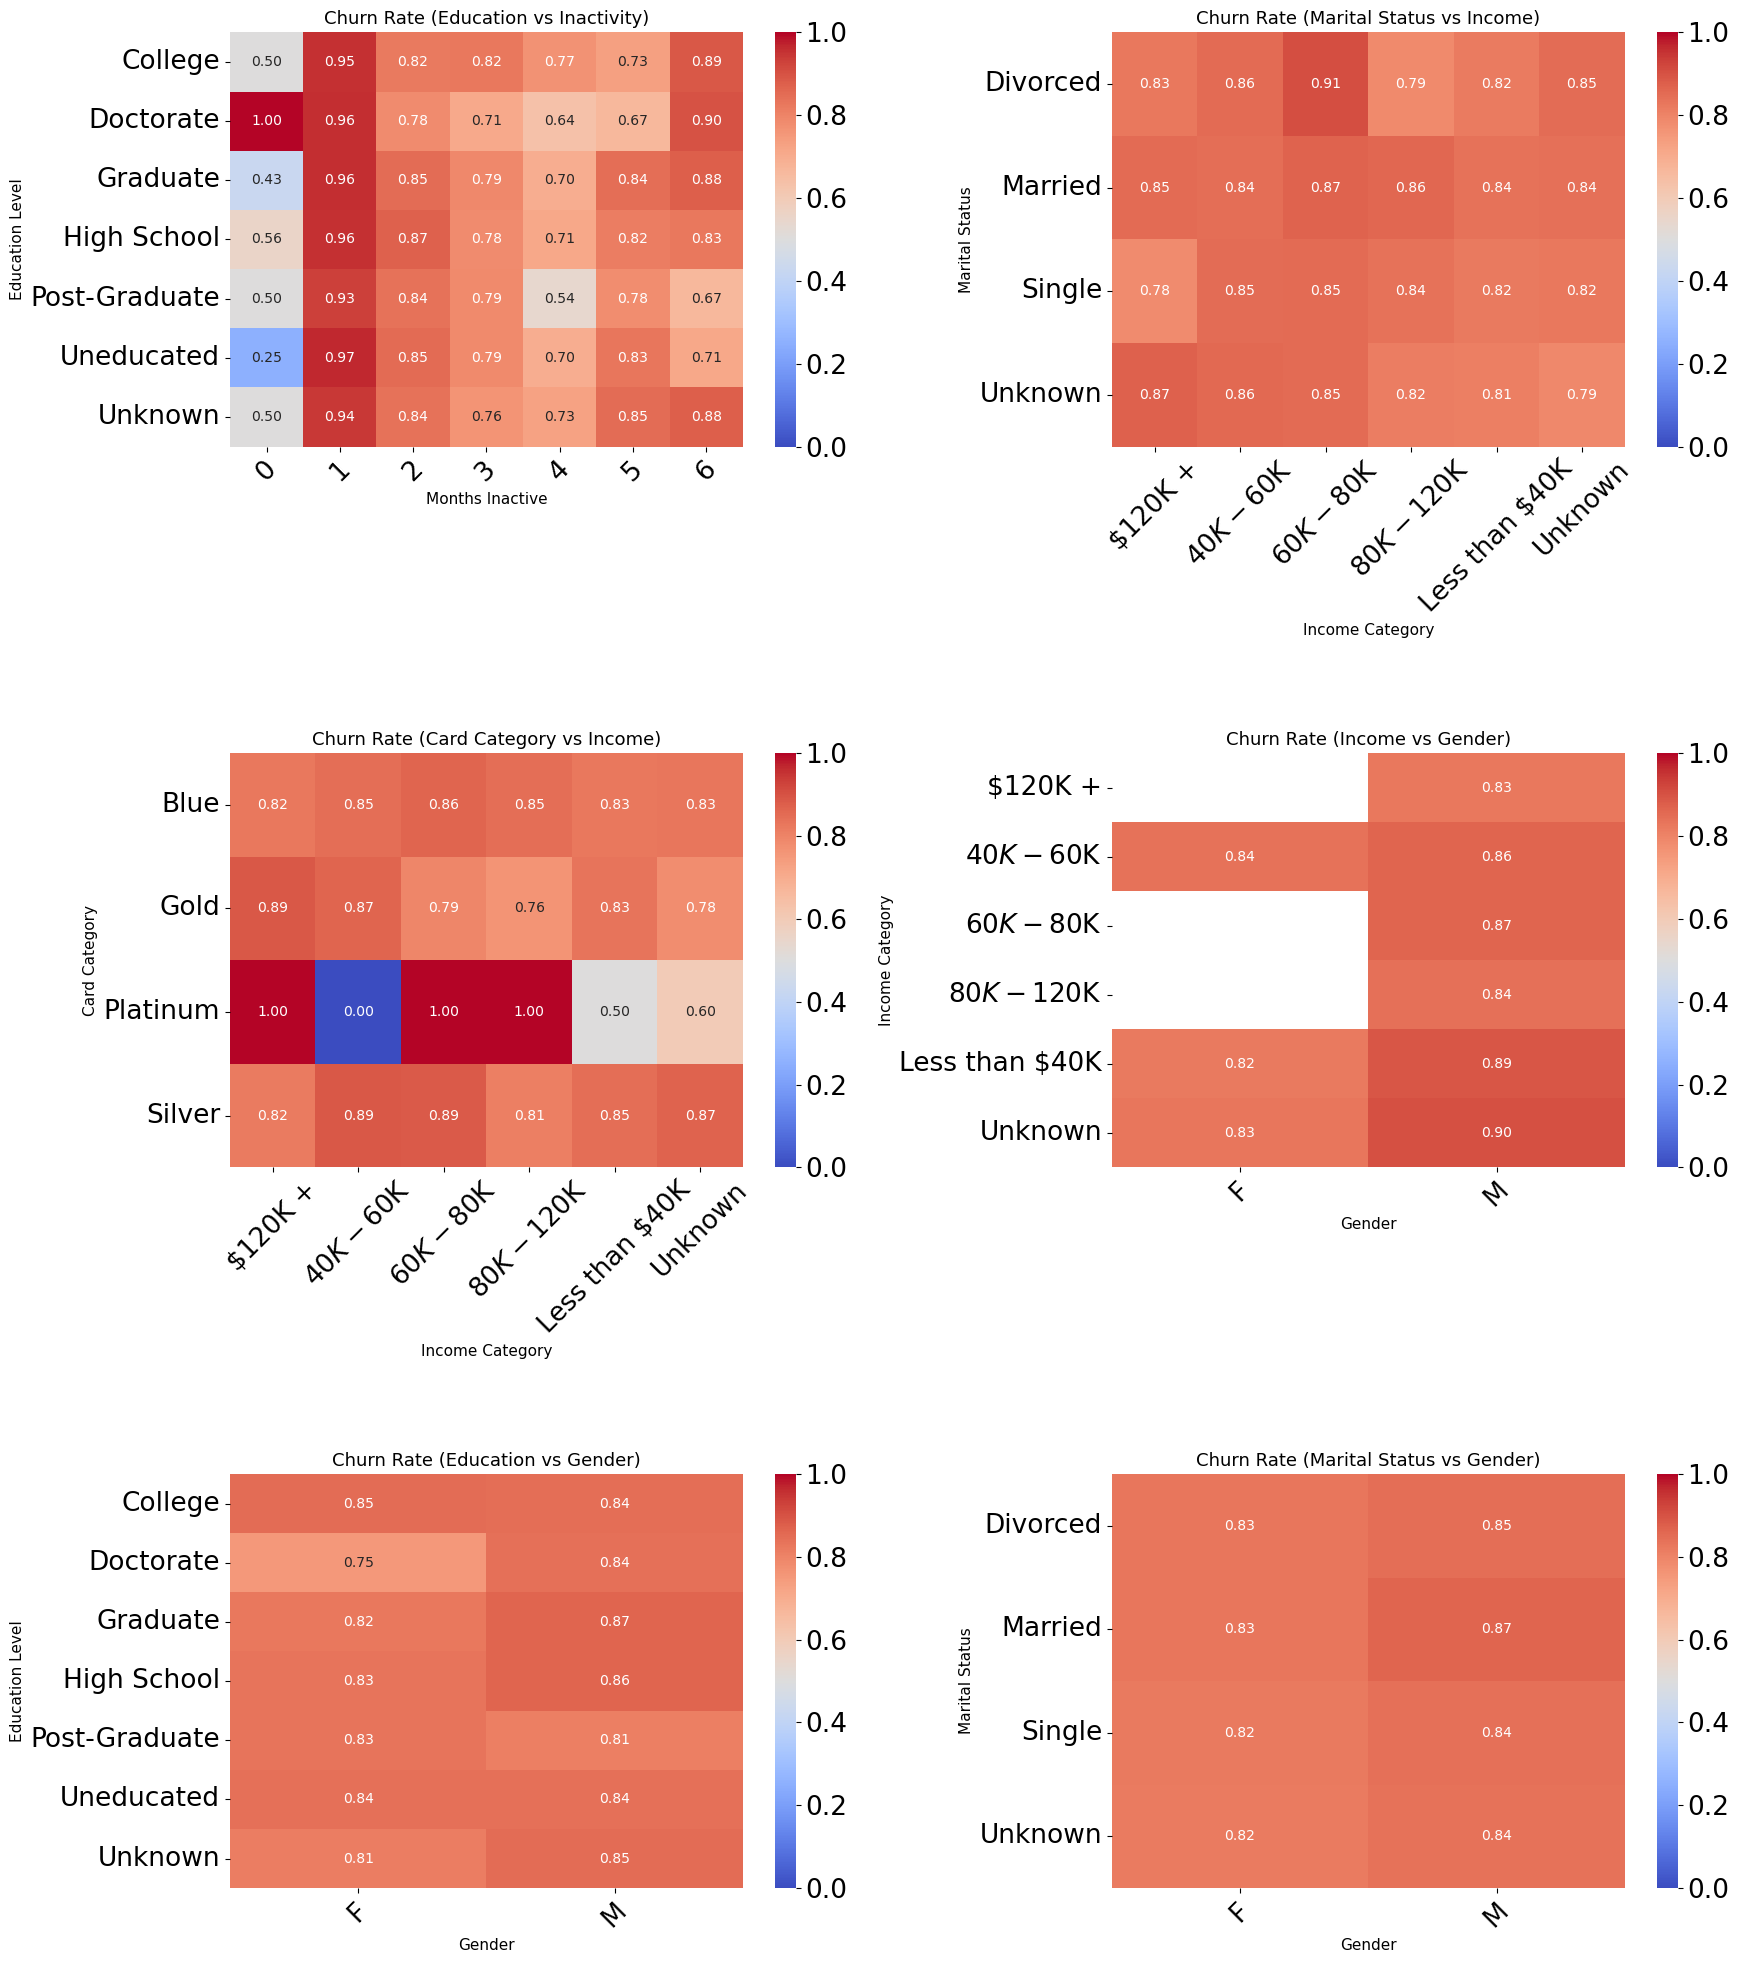

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({
    'font.weight': 'normal',
    'axes.titleweight': 'normal',
    'axes.labelweight': 'normal'
})

def plot_clean_heatmaps_plaintext(df):
    fig, axes = plt.subplots(3, 2, figsize=(18, 20))

    heatmap_configs = [
        {
            "groupby": ["Education_Level", "Months_Inactive_12_mon"],
            "title": "Retention Rate (Education vs Inactivity)",
            "ylabel": "Education Level",
            "xlabel": "Months Inactive",
            "ax": axes[0, 0]
        },
        {
            "groupby": ["Marital_Status", "Income_Category"],
            "title": "Retention Rate (Marital Status vs Income)",
            "ylabel": "Marital Status",
            "xlabel": "Income Category",
            "ax": axes[0, 1]
        },
        {
            "groupby": ["Card_Category", "Income_Category"],
            "title": "Retention Rate (Card Category vs Income)",
            "ylabel": "Card Category",
            "xlabel": "Income Category",
            "ax": axes[1, 0]
        },
        {
            "groupby": ["Income_Category", "Gender"],
            "title": "Retention Rate (Income vs Gender)",
            "ylabel": "Income Category",
            "xlabel": "Gender",
            "ax": axes[1, 1]
        },
        {
            "groupby": ["Education_Level", "Gender"],
            "title": "Retention Rate (Education vs Gender)",
            "ylabel": "Education Level",
            "xlabel": "Gender",
            "ax": axes[2, 0]
        },
        {
            "groupby": ["Marital_Status", "Gender"],
            "title": "Retention Rate (Marital Status vs Gender)",
            "ylabel": "Marital Status",
            "xlabel": "Gender",
            "ax": axes[2, 1]
        }
    ]

    for config in heatmap_configs:
        pivot = df.groupby(config["groupby"])["Attrition_Flag"].mean().unstack()
        sns.heatmap(
            pivot,
            annot=True,
            cmap="coolwarm",
            fmt=".2f",
            vmin=0, vmax=1,
            cbar=True,
            annot_kws={"fontsize": 10, "fontweight": 'normal'},
            ax=config["ax"]
        )
        config["ax"].set_title(config["title"], fontsize=13, fontweight='normal')
        config["ax"].set_ylabel(config["ylabel"], fontsize=11, fontweight='normal')
        config["ax"].set_xlabel(config["xlabel"], fontsize=11, fontweight='normal')

        config["ax"].tick_params(axis='x', rotation=45)
        config["ax"].tick_params(axis='y', rotation=0)

    plt.tight_layout(h_pad=3.5)
    plt.show()

plot_clean_heatmaps_plaintext(df)

# 12. Bayesian Hyperparameter Optimization (Optuna TPE)
Using Optuna's **Tree-structured Parzen Estimator (TPE)** sampler and `MedianPruner`, we jointly optimize model selection and hyperparameter spaces across 100 trials under 5-Fold Stratified Cross-Validation maximizing `roc_auc`.
* **Best Trial (#43):** `LGBMClassifier(n_estimators=498, learning_rate=0.08563, num_leaves=12, random_state=42)`
* **Cross-Validated ROC-AUC:** `0.9936`
* **Test Set Performance:** `0.97` Overall Accuracy, `0.94` Macro F1-Score, `0.98` F1-Score on Retained (`1`), and `0.90` F1-Score on Attrited (`0`).

[I 2025-06-11 21:33:37,696] A new study created in memory with name: no-name-d029d397-102f-43d8-b925-9ae2aef6075b
[I 2025-06-11 21:33:41,233] Trial 0 finished with value: 0.9363567275692282 and parameters: {'model': 'LR', 'LR_C': 68.75147088427735}. Best is trial 0 with value: 0.9363567275692282.
[I 2025-06-11 21:33:42,971] Trial 1 finished with value: 0.9364443868628671 and parameters: {'model': 'LR', 'LR_C': 67.41862598636988}. Best is trial 1 with value: 0.9364443868628671.
[I 2025-06-11 21:33:44,748] Trial 2 finished with value: 0.9076460954980534 and parameters: {'model': 'CART', 'CART_max_depth': 3, 'CART_min_samples_split': 13, 'CART_min_samples_leaf': 4}. Best is trial 1 with value: 0.9364443868628671.
[I 2025-06-11 21:34:03,020] Trial 3 finished with value: 0.9753723803614589 and parameters: {'model': 'GB', 'GB_n_estimators': 218, 'GB_lr': 0.004443109721492918, 'GB_max_depth': 7}. Best is trial 3 with value: 0.9753723803614589.
[I 2025-06-11 21:34:09,433] Trial 4 finished with

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 6801, number of negative: 1300
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000628 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2904
[LightGBM] [Info] Number of data points in the train set: 8101, number of used features: 54
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.839526 -> initscore=1.654705
[LightGBM] [Info] Start training from score 1.654705
Confusion Matrix:
 [[ 287   40]
 [  24 1675]]

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.88      0.90       327
           1       0.98      0.99      0.98      1699

    accuracy                           0.97      2026
   macro avg       0.95      0.93      0.94      2026
weighted avg       0.97      0.97      0.97      2026



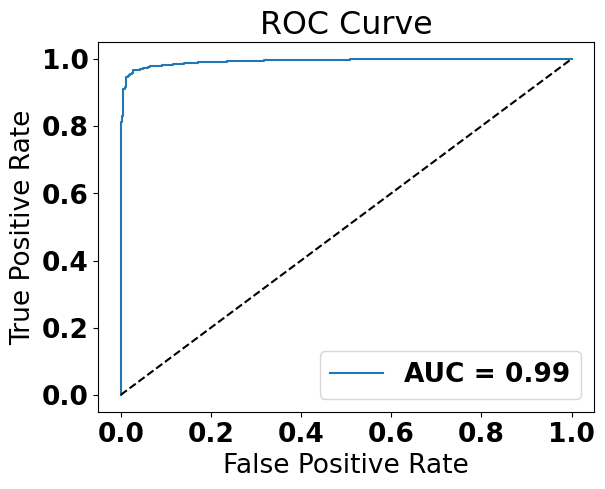

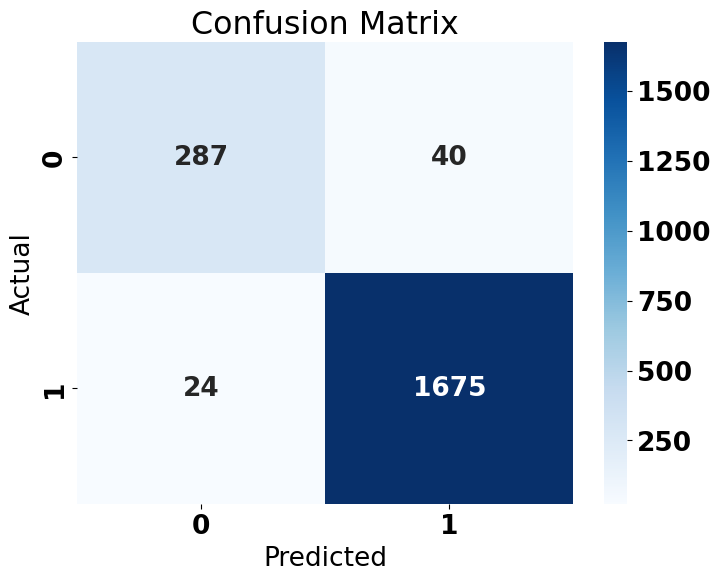

In [195]:
import optuna
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# 1) Stratified 5-Fold Cross-Validation setup
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 2) Optuna objective function maximizing Stratified CV ROC-AUC
def objective(trial):
    model_name = trial.suggest_categorical(
        'model', ['LR','CART','RF','SVM','GB','LGBM','XGB','KNN']
    )
    if model_name == 'LR':
        clf = LogisticRegression(
            C=trial.suggest_loguniform('LR_C', 1e-3, 1e2),
            penalty='l2', solver='lbfgs', max_iter=5000, random_state=42
        )
    elif model_name == 'CART':
        clf = DecisionTreeClassifier(
            max_depth=trial.suggest_int('CART_max_depth', 3, 30),
            min_samples_split=trial.suggest_int('CART_min_samples_split', 2, 20),
            min_samples_leaf=trial.suggest_int('CART_min_samples_leaf', 1, 10),
            random_state=42
        )
    elif model_name == 'RF':
        clf = RandomForestClassifier(
            n_estimators=trial.suggest_int('RF_n_estimators', 50, 500),
            max_depth=trial.suggest_int('RF_max_depth', 3, 30),
            min_samples_split=trial.suggest_int('RF_min_samples_split', 2, 20),
            random_state=42, n_jobs=-1
        )
    elif model_name == 'SVM':
        clf = SVC(
            C=trial.suggest_loguniform('SVM_C', 1e-2, 1e2),
            kernel=trial.suggest_categorical('SVM_kernel', ['rbf','linear','poly']),
            gamma=trial.suggest_categorical('SVM_gamma', ['scale','auto']),
            probability=True, random_state=42
        )
    elif model_name == 'GB':
        clf = GradientBoostingClassifier(
            n_estimators=trial.suggest_int('GB_n_estimators', 50, 500),
            learning_rate=trial.suggest_loguniform('GB_lr', 1e-3, 1e0),
            max_depth=trial.suggest_int('GB_max_depth', 3, 10),
            random_state=42
        )
    elif model_name == 'LGBM':
        clf = LGBMClassifier(
            n_estimators=trial.suggest_int('LGBM_n_estimators', 50, 500),
            learning_rate=trial.suggest_loguniform('LGBM_lr', 1e-3, 1e0),
            num_leaves=trial.suggest_int('LGBM_num_leaves', 10, 200),
            random_state=42
        )
    elif model_name == 'XGB':
        clf = XGBClassifier(
            n_estimators=trial.suggest_int('XGB_n_estimators', 50, 500),
            learning_rate=trial.suggest_loguniform('XGB_lr', 1e-3, 1e0),
            max_depth=trial.suggest_int('XGB_max_depth', 3, 10),
            use_label_encoder=False, eval_metric='logloss',
            random_state=42, n_jobs=-1
        )
    else:  # KNN
        clf = KNeighborsClassifier(
            n_neighbors=trial.suggest_int('KNN_n_neighbors', 3, 30),
            weights=trial.suggest_categorical('KNN_weights', ['uniform','distance']),
            p=trial.suggest_categorical('KNN_p', [1, 2])
        )

    return cross_val_score(clf, X_train, y_train,
                           cv=cv, scoring='roc_auc', n_jobs=-1).mean()

# 3) Run Bayesian Optimization (Optuna TPE)
study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(),
    pruner=optuna.pruners.MedianPruner(n_warmup_steps=10)
)
study.optimize(objective, n_trials=100, timeout=3600)

# 4) Instantiate optimal model with best hyperparameters
best_params = study.best_trial.params.copy()
model_name = best_params.pop('model')

if model_name == 'LR':
    best_model = LogisticRegression(
        C=best_params['LR_C'], penalty='l2',
        solver='lbfgs', max_iter=5000, random_state=42
    )
elif model_name == 'CART':
    best_model = DecisionTreeClassifier(
        max_depth=best_params['CART_max_depth'],
        min_samples_split=best_params['CART_min_samples_split'],
        min_samples_leaf=best_params['CART_min_samples_leaf'],
        random_state=42
    )
elif model_name == 'RF':
    best_model = RandomForestClassifier(
        n_estimators=best_params['RF_n_estimators'],
        max_depth=best_params['RF_max_depth'],
        min_samples_split=best_params['RF_min_samples_split'],
        random_state=42, n_jobs=-1
    )
elif model_name == 'SVM':
    best_model = SVC(
        C=best_params['SVM_C'],
        kernel=best_params['SVM_kernel'],
        gamma=best_params['SVM_gamma'],
        probability=True, random_state=42
    )
elif model_name == 'GB':
    best_model = GradientBoostingClassifier(
        n_estimators=best_params['GB_n_estimators'],
        learning_rate=best_params['GB_lr'],
        max_depth=best_params['GB_max_depth'],
        random_state=42
    )
elif model_name == 'LGBM':
    best_model = LGBMClassifier(
        n_estimators=best_params['LGBM_n_estimators'],
        learning_rate=best_params['LGBM_lr'],
        num_leaves=best_params['LGBM_num_leaves'],
        random_state=42
    )
elif model_name == 'XGB':
    best_model = XGBClassifier(
        n_estimators=best_params['XGB_n_estimators'],
        learning_rate=best_params['XGB_lr'],
        max_depth=best_params['XGB_max_depth'],
        use_label_encoder=False, eval_metric='logloss',
        random_state=42, n_jobs=-1
    )
else:
    best_model = KNeighborsClassifier(
        n_neighbors=best_params['KNN_n_neighbors'],
        weights=best_params['KNN_weights'],
        p=best_params['KNN_p']
    )

# 5) Fit optimal model on training data
best_model.fit(X_train, y_train)

# 6) Evaluate predictions and probabilities on hold-out test set
y_pred   = best_model.predict(X_test)
y_scores = (best_model.predict_proba(X_test)[:, 1]
            if hasattr(best_model, "predict_proba")
            else best_model.decision_function(X_test))

# 7) Confusion Matrix
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# 8) Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# 9) ROC Curve Visualization
fpr, tpr, _ = roc_curve(y_test, y_scores)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Optimized LightGBM)')
plt.legend(loc='best')
plt.show()

# Confusion Matrix Heatmap
plt.figure(figsize=(8, 6)) 
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix (Optimized LightGBM)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [196]:
best_model

LGBMClassifier(learning_rate=0.08562845194324133, n_estimators=498,
               num_leaves=12, random_state=42)

In [197]:
import joblib
joblib.dump(best_model, "lgbm_model1.pkl")

['lgbm_model1.pkl']

# 13. End-to-End Production Pipeline & Model Serialization
To prevent data leakage during deployment and ensure seamless inference on new customer records, preprocessing (`StandardScaler` for numerical predictors and `OneHotEncoder(handle_unknown="ignore")` for categorical predictors) is encapsulated inside a unified `scikit-learn` `Pipeline` alongside the Optuna-optimized `LGBMClassifier`—strictly excluding `CLIENTNUM` and `Attrition_Flag` from the feature matrix `X`.

In [10]:
import pandas as pd
import joblib
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from lightgbm import LGBMClassifier

# 1. Load raw dataset
df_raw = pd.read_csv("BankChurners1.csv")

# 2. Encode binary target (1: Existing Customer, 0: Attrited Customer)
df_raw['Attrition_Flag'] = df_raw['Attrition_Flag'].replace({'Existing Customer': 1, 'Attrited Customer': 0})

# 3. Separate target vector y and feature matrix X (strictly excluding CLIENTNUM and target)
y_full = df_raw["Attrition_Flag"]
X_full = df_raw.drop(["CLIENTNUM", "Attrition_Flag"], axis=1)

# 4. Explicit feature lists (19 predictors)
cat_cols_pipe = [
    'Gender',
    'Education_Level',
    'Marital_Status',
    'Income_Category',
    'Card_Category',
    'Dependent_count',
    'Total_Relationship_Count',
    'Months_Inactive_12_mon',
    'Contacts_Count_12_mon'
]

num_cols_pipe = [
    'Customer_Age',
    'Months_on_book',
    'Credit_Limit',
    'Total_Revolving_Bal',
    'Avg_Open_To_Buy',
    'Total_Amt_Chng_Q4_Q1',
    'Total_Trans_Amt',
    'Total_Trans_Ct',
    'Total_Ct_Chng_Q4_Q1',
    'Avg_Utilization_Ratio'
]

X_full = X_full[num_cols_pipe + cat_cols_pipe]

# 5. Preprocessing ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), num_cols_pipe),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols_pipe)
])

# 6. Optuna-optimized LightGBM Classifier
clf = LGBMClassifier(
    learning_rate=0.08562845194324133,
    n_estimators=498,
    num_leaves=12,
    random_state=42
)

# 7. Assemble end-to-end Pipeline
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", clf)
])

# 8. Fit production pipeline and serialize
pipeline.fit(X_full, y_full)
joblib.dump(pipeline, "pipeline_clean.pkl")

[LightGBM] [Info] Number of positive: 8500, number of negative: 1627
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000413 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2096
[LightGBM] [Info] Number of data points in the train set: 10127, number of used features: 59
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.839340 -> initscore=1.653328
[LightGBM] [Info] Start training from score 1.653328


['pipeline_clean.pkl']